## RS Oph Spectral Index Plot

In [1]:
#imports imports imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models
from scipy.stats import chisquare as CHI

In [2]:
#All of the data

#NEED to go and grab the data that Laura wants in as well

In [2]:
data = (

[59439.04,	2.6,	4.71,	0.14],
[59439.04,	3.4,	5.328,	0.093],
[59439.04,	5.1,	10.012,	0.058],
[59439.04,	7,	15.607,	0.057],
[59439.04,	13.7,	24.088,	0.055],
[59439.04,	16.5,	25.573,	0.059],
[59439.04,	31.1,	35.973,	0.14],
[59439.04,	34.9,	38.318,	0.16],
    
[59440.08,	2.6,	18.206,	0.11],
[59440.08,	3.4,	23.366,	0.1],
[59440.08,	5.1,	33.454,	0.059],
[59440.08,	7,	39.663,	0.055],
[59440.08,	13.7,	40.939,	0.062],
[59440.08,	16.5,	41.636,	0.063],
[59440.08,	31.1,	44.762,	0.14],
[59440.08,	34.9,	46.68,	0.15],
			
[59443.99,	2.6,	68.929,	0.37],
[59443.99,	3.4,	73.933,	0.11],
[59443.99,	5.1,	67.597,	0.087],
[59443.99,	7,	58.65,	0.068],
[59443.99,	13.7,	47.847,	0.066],
[59443.99,	16.5,	46.81,	0.063],
[59443.99,	31.1,	48.13,	0.14],
[59443.99,	34.9,	49.924,	0.16],
			
[59446.01,	2.6,	88.695,	0.21],
[59446.01,	3.4,	78.259,	0.11],
[59446.01,	5.1,	60.457,	0.065],
[59446.01,	7,	50.875,	0.057],
[59446.01,	13.7,	43.692,	0.054],
[59446.01,	16.5,	42.418,	0.055],
[59446.01,	31.1,	46.076,	0.12],
[59446.01,	34.9,	48.49,	0.14],
			
[59446.99,	2.6,	84.443,	0.34],
[59446.99,	3.4,	82.034,	0.13],
[59446.99,	5.1,	63.977,	0.083],
[59446.99,	7,	51.883,	0.062],
[59446.99,	13.7,	41.854,	0.056],
[59446.99,	16.5,	40.83,	0.056],
[59446.99,	31.1,	43.653,	0.12],
[59446.99,	34.9,	45.965,	0.13],
			
[59451.01,	2.6,	92.534,	0.24],
[59451.01,	3.4,	83.135,	0.19],
[59451.01,	5.1,	61.832,	0.074],
[59451.01,	7,	52.291,	0.059],
[59451.01,	13.7,	44.133,	0.054],
[59451.01,	16.5,	42.894,	0.061],
[59451.01,	31.1,	47.067,	0.12],
[59451.01,	34.9,	48.103,	0.13],
			
[59461.01,	2.6,	94.467,	0.22],
[59461.01,	3.4,	85.812,	0.17],
[59461.01,	5.1,	65.115,	0.074],
[59461.01,	7,	57.617,	0.064],
[59461.01,	13.7,	54.102,	0.06],
[59461.01,	16.5,	54.536,	0.065],
[59461.01,	31.1,	70.776,	0.15],
[59461.01,	34.9,	77.042,	0.16],
			
[59463.02,	2.6,	88.638,	0.2],
[59463.02,	3.4,	80.579,	0.17],
[59463.02,	5.1,	60.766,	0.069],
[59463.02,	7,	56.003,	0.062],
[59463.02,	13.7,	51.457,	0.068],
[59463.02,	16.5,	54.259,	0.074],
[59463.02,	31.1,	75.224,	0.17],
[59463.02,	34.9,	82.831,	0.18],
			
[59466.04,	2.6,	58.862,	0.17],
[59466.04,	3.4,	58.434,	0.13],
[59466.04,	5.1,	54.499,	0.067],
[59466.04,	7,	54.364,	0.068],
			
[59467.99,	2.6,	81.96,	0.23],
[59467.99,	3.4,	75.044,	0.15],
[59467.99,	5.1,	60.253,	0.061],
[59467.99,	7,	55.839,	0.055],
[59467.99,	13.7,	55.46,	0.057],
[59467.99,	16.5,	57.657,	0.059],
[59467.99,	31.1,	85.302,	0.13],
[59467.99,	34.9,	94.908,	0.14],
			
[59470.01,	2.6,	74.216,	0.24],
[59470.01,	3.4,	67.992,	0.14],
[59470.01,	5.1,	56.608,	0.058],
[59470.01,	7,	54.465,	0.056],
[59470.01,	13.7,	56.891,	0.061],
[59470.01,	16.5,	60.279,	0.063],
[59470.01,	31.1,	92.384,	0.14],
[59470.01,	34.9,	103.52,	0.15],
			
[59487.96,	2.6,	65.358,	0.18],
[59487.96,	3.4,	60.804,	0.13],
[59487.96,	5.1,	49.879,	0.061],
[59487.96,	7,	46.096,	0.058],
[59487.96,	13.7,	51.336,	0.074],
[59487.96,	16.5,	55.64,	0.083],
[59487.96,	31.1,	92.061,	0.14],
[59487.96,	34.9,	103.31,	0.16],
			
[59510.94,	2.6,	27.414,	0.13],
[59510.94,	3.4,	30.985,	0.086],
[59510.94,	5.1,	36.454,	0.052],
[59510.94,	7,	38.595,	0.05],		
			
[59511.92,	2.6,	36.139,	0.13],
[59511.92,	3.4,	36.456,	0.11],
[59511.92,	5.1,	36.228,	0.053],
[59511.92,	7,	38.215,	0.053],
[59511.92,	13.7,	45.791,	0.053],
[59511.92,	16.5,	50.332,	0.052],
[59511.92,	31.1,	79.492,	0.12],
[59511.92,	34.9,	88.439,	0.13],
			
[59523.82,	2.6,	32.964,	0.13],
[59523.82,	3.4,	32.519,	0.092],
[59523.82,	5.1,	31.849,	0.053],
[59523.82,	7,	32.08,	0.049],
[59523.82,	13.7,	38.122,	0.049],
[59523.82,	16.5,	41.511,	0.05],
[59523.82,	31.1,	66.05,	0.11],
[59523.82,	34.9,	72.993,	0.12],
			
[59574.76,	2.6,	17.902,	0.2],
[59574.76,	3.4,	17.739,	0.18],
[59574.76,	5.1,	17.481,	0.064],
[59574.76,	7,	19.527,	0.06],
[59574.76,	13.7,	25.248,	0.067],
[59574.76,	16.5,	26.955,	0.061],
[59574.76,	31.1,	42.236,	0.34],
[59574.76,	34.9,	47.137,	0.35],
			
[59588.66,	2.6,	24.59,	0.16],
[59588.66,	3.4,	22.702,	0.14],
[59588.66,	5.1,	18.554,	0.06],
[59588.66,	7,	18.619,	0.051],
[59588.66,	13.7,	21.6,	0.051],
[59588.66,	16.5,	22.164,	0.053],
[59588.66,	31.1,	26.488,	0.1],
[59588.66,	34.9,	27.475,	0.11],
			
[59590.61,	2.6,	24.388,	0.21],
[59590.61,	3.4,	22.617,	0.11],
[59590.61,	5.1,	19.794,	0.062],
[59590.61,	7,	19.169,	0.052],
[59590.61,	13.7,	21.908,	0.051],
[59590.61,	16.5,	22.994,	0.047],
[59590.61,	31.1,	28.341,	0.11],
[59590.61,	34.9,	29.746,	0.12],
			
[59595.61,	2.6,	23.163,	0.16],
[59595.61,	3.4,	20.742,	0.13],
[59595.61,	5.1,	17.488,	0.056],
[59595.61,	7,	17.871,	0.057],
[59595.61,	13.7,	20.702,	0.05],
[59595.61,	16.5,	21.855,	0.048],
[59595.61,	31.1,	27.116,	0.11],
[59595.61,	34.9,	28.356,	0.11],
			
[60034.47,	2.6,	3.295,	0.17],
[60034.47,	3.4,	3.342,	0.12],
[60034.47,	5.1,	2.765,	0.052],
[60034.47,	7,	2.347,	0.049],
[60034.47,	13.7,	1.672,	0.05],
[60034.47,	16.5,	1.526,	0.051],
[60034.47,	31.1,	0.87,	0.1],
[60034.47,	34.9,	0.862,	0.11],
			
[60049.34,	2.6,	2.777,	0.17],
[60049.34,	3.4,	2.82,	0.078],
[60049.34,	5.1,	2.684,	0.053],
[60049.34,	7,	2.373,	0.046],
[60049.34,	13.7,	1.67,	0.048],
[60049.34,	16.5,	1.541,	0.048],
[60049.34,	31.1,	1.077,	0.11],
[60049.34,	34.9,	1.113,	0.12],
			
[60131.12,	2.6,	1.808,	0.017],
[60131.12,	3.4,	1.999,	0.014],
[60131.12,	5.1,	2.163,	0.016],
[60131.12,	7,	2.336,	0.018],
[60131.12,	13.7,	1.933,	0.02],
[60131.12,	16.5,	1.923,	0.022],
[60131.12,	31.1,	1.336,	0.066],
[60131.12,	34.9,	1.306,	0.079],
)

df =  pd.DataFrame(data, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

In [3]:

#For the data from uGMRT, they already had the error, data in band-2 (125−250 MHz), band-3
#(250−500 MHz), band-4 (550−850 MHz), and band-5 (1000−1460 MHz)
#and In addition to the errors on flux densities from task JMFIT, we add (in quadrature) a 10% error in bands-3, 4, and 5 and a 15% error in band-2 to account for the calibration uncertainties
#I went in and reversed this (for bands 3, 4 and 5 i multipled the error by 0.9, and for the band 2 I multiplied the error by 0.85)
#Using original_err = np.sqrt( err_stated**2 - (flux*0.1)**2 )
#The data from MeerKAT and LOFAR both had a error of 10% addded (Ruiter et al. 2023), using the same eq as above

#day 3
E0 = ([ 59437.7, 1284*0.001, 0.28, np.sqrt( 0.045**2 - (0.28*0.1)**2 ) ], #MeerKAT
      [59437.8, 816*0.001, 0.49, np.sqrt( 0.068**2 - (0.49*0.1)**2 )],) #MeerKAT
#day 5
E1 = ([ 59439.6, 1284*0.001, 1.7, np.sqrt( 0.18**2 - (1.7*0.1)**2 )], #MeerKAT
    [59439.04,	2.6,	4.71,	0.14],
[59439.04,	3.4,	5.328,	0.093],
[59439.04,	5.1,	10.012,	0.058],
[59439.04,	7,	15.607,	0.057],
[59439.04,	13.7,	24.088,	0.055],
[59439.04,	16.5,	25.573,	0.059],
[59439.04,	31.1,	35.973,	0.14],
[59439.04,	34.9,	38.318,	0.16],)

#day 6
E2 = ( [59440.6, 816*0.001, 1.4, np.sqrt( 0.16**2 - (1.4*0.1)**2 )], #MeerKAT
      [59440.6, 1284*0.001, 8.6, np.sqrt( 0.87**2 - (8.6*0.1)**2 ) ], #MeerKAT
    
[59440.08,	2.6,	18.206,	0.11],
[59440.08,	3.4,	23.366,	0.1],
[59440.08,	5.1,	33.454,	0.059],
[59440.08,	7,	39.663,	0.055],
[59440.08,	13.7,	40.939,	0.062],
[59440.08,	16.5,	41.636,	0.063],
[59440.08,	31.1,	44.762,	0.14],
[59440.08,	34.9,	46.68,	0.15],)

#day 10
E3 = ( [59444.8,816*0.001, 54.5, np.sqrt( 5.5**2 - (54.5*0.1)**2 )], #MeerKAT
      [59444.9, 1284*0.001, 70.5, np.sqrt( 7.1**2 - (70.5*0.1)**2 )], #MeerKAT
    
    [59443.99,	2.6,	68.929,	0.37],
[59443.99,	3.4,	73.933,	0.11],
[59443.99,	5.1,	67.597,	0.087],
[59443.99,	7,	58.65,	0.068],
[59443.99,	13.7,	47.847,	0.066],
[59443.99,	16.5,	46.81,	0.063],
[59443.99,	31.1,	48.13,	0.14],
[59443.99,	34.9,	49.924,	0.16],
)
#day 12
E4 = ([59446.01,	2.6,	88.695,	0.21],
[59446.01,	3.4,	78.259,	0.11],
[59446.01,	5.1,	60.457,	0.065],
[59446.01,	7,	50.875,	0.057],
[59446.01,	13.7,	43.692,	0.054],
[59446.01,	16.5,	42.418,	0.055],
[59446.01,	31.1,	46.076,	0.12],
[59446.01,	34.9,	48.49,	0.14],)

#day13
E5 = ([59446.99,	2.6,	84.443,	0.34],
[59446.99,	3.4,	82.034,	0.13],
[59446.99,	5.1,	63.977,	0.083],
[59446.99,	7,	51.883,	0.062],
[59446.99,	13.7,	41.854,	0.056],
[59446.99,	16.5,	40.83,	0.056],
[59446.99,	31.1,	43.653,	0.12],
[59446.99,	34.9,	45.965,	0.13],)

#day17
E6 = (			
[59451.01,	2.6,	92.534,	0.24],
[59451.01,	3.4,	83.135,	0.19],
[59451.01,	5.1,	61.832,	0.074],
[59451.01,	7,	52.291,	0.059],
[59451.01,	13.7,	44.133,	0.054],
[59451.01,	16.5,	42.894,	0.061],
[59451.01,	31.1,	47.067,	0.12],
[59451.01,	34.9,	48.103,	0.13],
			)
#day24
E6_5 = ([59458.6, 1284*0.001, 76.1, np.sqrt( np.abs(7.6**2 - (76.1*0.1)**2) )], #MeerKAT 
       [59458.6, 816*0.001, 78.7, np.sqrt( 7.9**2 - (78.7*0.1)**2 )], #MeerKAT
       [59458.7, 154*0.001, 39.9, np.sqrt( 5.7**2 - (39.9*0.1)**2 )],  #LOFAR
        [59459.53, 1.36, 85.1,  np.sqrt( 8.6**2 - (85.1*0.1)**2 ) ], #uGMRT, UT: 2021 Sep 02.53
        [59457.17, 0.69, 77.5,    np.sqrt( 8**2 - (77.5*0.1)**2 )] #uGMRT 2021 Aug 31.67 23.17 0.69 77.50 ± 8.00
       )


#day27
E7 = ([59461.01,	2.6,	94.467,	0.22],
[59461.01,	3.4,	85.812,	0.17],
[59461.01,	5.1,	65.115,	0.074],
[59461.01,	7,	57.617,	0.064],
[59461.01,	13.7,	54.102,	0.06],
[59461.01,	16.5,	54.536,	0.065],
[59461.01,	31.1,	70.776,	0.15],
[59461.01,	34.9,	77.042,	0.16],)

#day29
E8 = (
    [59462.51, .4, 73.1, np.sqrt( 11.2**2 - (73.1*0.1)**2 )], #uGMRT, 2021 Sep 05.51 28.01 0.40 73.10 ± 11.20
    [59463.02,	2.6,	88.638,	0.2],
[59463.02,	3.4,	80.579,	0.17],
[59463.02,	5.1,	60.766,	0.069],
[59463.02,	7,	56.003,	0.062],
[59463.02,	13.7,	51.457,	0.068],
[59463.02,	16.5,	54.259,	0.074],
[59463.02,	31.1,	75.224,	0.17],
[59463.02,	34.9,	82.831,	0.18],)

#day32
E9 = ([59466.04,	2.6,	58.862,	0.17],
[59466.04,	3.4,	58.434,	0.13],
[59466.04,	5.1,	54.499,	0.067],
[59466.04,	7,	54.364,	0.068],)

#day34
E10 = ( [ 59468.6, 816*0.001, 73.5, np.sqrt( 7.4**2 - (73.5*0.1)**2 )], #MeerKAT
    [ 59468.7, 1284*0.001, 70.8, np.sqrt( 7.1**2 - (70.8*0.1)**2 )], #MeerKAT
    [ 59468.7, 154*0.001, 64.4, np.sqrt( 7.6**2 - (64.4*0.1)**2 )], #LOFAR
    [59467.99,	2.6,	81.96,	0.23],
[59467.99,	3.4,	75.044,	0.15],
[59467.99,	5.1,	60.253,	0.061],
[59467.99,	7,	55.839,	0.055],
[59467.99,	13.7,	55.46,	0.057],
[59467.99,	16.5,	57.657,	0.059],
[59467.99,	31.1,	85.302,	0.13],
[59467.99,	34.9,	94.908,	0.14],)

#day36
E11 = ([59470.01,	2.6,	74.216,	0.24],
[59470.01,	3.4,	67.992,	0.14],
[59470.01,	5.1,	56.608,	0.058],
[59470.01,	7,	54.465,	0.056],
[59470.01,	13.7,	56.891,	0.061],
[59470.01,	16.5,	60.279,	0.063],
[59470.01,	31.1,	92.384,	0.14],
[59470.01,	34.9,	103.52,	0.15],
      [59471.73, 1.37, 61,  np.sqrt( 6.3**2 - (61*0.1)**2 )], #uGMRT, UT = 2021 Sep 14.73
#maybe?
       [59473.7, 0.46, 71.7,  np.sqrt( 7.8**2 - (71.7*0.1)**2 )], #uGMRT 2021 Sep 16.70 39.20 0.46 71.70 ± 7.80
       [59474.67, 0.69, 78,  np.sqrt( 7.9**2 - (78*0.1)**2 )], # uGMRT, 2021 Sep 17.67 40.17 0.69 78.00 ± 7.90
      )

#not including 
#2021 Sep 26.69 49.19 1.36 43.10 ± 4.70

#day54
E12 = ([ 59483.6, 1284*0.001, 66.8, np.sqrt( 6.7**2 - (66.8*0.1)**2 )], #MeerKAT
    [ 59483.6, 816*0.001, 72, np.sqrt( 7.2**2 - (72*0.1)**2 )], #MeerKAT
    [ 59483.6, 54*0.001,61.4, np.sqrt( 29.7**2 - (61.4*0.1)**2 ) ], #LOFAR
     #  [ 59483.7, 154*0.001,49.8, np.sqrt( 7.4**2 - (49.8*0.1)**2 ) ], #LOFAR
    [59487.96,	2.6,	65.358,	0.18],
[59487.96,	3.4,	60.804,	0.13],
[59487.96,	5.1,	49.879,	0.061],
[59487.96,	7,	46.096,	0.058],
[59487.96,	13.7,	51.336,	0.074],
[59487.96,	16.5,	55.64,	0.083],
[59487.96,	31.1,	92.061,	0.14],
[59487.96,	34.9,	103.31,	0.16],
      [59488.58, 0.69, 72.1, np.sqrt( 7.7**2 - (72.1*0.1)**2 )], #2021 Oct 01.58 54.08 0.69 72.10 ± 7.70
       [59487.62, 0.45, 80, np.sqrt( 8.1**2 - (80*0.1)**2 )], #uGMRT, 2021 Sep 30.62 53.12 0.45 80.00 ± 8.10
       [59487.53, 0.147, 33.2, np.sqrt( 8.2**2 - (33.2*0.1)**2 )], #uGMRT, band 2, 2021 Sep 30.53 53.03 0.147 33.20 ± 8.20
     # [59488.67, 1.36, 45.9, np.sqrt( 4.6**2 - (45.9*0.1)**2 )], #uGMRT, UT:2021 Sep 31.67 54.17 1.36 45.90 ± 4.60
      )

#didn't use
#2021 Oct 05.34 57.84 1.36 60.40 ± 6.00
#2021 Oct 03.42 55.92 0.46 75.80 ± 11.50


#day 61-65
E12_5 = (
    [59495.38, 0.145, 48.9, np.sqrt( 10.8**2 - (48.9*0.15)**2 )], #uGMRT, 2021 Oct 08.38 60.88 0.146 48.90 ± 10.80
    [59495.41, 0.66, 58.9, np.sqrt( 6.1**2 - (58.9*0.1)**2 )], #uGMRT, 2021 Oct 08.41 60.91 0.66 58.90 ± 6.10
    [59498.6,  816*0.001,  59.2,  np.sqrt( np.abs( 5.9**2 - (59.2*0.1)**2) )], #MeerKAT
 [59498.7,  1284*0.001,   53.6,  np.sqrt( 5.4**2 - (53.6*0.1)**2 )], #MeerKAT
[ 59499.6,  154*0.001,  52.0,  np.sqrt( 6.5**2 - (52*0.1)**2 )], #LOFAR
)

#day77
E13 = (			
[59510.94,	2.6,	27.414,	0.13],
[59510.94,	3.4,	30.985,	0.086],
[59510.94,	5.1,	36.454,	0.052],
[59510.94,	7,	38.595,	0.05],	)

#day78
E14 = (			
[59511.92,	2.6,	36.139,	0.13],
[59511.92,	3.4,	36.456,	0.11],
[59511.92,	5.1,	36.228,	0.053],
[59511.92,	7,	38.215,	0.053],
[59511.92,	13.7,	45.791,	0.053],
[59511.92,	16.5,	50.332,	0.052],
[59511.92,	31.1,	79.492,	0.12],
[59511.92,	34.9,	88.439,	0.13],)

#day90
E15 = (			
[59523.82,	2.6,	32.964,	0.13],
[59523.82,	3.4,	32.519,	0.092],
[59523.82,	5.1,	31.849,	0.053],
[59523.82,	7,	32.08,	0.049],
[59523.82,	13.7,	38.122,	0.049],
[59523.82,	16.5,	41.511,	0.05],
[59523.82,	31.1,	66.05,	0.11],
[59523.82,	34.9,	72.993,	0.12],)

#day141
E16 = (		
[59579.26, 0.69, 21.3, np.sqrt( 2.3**2 - (21.3*0.1)**2 )], #uGMRT 2021 Dec 31.26 144.76 0.69 21.30 ± 2.30
[59579.34, 0.44, 28.06, np.sqrt( 2.86**2 - (28.06*0.1)**2 )], #uGMRT 2021 Dec 31.34 144.84 0.44 28.06 ± 2.86
[59574.76,	2.6,	17.902,	0.2],
[59574.76,	3.4,	17.739,	0.18],
[59574.76,	5.1,	17.481,	0.064],
[59574.76,	7,	19.527,	0.06],
[59574.76,	13.7,	25.248,	0.067],
[59574.76,	16.5,	26.955,	0.061],
[59574.76,	31.1,	42.236,	0.34],
[59574.76,	34.9,	47.137,	0.35],)

#day155
E17 = (	
    [59589.58, 0.69, 16.5, np.sqrt( 1.8**2 - (16.5*0.1)**2 )], #uGMRT 2022 Jan 10.08 154.58 0.69 16.50 ± 1.80
    [59589.32, 0.44, 23.91, np.sqrt( 2.41**2 - (23.91*0.1)**2 )], #uGMRT 2022 Jan 10.32 154.82 0.44 23.91 ± 2.41
[59588.66,	2.6,	24.59,	0.16],
[59588.66,	3.4,	22.702,	0.14],
[59588.66,	5.1,	18.554,	0.06],
[59588.66,	7,	18.619,	0.051],
[59588.66,	13.7,	21.6,	0.051],
[59588.66,	16.5,	22.164,	0.053],
[59588.66,	31.1,	26.488,	0.1],
[59588.66,	34.9,	27.475,	0.11],)

#day157
E18 = (			
[59590.61,	2.6,	24.388,	0.21],
[59590.61,	3.4,	22.617,	0.11],
[59590.61,	5.1,	19.794,	0.062],
[59590.61,	7,	19.169,	0.052],
[59590.61,	13.7,	21.908,	0.051],
[59590.61,	16.5,	22.994,	0.047],
[59590.61,	31.1,	28.341,	0.11],
[59590.61,	34.9,	29.746,	0.12],)

#day162
E19 = (			
[59595.61,	2.6,	23.163,	0.16],
[59595.61,	3.4,	20.742,	0.13],
[59595.61,	5.1,	17.488,	0.056],
[59595.61,	7,	17.871,	0.057],
[59595.61,	13.7,	20.702,	0.05],
[59595.61,	16.5,	21.855,	0.048],
[59595.61,	31.1,	27.116,	0.11],
[59595.61,	34.9,	28.356,	0.11],)

#day 181-183
E19_1 = (
[59615.26, 1.36, 13.1, np.sqrt( 1.31**2 - (13.1*0.1)**2 )],#uGMRT, 2022 Feb 05.26 180.76 1.36 13.10 ± 1.31
[59618.19, 0.69, 16.49, np.sqrt( 1.71**2 - (16.49*0.1)**2 )], #uGMRT, 2022 Feb 08.19 183.69 0.69 16.49 ± 1.71
    [59618, 0.46, 18.4, np.sqrt( 1.93**2 - (18.4*0.1)**2 )], #uGMRT, 2022 Feb 08.00 183.81 0.46 18.40 ± 1.93

)

#day221-223
E19_2 = (

     #    [59655, 54*0.001, 13.1, 13.3], #LOFAR
 #[59655.2, 1284*0.001, 11.6, 1.2], #MeerKAT
 #[59655.3, 816*0.001, 12.2, 1.2], #MeerKAT
     [59657.2, 154*0.001, 12.7, np.sqrt( 3.4**2 - (12.7*0.1)**2 )], #LOFAR
 [59657.2, 1284*0.001,  11.5, np.sqrt( 1.2**2 - (11.5*0.1)**2 )], #MeerKAT
 [59657.2, 816*0.001,  11.9, np.sqrt( 1.2**2 - (11.9*0.1)**2 )], #MeerKAT
)

#day 260-287
E19_3 = (
    [59694.03, 1.36, 9.9, np.sqrt( np.abs( 0.99**2 - (9.9*0.1)**2) )], #uGMRT, 2022 Apr 25.03 259.53 1.36 09.90 ± 0.99
[59693.98, 0.62, 10.14, np.sqrt( 1.02**2 - (10.14*0.1)**2 )], #uGMRT 2022 Apr 24.98 259.48 0.62 10.14 ± 1.02
    [59721.85, 0.44, 8.93, np.sqrt( 1.22**2 - (8.93*0.1)**2 )], #uGMRT, 2022 May 22.85 287.35 0.44 08.93 ± 1.22
    [59721.91, 0.147, 26.80, np.sqrt( 5.1**2 - (26.8*0.15)**2 )] #uGMRT, 2022 May 22.91 287.41 0.147 26.80 ± 5.10

)

#day 600
E20 = (			
[60034.47,	2.6,	3.295,	0.17],
[60034.47,	3.4,	3.342,	0.12],
[60034.47,	5.1,	2.765,	0.052],
[60034.47,	7,	2.347,	0.049],
[60034.47,	13.7,	1.672,	0.05],
[60034.47,	16.5,	1.526,	0.051],
[60034.47,	31.1,	0.87,	0.1],
[60034.47,	34.9,	0.862,	0.11],)
#day 615
E21 = ([60049.34,	2.6,	2.777,	0.17],
[60049.34,	3.4,	2.82,	0.078],
[60049.34,	5.1,	2.684,	0.053],
[60049.34,	7,	2.373,	0.046],
[60049.34,	13.7,	1.67,	0.048],
[60049.34,	16.5,	1.541,	0.048],
[60049.34,	31.1,	1.077,	0.11],
[60049.34,	34.9,	1.113,	0.12],)
#day 697
E22 = (			
[60131.12,	2.6,	1.808,	0.017],
[60131.12,	3.4,	1.999,	0.014],
[60131.12,	5.1,	2.163,	0.016],
[60131.12,	7,	2.336,	0.018],
[60131.12,	13.7,	1.933,	0.02],
[60131.12,	16.5,	1.923,	0.022],
[60131.12,	31.1,	1.336,	0.066],
[60131.12,	34.9,	1.306,	0.079],)

In [4]:
df0 =  pd.DataFrame(E0, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df1 =  pd.DataFrame(E1, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df2 =  pd.DataFrame(E2, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df3 =  pd.DataFrame(E3, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df4 =  pd.DataFrame(E4, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df5 =  pd.DataFrame(E5, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df6 =  pd.DataFrame(E6, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df6_5 =  pd.DataFrame(E6_5, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df7 =  pd.DataFrame(E7, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df8 =  pd.DataFrame(E8, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df9 =  pd.DataFrame(E9, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df10 =  pd.DataFrame(E10, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df11 =  pd.DataFrame(E11, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df12 =  pd.DataFrame(E12, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df12_5 =  pd.DataFrame(E12_5, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df13 =  pd.DataFrame(E13, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df14 =  pd.DataFrame(E14, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df15 =  pd.DataFrame(E15, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df16 =  pd.DataFrame(E16, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df17 =  pd.DataFrame(E17, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df18 =  pd.DataFrame(E18, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df19 =  pd.DataFrame(E19, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df19_1 =  pd.DataFrame(E19_1, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df19_2 =  pd.DataFrame(E19_2, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df19_3 =  pd.DataFrame(E19_3, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df20 =  pd.DataFrame(E20, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df21 =  pd.DataFrame(E21, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df22 =  pd.DataFrame(E22, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

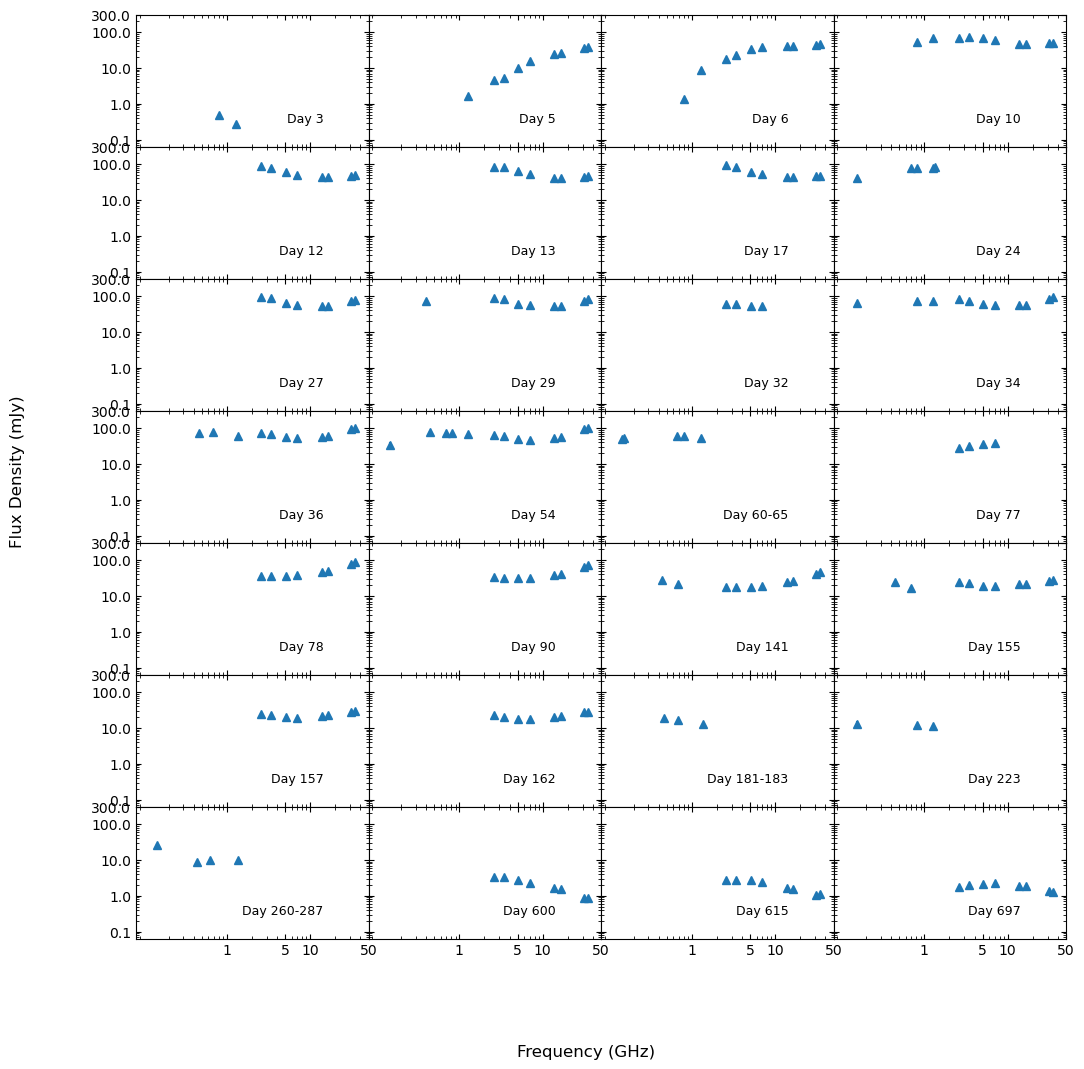

In [5]:
dfs = [df0, df1, df2, df3, df4, df5, df6, df6_5, df7, df8, df9, df10, df11, df12, df12_5, df13, df14, df15, df16, df17, df18, df19, df19_1, df19_2, df19_3, df20, df21, df22]

annotations = ['Day 3','Day 5', 'Day 6', 'Day 10','Day 12', 'Day 13', 'Day 17', "Day 24",'Day 27', 'Day 29', 'Day 32','Day 34',
               'Day 36', 'Day 54', "Day 60-65",'Day 77', 'Day 78', 'Day 90','Day 141', 'Day 155', 
               'Day 157','Day 162', "Day 181-183", "Day 223", "Day 260-287", 'Day 600', 'Day 615', 'Day 697']


fig, ax = plt.subplots(7, 4, sharex='all', sharey='all')
fig.set_size_inches(12, 12)
fig.subplots_adjust(hspace=0, wspace=0)


for idx, (df, label) in enumerate(zip(dfs, annotations)):
    row, col = divmod(idx, 4)
    mask = df["Flux Density (mJy)"] > 3 * df["Uncertainty (mJy)"] #don't show the non-detections
    if mask.any():
        ax[row,col].errorbar(df["Freq (GHz)"][mask], df["Flux Density (mJy)"][mask], yerr=df["Uncertainty (mJy)"][mask], fmt='^')
        ax[row,col].set_xscale('log')
        ax[row,col].set_yscale('log')
        ax[row,col].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
        ax[row,col].set_yticks([.1, 1,10, 100, 300], labels=['0.1','1.0', '10.0', '100.0', "300.0"])
        ax[row,col].annotate(label, xy=(135, 25), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
        ax[row,col].tick_params(axis='both', which='both', direction='in', top=True, right=True)

fig.supxlabel("Frequency (GHz)")
fig.supylabel("Flux Density (mJy)")
plt.show();

# Now to find the alpha

In [6]:
def error(err, freq, flux):
    yerr = []
    for i in range(len(freq)):
        if freq[i] < 10:
            pl = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            yerr.append(pl)
        else:
            pl =np.sqrt(err[i]**2 + (flux[i]*0.1)**2)
            yerr.append(pl)

    return(yerr)



In [7]:
#CHI(freq_F23,fw_tBPL2(freq_F23))

#O = observed values (the measured flux densities)
#E = expected values (the modelled flux densities)


def cs(O,E):
    X=[]
    for i in range(len(E)):
        X.append(((O[i]-E[i])**2) / E[i])
    XS = np.sum(X)
        
    return(XS)

#This gives chi squared, but we want reduced chi squared so just divide by the number of free

#Xhi = cs(flux,BPL_ww(freq))
#print("The chi squared is",Xhi)

In [8]:
#Initialize fitters
fitBPL = fitting.LevMarLSQFitter(calc_uncertainties=True)

print(fitBPL.fit_info)

#A function that will produce a broken power law for given input values
#Also fits the BPL using LevMarLSQFitter 
#Issue: not all BPL's work so I get an error when trying to fit it to the data 

def bpl_func(freq, flux, er, a1, a2):
    wt = 1 / (np.power(er,2))
    peak = np.max(flux)
    BPL = []
    
    for i in range(0,len(freq)):
        for j in range(0,len(a1)):
            bro = BrokenPowerLaw1D(peak, freq[i], alpha_1 = a1[j], alpha_2 = a2[j])
            BPL.append(bro)
        
        
    return(BPL)

{'nfev': None, 'fvec': None, 'fjac': None, 'ipvt': None, 'qtf': None, 'message': None, 'ierr': None, 'param_jac': None, 'param_cov': None}


# Day 3 (df0) 

In [9]:
x0 = df0['Freq (GHz)'].values.tolist()
y0 = df0['Flux Density (mJy)'].values.tolist()
yerr0 = df0['Uncertainty (mJy)'].values.tolist()
yerr0 = error(yerr0, x0, y0)

In [10]:
#Since this day has only two data points, I have to make x_0 fixed in order to run the powerlaw1d. 
#this is done in the code below so I can use the function for the rest of the points

PL0 =  PowerLaw1D(amplitude = y0[0], x_0= x0[0], alpha= -1.4,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model0 = fit(PL0, x0, y0)

    #weight is 1/error^2
y_weight0 = 1/ (np.power(yerr0,2))  

    # fit the data using the uncertainties as weights
fit_model_weights0 = fit(PL0, x0, y0, weights=y_weight0)

fit_model_weights0

<PowerLaw1D(amplitude=0.28, x_0=1.284, alpha=1.23447982)>

In [11]:
def two_points(Flux, Freq, Err):
    
    alpha = (np.log10(Flux[0]/Flux[1])) / (np.log10(Freq[0]/Freq[1]))
    
    
    der_s1 = 1 / (Flux[0] * np.log(Freq[0]/Freq[1]))
    der_s2 = -1 / (Flux[1] * np.log(Freq[0]/Freq[1]))
    
    
    err_alph_squared = (der_s1)**2 * (Err[0]**2) + (der_s2)**2 * (Err[1]**2) 
    err_alph = np.sqrt(err_alph_squared)
    
    return(alpha, err_alph)

In [12]:
alpha_err0 = two_points(y0,x0,yerr0)
print(alpha_err0)

(-1.2344798240864898, 0.3826385352067494)


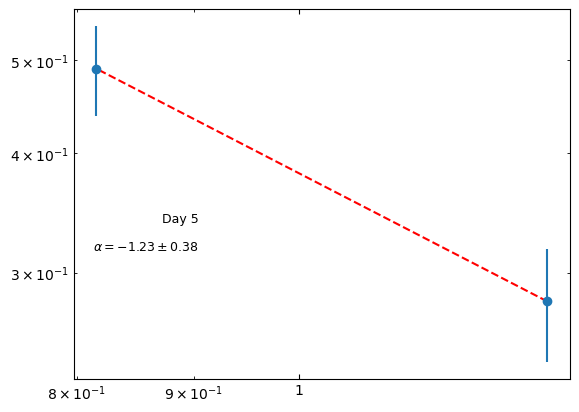

In [13]:
#plotting to check
fig,ax = plt.subplots()
mask2 = df0['Flux Density (mJy)'] < 3 * df0['Uncertainty (mJy)']  # apply non-detection threshold
mask = df0['Flux Density (mJy)'] > 3 * df0['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df0['Freq (GHz)'][mask], df0['Flux Density (mJy)'][mask], yerr= yerr0, fmt='o')
    ax.scatter(df0['Freq (GHz)'][mask2], (df0['Flux Density (mJy)'][mask2] + 3*df0['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 5', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df0['Freq (GHz)'][mask], fit_model_weights0(df0['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -1.23 \\pm 0.38}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

## Day 5.04 (df1)

In [14]:
#(work for anything with 3+ points)

x1 = df1['Freq (GHz)'].values.tolist()
y1 = df1['Flux Density (mJy)'].values.tolist()
yerr1 = df1['Uncertainty (mJy)'].values.tolist()


In [15]:
yerr1 = error(yerr1, x1, y1)

In [16]:
PL1 =  PowerLaw1D(amplitude = y1[0], x_0= x1[0], alpha= 4.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit1 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model1 = fit1(PL1, x1, y1)


#weight is 1/error^2
y_weight1 = 1/ (np.power(yerr1, 2))  

# fit the data using the uncertainties as weights
fit_model_weights1 = fit1(PL1, x1, y1, weights=y_weight1)

fit_model_weights1


<PowerLaw1D(amplitude=3.14565665, x_0=2.10143504, alpha=-1.23317632)>

In [17]:
fit1.fit_info

{'nfev': 26,
 'fvec': array([ 1.25431554, -8.2594968 ,  4.5939907 , -2.45891325, -2.83364271,
         1.32013883,  2.19508264,  3.95749327,  4.23401082]),
 'fjac': array([[ 1.10794339e+02, -3.84826790e+01, -6.00201462e+01,
          1.95780712e-01,  1.20018700e-01,  2.89689620e-02,
          3.23267317e-02,  3.56623572e-02,  3.62240872e-02],
        [-3.84826790e+01,  9.38696850e+01,  7.52971775e-15,
          4.81521795e-01,  3.71628565e-01,  1.28824988e-01,
          1.55848346e-01,  2.17394579e-01,  2.29217896e-01],
        [-6.00201462e+01,  3.49549500e-15,  2.14338815e-15,
          2.33284986e-01, -4.51956162e-02, -5.57168760e-02,
          1.44597068e-02, -2.68842018e-01, -2.83463378e-01]]),
 'ipvt': array([1, 2, 0], dtype=int32),
 'qtf': array([ 8.01822629e-05,  2.38564724e-12, -4.41701334e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.17669885e+29,  1.17

In [18]:
#taking fvec
fvec1 = np.array([ 1.25430052, -8.25950192,  4.59398398, -2.45891673, -2.83364484,
         1.32013831,  2.19508206,  3.95749264,  4.23401018])
var1 = np.var(fvec1)

#taking cov_x
cov_x1 = np.array([[1.98549527e+29, 1.10771438e+29, 7.88479762e+12],
        [1.10771438e+29, 6.17997517e+28, 4.39895467e+12],
        [7.88479762e+12, 4.39895467e+12, 4.26608883e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag1 = stand(cov_x1*var1) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag1[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.08242921509939506


In [19]:
Xhi = cs(df1['Flux Density (mJy)'], fit_model_weights1( df1["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(9-4))

The chi squared for lin fit is 15.218180927012583


In [20]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM1 = bpl_func(x_val, y1, yerr1, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM1[50]

#Apply error as weighting in the function 

weight1 = 1/ (np.power(yerr1,2))
fw_BPL1 = fitBPL(BM1[50], x1, y1, weights=weight1)   
print(fw_BPL1)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 3.84685541e-01, -7.50759224e+00,  6.11098490e+00, -1.25680315e+00,
       -1.89461485e+00, -5.96124579e-02,  7.69638127e-02, -5.64261606e-03,
       -1.82824999e-02]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[1.16764624e+02, 4.25414378e+01, 2.54281221e-03, 3.85606532e+00],
       [4.25414378e+01, 1.55159917e+01, 2.31333178e-03, 1.40389093e+00],
       [2.54281221e-03, 2.31333178e-03, 1.25422449e-04, 1.67644761e-17],
       [3.85606532e+00, 1.40389093e+00, 1.67644761e-17, 1.55231582e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df1['Flux Density (mJy)'], fw_BPL1( df1["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(9-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2      
    ----------------- ----------------- ------------------- -------------------
    18.80316113174984 8.627930012968847 -1.2603370131732514 -0.5043730144267528

{'nfev': 7, 'fvec': array([ 3.84685541e-01, -7.50759224e+00,  6.11098490e+00, -1.25680315e+00,
       -1.89461485e+00, -5.96124579e-02,  7.69638127e-02, -5.64261606e-03,
       -1.82824999e-02]), 'fjac': array([[-3.17910249e+02,  2.08431117e-01,  2.13922536e-01,
         6.31194594e-02,  1.55213169e-02,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 2.64691275e+01,  7.75660321e+00,  6.73487299e-01,
         5.11673511e-01,  3.93502782e-01,  3.08221022e-02,
         3.00351997e-02,  2.08764405e-02,  1.94964843e-02],
       [ 0.00000000e+00,  2.80522948e-01, -5.98814440e+00,
         1.76705113e-02,  1.35895160e-02, -3.14731110e-

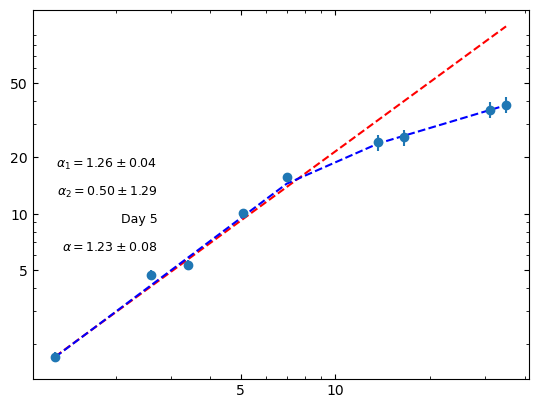

In [21]:
#plotting to check
fig,ax = plt.subplots()
mask2 = df1['Flux Density (mJy)'] < 3 * df1['Uncertainty (mJy)']  # apply non-detection threshold
mask = df1['Flux Density (mJy)'] > 3 * df1['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df1['Freq (GHz)'][mask], df1['Flux Density (mJy)'][mask], yerr= yerr1, fmt='o')
    ax.scatter(df1['Freq (GHz)'][mask2], (df1['Flux Density (mJy)'][mask2] + 3*df1['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 5', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df1['Freq (GHz)'][mask], fit_model_weights1(df1['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 1.23 \\pm 0.08}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 1.26 \\pm 0.04}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.50 \\pm 1.29}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


plt.show();


## Day 6.08 (df2)

In [22]:
#have to cut out the first point to get the broken fit to work

In [23]:
#(work for anything with 3+ points)
x2 = df2['Freq (GHz)'].values.tolist()
y2 = df2['Flux Density (mJy)'].values.tolist()
yerr2 = df2['Uncertainty (mJy)'].values.tolist()


In [24]:
yerr2 = error(yerr2, x2, y2)

In [25]:
PL2 =  PowerLaw1D(amplitude = y2[0], x_0= x2[0], alpha= -3.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit2 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model2 = fit2(PL2, x2, y2)


#weight is 1/error^2
y_weight2 = 1/ (np.power(yerr2, 2))  

# fit the data using the uncertainties as weights
fit_model_weights2 = fit2(PL2, x2, y2, weights=y_weight2)

fit_model_weights2


<PowerLaw1D(amplitude=2040.56257701, x_0=196.52327129, alpha=-1.32321165)>

In [26]:
fit2.fit_info

{'nfev': 24,
 'fvec': array([  3.62797221, -29.56181187, -13.72024084, -10.07515007,
         -6.13465886,  -3.79263353,   1.14568033,   2.03516818,
          6.64117977,   7.36278444]),
 'fjac': array([[-7.28729820e+02,  9.07147701e-01, -6.62115660e-02,
          3.84485939e-02,  2.90375389e-02,  2.86932342e-02,
          1.30744247e-02,  1.50347716e-02,  2.23532596e-02,
          2.24367699e-02],
        [ 9.07147701e-01,  6.88674448e-02, -5.02654789e-03,
          1.76176767e-01,  1.90301283e-01,  2.41812616e-01,
          1.81463277e-01,  2.39251038e-01,  5.79857329e-01,
          6.40752257e-01],
        [-6.62115660e-02, -5.02654789e-03, -2.55880901e-18,
          4.23713599e-01,  0.00000000e+00,  8.47427197e-02,
         -1.69485439e-01, -2.54228159e-01, -3.38970879e-01,
         -6.77941758e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([3.78099505e-05, 4.35196199e-03, 3.30223735e+01]),
 'message': 'Both actual and predicted relative reductions in the sum of squa

In [27]:
#taking fvec
fvec2 = np.array([  3.62979932, -29.56183542, -13.72044851, -10.07539524,
         -6.13494592,  -3.79301289,   1.14538059,   2.03476906,
          6.64018737,   7.3616838 ])
var2 = np.var(fvec2)

#taking cov_x
cov_x2 = np.array([[1.03241009e+35, 7.89607829e+33, 8.24740407e+15],
        [7.89607829e+33, 6.03907814e+32, 6.30777911e+14],
        [8.24740407e+15, 6.30777911e+14, 9.87293547e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag2 = stand(cov_x2*var2) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag2[2]) #Just showing the standard deviation on the slope

The error/standard deviation is 0.33727764418808426


In [28]:
Xhi = cs(df2['Flux Density (mJy)'], fit_model_weights2( df2["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(10-4))

The chi squared for lin fit is 54.559074431180726


In [29]:
x_new = [1.284, 2.6, 3.4, 5.1, 7.0, 13.7, 16.5, 31.1, 34.9]
y_new = [8.6, 18.206, 23.366, 33.454, 39.663, 40.939, 41.636, 44.762, 46.68]
yerr_new = [0.44966654311834237,0.9169220741153525,1.172571912506862,1.6737402098294705,
 1.9839125289437536,4.094369452064629,4.1640766035220835,4.478388821886729,4.67040940389598]


x_val = np.arange(1,40,0.1)  
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

In [30]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)


#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM2 = bpl_func(x_val, y_new, yerr_new, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM2[23]

#Apply error as weighting in the function 

weight2 = 1/ (np.power(yerr_new,2))
fw_BPL2 = fitBPL(BM2[12], x_new, y_new, weights=weight2)   
print(fw_BPL2)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 0.15536394, -0.6051173 , -0.08251763,  0.59815092, -0.01407829,
        0.0562504 ,  0.05182576,  0.0037174 , -0.06471422] )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(  [[2.67426424e+01, 3.86394636e+00, 7.43499585e-03, 6.97196822e-01],
       [3.86394636e+00, 6.47358290e-01, 1.29579407e-02, 9.92825781e-02],
       [7.43499585e-03, 1.29579407e-02, 1.81858974e-03, 1.76182853e-18],
       [6.97196822e-01, 9.92825781e-02, 1.76182853e-18, 4.01798171e-02]] )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df2['Flux Density (mJy)'], fw_BPL2( df2["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(9-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1             alpha_2       
    ------------------ ----------------- ------------------- --------------------
    38.901057452968374 5.637524535868002 -1.0176740767342767 -0.08315110120449413

{'nfev': 12, 'fvec': array([ 0.15536394, -0.6051173 , -0.08251763,  0.59815092, -0.01407829,
        0.0562504 ,  0.05182576,  0.0037174 , -0.06471422]), 'fjac': array([[-6.57921871e+01,  2.47610950e-01,  1.29982012e-01,
         1.90987775e-02,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -6.74509932e+00,  0.00000000e+00,
         0.00000000e+00, -3.22950175e-01, -3.28892857e-01,
        -3.90559970e-01, -5.66015823e-01, -5.60911464e-01],
       [ 8.77788518e+00, -1.10019335e-01,  3.35067429e+00,
         6.27656698e-01,  1.99212666e-01,  1.68763004e-01,
         1.98144410e-01,  2.8135

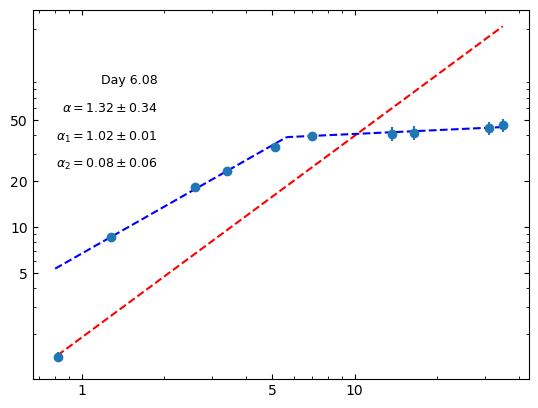

In [31]:
# plotting to check
x_freq = np.arange(.8,36,0.1)

fig,ax = plt.subplots()
mask = df2['Flux Density (mJy)'] > 3 * df2['Uncertainty (mJy)']  # apply detection threshold
mask2 = df2['Flux Density (mJy)'] < 3 * df2['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df2['Freq (GHz)'][mask], df2['Flux Density (mJy)'][mask], yerr=yerr2, fmt='o')
    ax.scatter(df2['Freq (GHz)'][mask2], (df2['Flux Density (mJy)'][mask2] + 3*df2['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 6.08', xy=(90, 220), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df2['Freq (GHz)'][mask], fit_model_weights2(df2['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 1.32 \\pm 0.34}$', xy=(90, 200), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    
    ax.plot(x_freq, fw_BPL2(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = 1.02 \\pm 0.01}$', xy=(90, 180), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.08 \\pm 0.06}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## dAY 9.99 (df3)

In [32]:
#(work for anything with 3+ points)

x3 = df3['Freq (GHz)'].values.tolist()
y3 = df3['Flux Density (mJy)'].values.tolist()
yerr3 = df3['Uncertainty (mJy)'].values.tolist()


In [33]:
yerr3 = error(yerr3, x3, y3)

In [34]:
PL3 =  PowerLaw1D(amplitude = y3[0], x_0= x3[0], alpha= -3.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit3 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model3 = fit3(PL3, x3, y3)


#weight is 1/error^2
y_weight3 = 1/ (np.power(yerr3, 2))  

# fit the data using the uncertainties as weights
fit_model_weights3 = fit3(PL3, x3, y3, weights=y_weight3)

fit_model_weights3


<PowerLaw1D(amplitude=55.04282433, x_0=468.69923125, alpha=0.02055638)>

In [35]:
fit3.fit_info

{'nfev': 31,
 'fvec': array([ 1.03121527, -0.63654011, -0.63949562, -0.95225506, -0.62933115,
         0.15820471,  0.49531411,  0.55452076,  0.43431687,  0.32616465]),
 'fjac': array([[-7.85794817e+01, -2.70925109e-01, -6.43818485e-04,
          2.80079988e-01,  3.05071181e-01,  3.74559387e-01,
          1.16727661e-01,  1.15125303e-01,  8.71671216e-02,
          7.73946382e-02],
        [-2.70925109e-01,  5.77122400e-02,  1.37145675e-04,
         -1.75845669e-01, -3.28061778e-01, -5.56103230e-01,
         -3.02831913e-01, -3.43076385e-01, -4.08773774e-01,
         -3.93905878e-01],
        [-6.43818485e-04,  1.37145675e-04,  7.94587337e-20,
          7.24882436e-01,  3.41121146e-01,  3.41121146e-01,
         -0.00000000e+00,  1.70560573e-01,  2.55840860e-01,
         -0.00000000e+00]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-1.69838506e-05, -1.92541286e-04,  1.78765592e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at m

In [36]:
#taking fvec
fvec3 = np.array([ 1.03121582, -0.63653977, -0.63949526, -0.95225474, -0.62933078,
         0.1582052 ,  0.49531429,  0.55452095,  0.43431705,  0.32616481])
var3 = np.var(fvec3)

#taking cov_x
cov_x3 = np.array([[ 1.31055475e+33, -5.59269143e+35, -3.52391455e+14],
        [-5.59269143e+35,  2.38663797e+38,  1.50380338e+17],
        [-3.52391455e+14,  1.50380338e+17,  3.82567427e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag3 = stand(cov_x3*var3) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag3[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.03936843473671743


In [37]:
Xhi = cs(df3['Flux Density (mJy)'], fit_model_weights3( df3["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(10-4))

The chi squared for lin fit is 2.3999634224123025


In [38]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM3 = bpl_func(x_val, y3, yerr3, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM3[50]

#Apply error as weighting in the function 

weight3 = 1/ (np.power(yerr3,2))
fw_BPL3 = fitBPL(BM3[50], x3, y3, weights=weight3)   
print(fw_BPL3)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array(  [2.32735769e-09,  2.06361980e-09,  2.96653795e-01, -3.62922577e-01,
       -3.17717227e-01,  1.93036091e-01,  2.35444718e-01,  2.10826114e-01,
       -1.04051766e-01, -2.07418327e-01]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 1.35393648e+02,  4.28044430e-01, -2.62778815e+00,
         1.14626561e+00],
       [ 4.28044430e-01,  4.80001915e-01,  2.82227000e-01,
         4.02757686e-02],
       [-2.62778815e+00,  2.82227000e-01,  2.73019817e-01,
         1.73472348e-17],
       [ 1.14626561e+00,  4.02757686e-02,  1.73472348e-17,
         1.58969314e-02]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df3['Flux Density (mJy)'], fw_BPL3( df3["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(10-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2      
    ----------------- ----------------- ------------------- -------------------
    79.46973360362945 1.585488285934373 -0.5678358928438056 0.18576418196162076

{'nfev': 10, 'fvec': array([ 2.32735769e-09,  2.06361980e-09,  2.96653795e-01, -3.62922577e-01,
       -3.17717227e-01,  1.93036091e-01,  2.35444718e-01,  2.10826114e-01,
       -1.04051766e-01, -2.07418327e-01]), 'fjac': array([[-1.71855690e+01,  0.00000000e+00, -1.73647516e-01,
        -2.23840286e-01, -3.80419775e-01, -6.05688181e-01,
        -2.91751850e-01, -3.19867837e-01, -3.41504917e-01,
        -3.22652297e-01],
       [ 0.00000000e+00, -4.67949906e+00,  1.68487521e-01,
         2.17188795e-01,  3.69115471e-01,  5.87689951e-01,
         2.83082344e-01,  3.10362855e-01,  3.31356982e-01,
         3.13064574e-01],
       [ 1.31596163e+00,  2.84040670e+00, -1.4

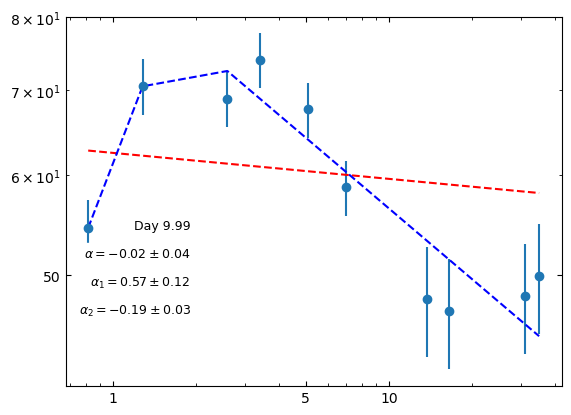

In [39]:
#plotting to check
fig,ax = plt.subplots()
mask = df3['Flux Density (mJy)'] > 3 * df3['Uncertainty (mJy)']  # apply detection threshold
mask2 = df3['Flux Density (mJy)'] < 3 * df3['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df3['Freq (GHz)'][mask], df3['Flux Density (mJy)'][mask], yerr=yerr3, fmt='o')
    ax.scatter(df3['Freq (GHz)'][mask2], (df3['Flux Density (mJy)'][mask2] + 3*df3['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 9.99', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df3['Freq (GHz)'][mask], fit_model_weights3(df3['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.02 \\pm 0.04}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(df3['Freq (GHz)'][mask], fw_BPL3(df3['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.57 \\pm 0.12}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = -0.19 \\pm 0.03}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 12.01 (df4)

In [40]:
#(work for anything with 3+ points)

x4 = df4['Freq (GHz)'].values.tolist()
y4 = df4['Flux Density (mJy)'].values.tolist()
yerr4 = df4['Uncertainty (mJy)'].values.tolist()


In [41]:
yerr4 = error(yerr4, x4, y4)

In [42]:
PL4 =  PowerLaw1D(amplitude = y4[0], x_0= x4[0], alpha= -3) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit4 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model4 = fit4(PL4, x4, y4)


#weight is 1/error^2
y_weight4 = 1/ (np.power(yerr4, 2))  

# fit the data using the uncertainties as weights
fit_model_weights4 = fit4(PL4, x4, y4, weights=y_weight4)

fit_model_weights4


<PowerLaw1D(amplitude=9.48026645, x_0=955.79202522, alpha=0.35785324)>

In [43]:
fit4.fit_info

{'nfev': 54,
 'fvec': array([-0.51736756, -0.45337144,  0.13382069,  0.64831998, -0.02008107,
        -0.10545177, -0.64858843, -0.7435749 ]),
 'fjac': array([[-6.67865580e+01, -1.36761719e+00, -4.85430035e-03,
          6.26244301e-01,  1.44180768e-01,  1.36851174e-01,
          7.79711177e-02,  6.52721437e-02],
        [-1.36761719e+00,  1.31964189e-01,  4.68401400e-04,
         -5.25896853e-01, -3.68703833e-01, -4.28802840e-01,
         -4.34064461e-01, -3.98797897e-01],
        [-4.85430035e-03,  4.68401400e-04, -9.41510556e-19,
          2.87889011e-01,  2.87889011e-01,  1.72733407e-01,
          0.00000000e+00,  1.43944506e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 4.62104912e-05,  3.66163301e-05, -3.32441523e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.42126086e+31, -4.00416260e+33, -4.82060289e+14],
        [-4.00416260e+33,  1.12810

In [44]:
#taking fvec
fvec4 = np.array([-0.51736691, -0.45337068,  0.1338218 ,  0.64832137, -0.0200807 ,
        -0.1054514 , -0.64858818, -0.74357469])
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array([[ 5.93795779e+31, -1.64946975e+34, -2.18527739e+15],
        [-1.64946975e+34,  4.58196328e+36,  6.07035126e+17],
        [-2.18527739e+15,  6.07035126e+17,  1.04725421e-01]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag4[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.1416434684188529


In [45]:
Xhi = cs(df4['Flux Density (mJy)'], fit_model_weights4( df4["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 4.548989685750195


In [46]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM4 = bpl_func(x_val, y4, yerr4, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM4[50]

#Apply error as weighting in the function 

weight4 = 1/ (np.power(yerr4,2))
fw_BPL4 = fitBPL(BM4[50], x4, y4, weights=weight4)   
print(fw_BPL4)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 0.04938259, -0.09045775,  0.0498655 , -0.01314194, -0.05703355,
        0.06104837,  0.03314406, -0.04634257]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 2.81716207e+02, -1.16584810e+02, -2.49121625e-01,
         8.52525736e+00],
       [-1.16584810e+02,  5.83115739e+01, -5.36076082e-01,
        -3.64678055e+00],
       [-2.49121625e-01, -5.36076082e-01,  5.11237019e-02,
        -1.18828558e-16],
       [ 8.52525736e+00, -3.64678055e+00, -1.18828558e-16,
         3.29632462e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df4['Flux Density (mJy)'], fw_BPL4( df4["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1            alpha_2       
    ----------------- ------------------ ----------------- --------------------
    41.14767012095927 10.101989837062618 0.573930825903548 -0.11408975655322529

{'nfev': 13, 'fvec': array([ 0.04938259, -0.09045775,  0.0498655 , -0.01314194, -0.05703355,
        0.06104837,  0.03314406, -0.04634257]), 'fjac': array([[-9.84821216,  0.55472134,  0.46243535,  0.29221935,  0.        ,
         0.        ,  0.        ,  0.        ],
       [ 0.        , -3.77312373,  0.        ,  0.        , -0.1801731 ,
        -0.31443654, -0.6562454 , -0.6618227 ],
       [-0.6254439 , -0.04450311, -0.3152148 ,  0.91036771, -0.06385833,
        -0.05856094, -0.02029421, -0.01306824],
       [-0.26754109,  0.09576469, -0.1304478 , -0.05957912,  0.74060019,
         0.57350185, -0.18880425, -0.29099471]]), 'ipvt': array([2, 3, 1, 0], dtype=int32

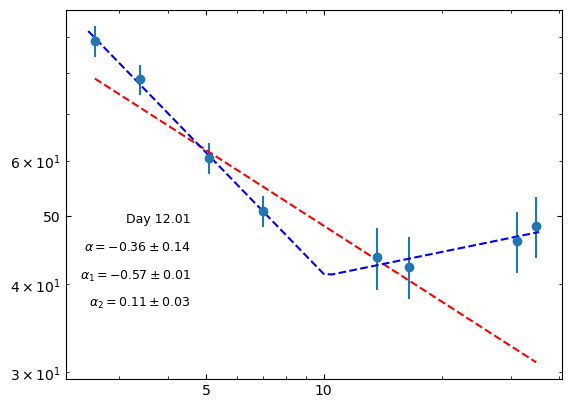

In [47]:
#plotting to check
x_freq = np.arange(2.5,36,0.5)

fig,ax = plt.subplots()
mask = df4['Flux Density (mJy)'] > 3 * df4['Uncertainty (mJy)']  # apply detection threshold
mask2 = df4['Flux Density (mJy)'] < 3 * df4['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df4['Freq (GHz)'][mask], df4['Flux Density (mJy)'][mask], yerr=yerr4, fmt='o')
    ax.scatter(df4['Freq (GHz)'][mask2], (df4['Flux Density (mJy)'][mask2] + 3*df4['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 12.01', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df4['Freq (GHz)'][mask], fit_model_weights4(df4['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.36 \\pm 0.14}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL4(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.57 \\pm 0.01}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.11 \\pm 0.03}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    
plt.show();


## Day 12.99 (df5)

In [48]:
#(work for anything with 3+ points)
x5 = df5['Freq (GHz)'].values.tolist()
y5 = df5['Flux Density (mJy)'].values.tolist()
yerr5 = df5['Uncertainty (mJy)'].values.tolist()


In [49]:
yerr5 = error(yerr5, x5, y5)

In [50]:
PL5 =  PowerLaw1D(amplitude = y5[0], x_0= x5[0], alpha= -3.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit5 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model5 = fit5(PL5, x5, y5)


#weight is 1/error^2
y_weight5 = 1/ (np.power(yerr5, 2))  

# fit the data using the uncertainties as weights
fit_model_weights5 = fit5(PL5, x5, y5, weights=y_weight5)

fit_model_weights5


<PowerLaw1D(amplitude=9.50996987, x_0=957.27898676, alpha=0.36146653)>

In [51]:
fit5.fit_info

{'nfev': 47,
 'fvec': array([-0.22048561, -0.53353758, -0.08660622,  0.6510073 ,  0.13050912,
         0.02644891, -0.56804468, -0.68500588]),
 'fjac': array([[-6.56126868e+01, -1.34059869e+00, -4.81401562e-03,
          6.26367160e-01,  1.63061087e-01,  1.53186826e-01,
          8.98871459e-02,  7.51440097e-02],
        [-1.34059869e+00,  1.42722747e-01,  5.12509477e-04,
         -4.91449640e-01, -3.81361375e-01, -4.38124442e-01,
         -4.55004883e-01, -4.17275335e-01],
        [-4.81401562e-03,  5.12509477e-04,  2.69095315e-19,
          2.01453186e-01,  2.01453186e-01, -0.00000000e+00,
         -2.01453186e-01, -1.00726593e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 1.88713841e-05,  3.78609815e-05, -3.00914233e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.78075895e+32, -4.95902652e+34, -1.38949376e+15],
        [-4.95902652e+34,  1.38098

In [52]:
#taking fvec
fvec5 = np.array([-0.22048499, -0.53353698, -0.08660539,  0.65100842,  0.13050945,
         0.02644924, -0.56804446, -0.68500569])
var5 = np.var(fvec5)

#taking cov_x
cov_x5 = np.array([[ 1.24226934e+31, -3.43506142e+33,  3.87797894e+14],
        [-3.43506142e+33,  9.49846104e+35, -1.07231945e+17],
        [ 3.87797894e+14, -1.07231945e+17,  3.28325424e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag5 = stand(cov_x5*var5) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag5[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.07491799920053203


In [53]:
Xhi = cs(df5['Flux Density (mJy)'], fit_model_weights5( df5["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 3.0041155181278003


In [54]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM5 = bpl_func(x_val, y5, yerr5, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM5[50]

#Apply error as weighting in the function 

weight5 = 1/ (np.power(yerr5,2))
fw_BPL5 = fitBPL(BM5[50], x5, y5, weights=weight5)   
print(fw_BPL5)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 0.25400048, -0.28445696, -0.1585124 ,  0.12892644, -0.05063743,
        0.05346084,  0.03914112, -0.05014738]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 1.86289693e+02, -9.58389262e+01, -2.65846317e-01,
         6.26168290e+00],
       [-9.58389262e+01,  7.01750909e+01, -7.82269295e-01,
        -3.42431169e+00],
       [-2.65846317e-01, -7.82269295e-01,  4.86411740e-02,
        -1.23165367e-16],
       [ 6.26168290e+00, -3.42431169e+00, -1.23165367e-16,
         2.98875716e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df5['Flux Density (mJy)'], fw_BPL5( df5["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1             alpha_2       
    ------------------ ------------------ ------------------ --------------------
    40.318356636026095 11.644554439268353 0.5281255791791137 -0.09815025234421075

{'nfev': 11, 'fvec': array([ 0.25400048, -0.28445696, -0.1585124 ,  0.12892644, -0.05063743,
        0.05346084,  0.03914112, -0.05014738]), 'fjac': array([[-1.13299608e+01,  4.98367909e-01,  4.43734994e-01,
         3.51901725e-01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -3.40145372e+00,  0.00000000e+00,
         0.00000000e+00, -1.11743672e-01, -2.56380066e-01,
        -6.72406040e-01, -6.85312141e-01],
       [-4.98938195e-01, -3.30723026e-02, -2.18898436e-01,
         9.20601792e-01, -7.81438474e-02, -6.90674934e-02,
        -1.80988404e-02, -8.85014336e-03],
       [-2.72853149e-01,  9.73173038

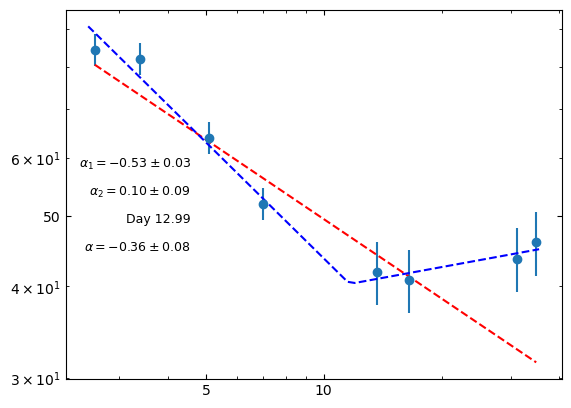

In [55]:
#plotting to check
x_freq = np.arange(2.5,36,0.5)
fig,ax = plt.subplots()
mask = df5['Flux Density (mJy)'] > 3 * df5['Uncertainty (mJy)']  # apply detection threshold
mask2 = df5['Flux Density (mJy)'] < 3 * df5['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df5['Freq (GHz)'][mask], df5['Flux Density (mJy)'][mask], yerr=yerr5, fmt='o')
    ax.scatter(df5['Freq (GHz)'][mask2], (df5['Flux Density (mJy)'][mask2] + 3*df5['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 12.99', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df5['Freq (GHz)'][mask], fit_model_weights5(df5['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.36 \\pm 0.08}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL5(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.53 \\pm 0.03}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.10 \\pm 0.09}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 17.01 (df6)

In [56]:
#(work for anything with 3+ points)
x6 = df6['Freq (GHz)'].values.tolist()
y6 = df6['Flux Density (mJy)'].values.tolist()
yerr6 = df6['Uncertainty (mJy)'].values.tolist()


In [57]:
yerr6 = error(yerr6, x6, y6)

In [58]:
PL6 =  PowerLaw1D(amplitude = y6[0], x_0= x6[0], alpha= -1.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit6 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model6 = fit6(PL6, x6, y6)


#weight is 1/error^2
y_weight6 = 1/ (np.power(yerr6, 2))  

# fit the data using the uncertainties as weights
fit_model_weights6 = fit6(PL6, x6, y6, weights=y_weight6)

fit_model_weights6


<PowerLaw1D(amplitude=9.50226989, x_0=872.73325167, alpha=0.3696339)>

In [59]:
fit6.fit_info

{'nfev': 38,
 'fvec': array([-5.11175677e-01, -5.35526064e-01,  1.82999816e-01,  6.24002730e-01,
        -2.97486998e-04, -9.22769987e-02, -6.53015589e-01, -7.28594524e-01]),
 'fjac': array([[-6.34201817e+01, -1.32251327e+00, -5.31429007e-03,
          6.29392086e-01,  1.48422480e-01,  1.40111745e-01,
          7.73277062e-02,  6.84871130e-02],
        [-1.32251327e+00,  1.30564508e-01,  5.24650821e-04,
         -5.10472475e-01, -3.74474329e-01, -4.34286051e-01,
         -4.28986540e-01, -4.17528474e-01],
        [-5.31429007e-03,  5.24650821e-04, -3.64724165e-19,
          2.97266339e-01, -2.97266339e-01, -5.20216094e-01,
         -7.43165848e-02, -1.48633170e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 7.80559435e-05,  6.45187254e-05, -7.62322790e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.21383976e+32, -3.02075945e+34, -1.46421118e+15],
  

In [60]:
#taking fvec
fvec6 = np.array([-5.11175522e-01, -5.35525890e-01,  1.83000090e-01,  6.24003072e-01,
        -2.97392449e-04, -9.22769050e-02, -6.53015527e-01, -7.28594467e-01])
var6 = np.var(fvec6)

#taking cov_x
cov_x6 = np.array([[ 2.30024101e+31, -5.63505205e+33, -4.85157974e+14],
        [-5.63505205e+33,  1.38045585e+36,  1.18852347e+17],
        [-4.85157974e+14,  1.18852347e+17,  3.59904397e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag6 = stand(cov_x6*var6) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag6[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.08403108061516525


In [61]:
Xhi = cs(df6['Flux Density (mJy)'], fit_model_weights6( df6["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 4.655860039085451


In [62]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM6 = bpl_func(x_val, y6, yerr6, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM6[50]

#Apply error as weighting in the function 

weight6 = 1/ (np.power(yerr6,2))
fw_BPL6 = fitBPL(BM6[50], x6, y6, weights=weight6)   
print(fw_BPL6)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 0.0768412 , -0.16954412,  0.11194131, -0.03787601, -0.0521618 ,
        0.05989089,  0.00284302, -0.01638785]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 3.01508154e+02, -1.18279415e+02, -2.52130792e-01,
         8.85177812e+00],
       [-1.18279415e+02,  5.63303614e+01, -5.63342530e-01,
        -3.58347940e+00],
       [-2.52130792e-01, -5.63342530e-01,  5.55801403e-02,
        -4.77048956e-17],
       [ 8.85177812e+00, -3.58347940e+00, -4.77048956e-17,
         3.32423068e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df6['Flux Density (mJy)'], fw_BPL6( df6["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(9-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1             alpha_2       
    ------------------ ------------------ ------------------ --------------------
    41.722128357183436 10.119698550235878 0.5991375463762466 -0.10855613554350535

{'nfev': 7, 'fvec': array([ 0.0768412 , -0.16954412,  0.11194131, -0.03787601, -0.0521618 ,
        0.05989089,  0.00284302, -0.01638785]), 'fjac': array([[-9.44767291,  0.53473779,  0.47705997,  0.29679375,  0.        ,
         0.        ,  0.        ,  0.        ],
       [ 0.        , -3.74479332,  0.        ,  0.        , -0.17903746,
        -0.31210811, -0.63742269, -0.68134164],
       [-0.63007003, -0.04185643, -0.31733684,  0.90914644, -0.06107151,
        -0.05684816, -0.02291926, -0.01734498],
       [-0.25507225,  0.09352094, -0.12448889, -0.05759045,  0.74165569,
         0.57381025, -0.17861901, -0.29460272]]), 'ipvt': array([2, 3, 1, 0], dtype=

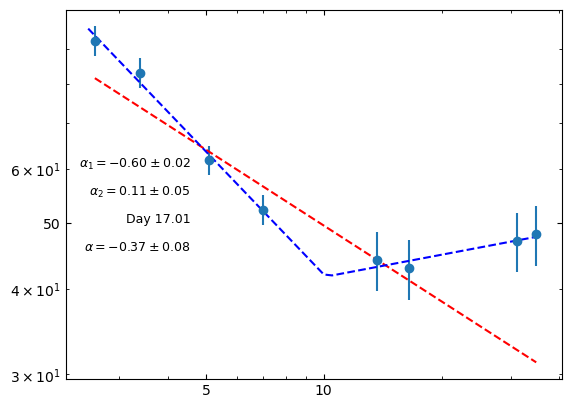

In [63]:
#plotting to check
x_freq = np.arange(2.5,36,0.5)
fig,ax = plt.subplots()
mask = df6['Flux Density (mJy)'] > 3 * df6['Uncertainty (mJy)']  # apply detection threshold
mask2 = df6['Flux Density (mJy)'] < 3 * df6['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df6['Freq (GHz)'][mask], df6['Flux Density (mJy)'][mask], yerr=yerr6, fmt='o')
    ax.scatter(df6['Freq (GHz)'][mask2], (df6['Flux Density (mJy)'][mask2] + 3*df6['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 17.01', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df6['Freq (GHz)'][mask], fit_model_weights6(df6['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.37 \\pm 0.08}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL6( x_freq ), 'b--')
    ax.annotate('${\u03B1_1 = -0.60 \\pm 0.02}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.11 \\pm 0.05}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


# Day 24 (df6_5)

In [64]:
#(work for anything with 3+ points)
x6_5 = df6_5['Freq (GHz)'].values.tolist()
y6_5 = df6_5['Flux Density (mJy)'].values.tolist()
yerr6_5 = df6_5['Uncertainty (mJy)'].values.tolist()
#new (correct error)
yerr6_5 = error(yerr6_5, x6_5, y6_5)

PL6_5 =  PowerLaw1D(amplitude = y6_5[0], x_0= x6_5[0], alpha= -9.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit6_5 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model6_5 = fit6_5(PL6_5, x6_5, y6_5)


#weight is 1/error^2
y_weight6_5 = 1/ (np.power(yerr6_5, 2))  

# fit the data using the uncertainties as weights
fit_model_weights6_5 = fit6_5(PL6_5, x6_5, y6_5, weights=y_weight6_5)

print("alpha")
print(fit_model_weights6_5)
print("")

print(fit6_5.fit_info)

alpha
Model: PowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude            x_0                alpha       
    ----------------- ------------------ -------------------
    78.23978277306043 1.0459409258647512 -0.2685634094510756

{'nfev': 14, 'fvec': array([ 0.44903935, -0.34508275,  0.33440816, -0.05822744, -0.39731623]), 'fjac': array([[ 5.02405139e+00, -4.78166126e-01,  2.37762437e-02,
         2.24587570e-01, -3.04601326e-01],
       [-4.78166126e-01,  2.39274455e+00, -1.18976386e-01,
         3.85030760e-01,  4.97452851e-01],
       [ 2.37762437e-02, -1.18976386e-01, -9.81307787e-18,
         7.07106781e-01,  7.07106781e-01]]), 'ipvt': array([2, 1, 0], dtype=int32), 'qtf': array([-4.81592753e-06, -5.24768322e-05,  1.96809971e-01]), 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000', 'ierr': 1, 'param_jac': None, 'param_cov': array([[ 1.03845937e+34,  5.16361610e+32, -3.06384812e+16],
     

In [65]:
#taking fvec
fvec6_5 = np.array([ 0.44904038, -0.34508257,  0.33440706, -0.05822659, -0.39731627])
var6_5 = np.var(fvec6_5)

#taking cov_x
cov_x6_5 = np.array([[ 5.01595470e+33,  2.99280422e+32, -1.13741801e+16],
       [ 2.99280422e+32,  1.78567743e+31, -6.78648357e+14],
       [-1.13741801e+16, -6.78648357e+14,  6.69916948e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag6_5 = stand(cov_x6_5*var6_5) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag6_5[2]) #Just showing the standard deviation on the slope

#
Xhi = cs(df6_5['Flux Density (mJy)'], fit_model_weights6_5( df6_5["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(5-4))

The error/standard deviation is 0.08919144875299044
The chi squared for lin fit is 2.772061031110741


In [66]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM6_5 = bpl_func(x_val, y6_5, yerr6_5, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
#BM6_5[47]

#Apply error as weighting in the function 

weight6_5 = 1/ (np.power(yerr6_5,2))
fw_BPL6_5 = fitBPL(BM6_5[40], x6_5, y6_5, weights=weight6_5)   
print(fw_BPL6_5)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df6_5['Flux Density (mJy)'], fw_BPL6_5( df6_5["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(5-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1        alpha_2
    ------------------ ----------------- -------------------- -------
    115.14912250383641 4.409961189788065 -0.26856377965950695     0.0

{'nfev': 19, 'fvec': array([ 0.44904076, -0.34508238,  0.33440694, -0.05822628, -0.39731615]), 'fjac': array([[-1.54757902e+01,  5.46780821e-01, -7.80797826e-02,
         0.00000000e+00,  4.42944804e-01],
       [ 5.46780821e-01, -1.83619291e-01,  2.62206606e-02,
         0.00000000e+00,  2.57734908e-01],
       [-7.80797826e-02,  2.62206606e-02, -1.21740021e-17,
         0.00000000e+00,  4.98729350e-01],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -0.00000000e+00,  0.00000000e+00]]), 'ipvt': array([2, 1, 0, 3], dtype=int32), 'qtf': array([-8.45462613e-05,  2.38498368e-05, -3.19144577e-01, -2.32577259e-01]), 'message': 'Both actual and predicted relative reductions in the 

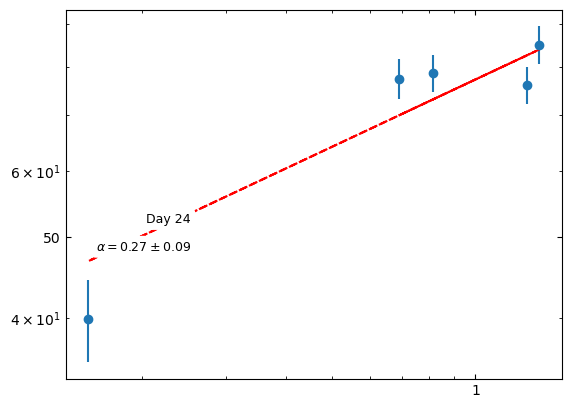

In [67]:
#plotting to check
fig,ax = plt.subplots()
mask = df6_5['Flux Density (mJy)'] > 3 * df6_5['Uncertainty (mJy)']  # apply detection threshold
mask2 = df6_5['Flux Density (mJy)'] < 3 * df6_5['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df6_5['Freq (GHz)'][mask], df6_5['Flux Density (mJy)'][mask], yerr=yerr6_5, fmt='o')
    ax.scatter(df6_5['Freq (GHz)'][mask2], (df6_5['Flux Density (mJy)'][mask2] + 3*df6_5['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 24', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df6_5['Freq (GHz)'][mask], fit_model_weights6_5(df6_5['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.27 \\pm 0.09}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

## Day 27.01 (df7)

In [68]:
#(work for anything with 3+ points)
x7 = df7['Freq (GHz)'].values.tolist()
y7 = df7['Flux Density (mJy)'].values.tolist()
yerr7 = df7['Uncertainty (mJy)'].values.tolist()


In [69]:
yerr7 = error(yerr7, x7, y7) 

In [70]:
PL7 =  PowerLaw1D(amplitude = y7[0], x_0= x7[0], alpha= -1) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit7 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model7 = fit7(PL7, x7, y7)


#weight is 1/error^2
y_weight7 = 1/ (np.power(yerr7, 2))  

# fit the data using the uncertainties as weights
fit_model_weights7 = fit7(PL7, x7, y7, weights=y_weight7)

fit_model_weights7


<PowerLaw1D(amplitude=22.4829328, x_0=121.72485152, alpha=0.34950635)>

In [71]:
fit7.fit_info

{'nfev': 19,
 'fvec': array([-0.3682999 , -0.3957717 ,  0.28528942,  0.40758083, -0.20021693,
        -0.31368455, -0.6894876 , -0.71151604]),
 'fjac': array([[-3.64906715e+01, -5.10575086e-01, -3.29600903e-02,
          5.74959874e-01,  9.86458825e-02,  8.32263412e-02,
          2.70283332e-02,  2.00591840e-02],
        [-5.10575086e-01,  6.86154777e-02,  4.42946083e-03,
         -6.98440359e-01, -3.70997516e-01, -3.96872733e-01,
         -2.77493273e-01, -2.38029098e-01],
        [-3.29600903e-02,  4.42946083e-03,  5.16335277e-18,
          2.51976315e-01,  4.61956578e-01,  2.51976315e-01,
          1.25988158e-01,  8.39921051e-02]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 2.96612116e-05,  3.11191563e-06, -2.31635233e-02]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.56312587e+32, -2.42139241e+33,  1.15461314e+15],
        [-2.42139241e+33,  3.75090

In [72]:
#taking fvec
fvec7 = np.array([-0.36830055, -0.3957724 ,  0.28528841,  0.40757972, -0.20021716,
        -0.31368475, -0.68948769, -0.71151611])
var7 = np.var(fvec7)

#taking cov_x
cov_x7 = np.array([[ 1.46142271e+32, -1.33651253e+33, -2.70282229e+15],
        [-1.33651253e+33,  1.22227862e+34,  2.47180765e+16],
        [-2.70282229e+15,  2.47180765e+16,  9.23205362e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag7 = stand(cov_x7*var7) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag7[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.11604085422254407


In [73]:
Xhi = cs(df7['Flux Density (mJy)'], fit_model_weights7( df7["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 22.17333444313796


In [74]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM7 = bpl_func(x_val, y7, yerr7, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM7[50]

#Apply error as weighting in the function 

weight7 = 1/ (np.power(yerr7,2))
fw_BPL7 = fitBPL(BM7[50], x7, y7, weights=weight7)   
print(fw_BPL7)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 0.03561669, -0.16082   ,  0.18547911, -0.08792242, -0.05380049,
        0.06149439,  0.01806144, -0.0363356 ]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 3.06943946e+02, -1.11680576e+02, -9.03557989e-01,
         1.21845714e+01],
       [-1.11680576e+02,  5.55743527e+01, -5.15874831e-01,
        -5.06774599e+00],
       [-9.03557989e-01, -5.15874831e-01,  6.24216975e-02,
        -2.77555756e-17],
       [ 1.21845714e+01, -5.06774599e+00, -2.77555756e-17,
         6.73826502e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df7['Flux Density (mJy)'], fw_BPL7( df7["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2       
    ----------------- ------------------ ------------------ --------------------
    46.88084826529684 10.150567185857406 0.5205773160806081 -0.37923264672217194

{'nfev': 7, 'fvec': array([ 0.03561669, -0.16082   ,  0.18547911, -0.08792242, -0.05380049,
        0.06149439,  0.01806144, -0.0363356 ]), 'fjac': array([[-9.12496532,  0.53857515,  0.47710895,  0.27900981,  0.        ,
         0.        ,  0.        ,  0.        ],
       [ 0.        , -2.4753593 ,  0.        ,  0.        , -0.21736897,
        -0.37190576, -0.64698505, -0.62916387],
       [-0.51588835, -0.10511826, -0.25871917,  0.87397076, -0.18031719,
        -0.13881754,  0.02798387,  0.04596268],
       [-0.2145657 ,  0.06001592, -0.09413414, -0.05707823,  0.73415021,
         0.52510905, -0.24730034, -0.32125462]]), 'ipvt': array([2, 3, 1, 0], dtype=int

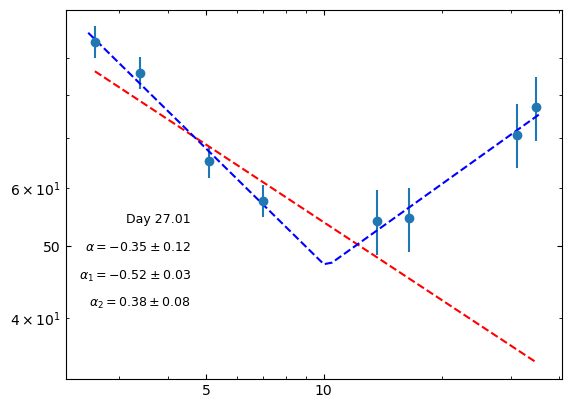

In [75]:
#plotting to check
x_freq = np.arange(2.5,36,0.5)
fig,ax = plt.subplots()
mask = df7['Flux Density (mJy)'] > 3 * df7['Uncertainty (mJy)']  # apply detection threshold
mask2 = df7['Flux Density (mJy)'] < 3 * df7['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df7['Freq (GHz)'][mask], df7['Flux Density (mJy)'][mask], yerr=yerr7, fmt='o')
    ax.scatter(df7['Freq (GHz)'][mask2], (df7['Flux Density (mJy)'][mask2] + 3*df7['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 27.01', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df7['Freq (GHz)'][mask], fit_model_weights7(df7['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.35 \\pm 0.12}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL7(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.52 \\pm 0.03}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.38 \\pm 0.08}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 29.02 (df8)

In [76]:
#(work for anything with 3+ points)
x8 = df8['Freq (GHz)'].values.tolist()
y8 = df8['Flux Density (mJy)'].values.tolist()
yerr8 = df8['Uncertainty (mJy)'].values.tolist()


In [77]:
yerr8 = error(yerr8, x8, y8)

In [78]:
PL8 =  PowerLaw1D(amplitude = y8[0], x_0= x8[0], alpha= -0.0) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit8 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model8 = fit8(PL8, x8, y8)


#weight is 1/error^2
y_weight8 = 1/ (np.power(yerr8, 2))  

# fit the data using the uncertainties as weights
fit_model_weights8 = fit8(PL8, x8, y8, weights=y_weight8)

fit_model_weights8


<PowerLaw1D(amplitude=106.38739247, x_0=0.62491869, alpha=0.24160238)>

In [79]:
fit8.fit_info

{'nfev': 12,
 'fvec': array([ 0.53180061, -0.67321408, -0.61017017,  0.35701518,  0.42600016,
        -0.03773915, -0.20438516, -0.59759314, -0.62027315]),
 'fjac': array([[-2.65860232e+01,  4.56941141e+00,  1.11259275e-01,
         -5.47410230e-01, -6.87136247e-01, -2.21181963e-01,
         -2.01644999e-01, -1.07415067e-01, -8.87042851e-02],
        [ 4.56941141e+00, -1.09131711e+00, -2.65721642e-02,
          4.77342708e-01,  1.95187220e-01, -1.24634089e-01,
         -1.48553968e-01, -1.29242187e-01, -1.12853213e-01],
        [ 1.11259275e-01, -2.65721642e-02,  6.19420177e-18,
         -2.80056017e-01,  7.00140042e-01, -0.00000000e+00,
          1.40028008e-01,  1.40028008e-01, -2.80056017e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([-6.20734405e-05,  1.52840441e-05, -2.82688915e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.60632940e+34, -6.34

In [80]:
#taking fvec
fvec8 = np.array([ 0.5318006 , -0.67321411, -0.6101702 ,  0.35701513,  0.42600011,
        -0.03773917, -0.20438517, -0.59759315, -0.62027315])
var8 = np.var(fvec8)

#taking cov_x
cov_x8 = np.array([[ 4.66395788e+34, -1.13561361e+33, -2.20555973e+16],
        [-1.13561361e+33,  2.76507273e+31,  5.37025359e+14],
        [-2.20555973e+16,  5.37025359e+14,  3.66481986e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag8 = stand(cov_x8*var8) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag8[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.08969156789410454


In [81]:
Xhi = cs(df8['Flux Density (mJy)'], fit_model_weights8( df8["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(9-4))

The chi squared for lin fit is 18.986136116499836


In [82]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM8 = bpl_func(x_val, y8, yerr8, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM8[50]

#Apply error as weighting in the function 

weight8 = 1/ (np.power(yerr8,2))
fw_BPL8 = fitBPL(BM8[50], x8, y8, weights=weight8)   
print(fw_BPL8)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 0.73450913, -0.56348122, -0.55437609,  0.28354979,  0.21028855,
       -0.0343208 ,  0.04149639,  0.01730486, -0.03058332]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 1.05295603e+02, -4.53460685e+01, -9.16193725e-01,
         5.36090042e+00],
       [-4.53460685e+01,  6.31330463e+01, -4.74883933e-01,
        -4.64809158e+00],
       [-9.16193725e-01, -4.74883933e-01,  3.16223748e-02,
        -3.46944695e-17],
       [ 5.36090042e+00, -4.64809158e+00, -3.46944695e-17,
         7.08467767e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df8['Flux Density (mJy)'], fw_BPL8( df8["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(9-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break             alpha_1             alpha_2      
    ----------------- ------------------ ------------------- -------------------
    48.39697592226432 12.560324555954608 0.29933116756914346 -0.5007065033448898

{'nfev': 14, 'fvec': array([ 0.73450913, -0.56348122, -0.55437609,  0.28354979,  0.21028855,
       -0.0343208 ,  0.04149639,  0.01730486, -0.03058332]), 'fjac': array([[-12.58464798,   0.49312156,   0.45697997,   0.49150972,
          0.34142069,   0.        ,   0.        ,   0.        ,
          0.        ],
       [  0.        ,  -1.79599511,   0.        ,   0.        ,
          0.        ,  -0.09229889,  -0.28620612,  -0.67948697,
         -0.66922674],
       [ -0.25093002,  -0.09635555,  -0.15143775,   0.42700402,
          0.70295103,  -0.4469525 ,  -0.32391451,   0.05419386,
          0.0927401 ],
       [ -0.21756526,   0.04994326,  -0.06521741,  -0.09

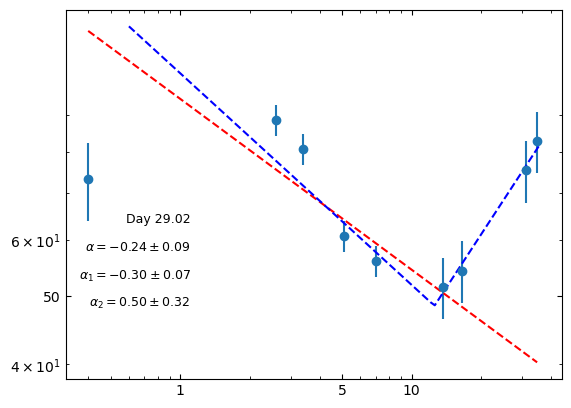

In [83]:
#plotting to check
x_freq = np.arange(.6,36,0.5)
fig,ax = plt.subplots()
mask = df8['Flux Density (mJy)'] > 3 * df8['Uncertainty (mJy)']  # apply detection threshold
mask2 = df8['Flux Density (mJy)'] < 3 * df8['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df8['Freq (GHz)'][mask], df8['Flux Density (mJy)'][mask], yerr=yerr8, fmt='o')
    ax.scatter(df8['Freq (GHz)'][mask2], (df8['Flux Density (mJy)'][mask2] + 3*df8['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 29.02', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df8['Freq (GHz)'][mask], fit_model_weights8(df8['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.24 \\pm 0.09}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    
    ax.plot(x_freq, fw_BPL8(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.30 \\pm 0.07}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.50 \\pm 0.32}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 32.04 (df9)

In [84]:
#(work for anything with 3+ points)
x9 = df9['Freq (GHz)'].values.tolist()
y9 = df9['Flux Density (mJy)'].values.tolist()
yerr9 = df9['Uncertainty (mJy)'].values.tolist()


In [85]:
yerr9 = error(yerr9, x9, y9)

In [86]:
PL9 =  PowerLaw1D(amplitude = y9[0], x_0= x9[0], alpha= -2.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit9 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model9 = fit9(PL9, x9, y9)


#weight is 1/error^2
y_weight9 = 1/ (np.power(yerr9, 2))  

# fit the data using the uncertainties as weights
fit_model_weights9 = fit9(PL9, x9, y9, weights=y_weight9)

fit_model_weights9


<PowerLaw1D(amplitude=57.10710557, x_0=3.73548865, alpha=0.09307237)>

In [87]:
fit9.fit_info

{'nfev': 14,
 'fvec': array([ 0.0234696 , -0.09639987,  0.13148827, -0.06752873]),
 'fjac': array([[-5.72791788,  0.11064064, -0.40589179, -0.79884524],
        [ 0.12915069, -0.3282116 ,  0.6015825 ,  0.6214943 ],
        [ 0.09076699, -0.23066682, -0.        ,  0.        ]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([-5.87143429e-06,  1.49204062e-05,  1.77491806e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': None,
 'njev': 10,
 'cov_x': None}

In [88]:
#taking fvec
fvec9 = np.array([ 0.023469  , -0.09640047,  0.13148761, -0.06752938])
var9 = np.var(fvec9)

#taking cov_x
cov_x9 = np.array([[ 5.19229686e+33, -2.09176179e+33, -2.58559815e+16],
        [-2.09176179e+33,  8.42684369e+32,  1.04163062e+16],
        [-2.58559815e+16,  1.04163062e+16,  1.63953322e-01]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag9 = stand(cov_x9*var9) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag9[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.03603082373439542


In [89]:
#Can't do xhi test, 4 points vs 4 params
#Xhi = cs(df9['Flux Density (mJy)'], fit_model_weights9( df9["Freq (GHz)"] ))
#print("The chi squared for lin fit is", Xhi/(4-4))

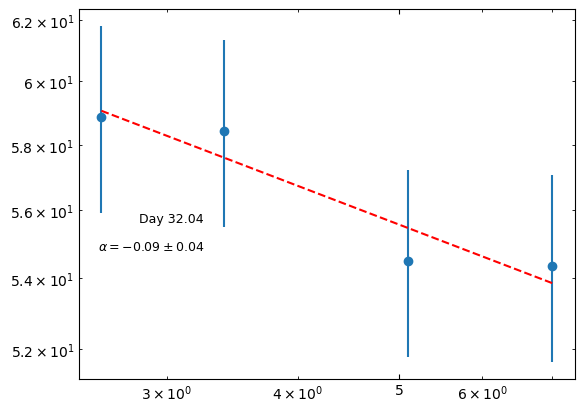

In [90]:
#plotting to check
fig,ax = plt.subplots()
mask = df9['Flux Density (mJy)'] > 3 * df9['Uncertainty (mJy)']  # apply detection threshold
mask2 = df9['Flux Density (mJy)'] < 3 * df9['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df9['Freq (GHz)'][mask], df9['Flux Density (mJy)'][mask], yerr=yerr9, fmt='o')
    ax.scatter(df9['Freq (GHz)'][mask2], (df9['Flux Density (mJy)'][mask2] + 3*df9['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 32.04', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df9['Freq (GHz)'][mask], fit_model_weights9(df9['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.09 \\pm 0.04}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 33.99 (df10)

In [91]:
#(work for anything with 3+ points)
x10 = df10['Freq (GHz)'].values.tolist()
y10 = df10['Flux Density (mJy)'].values.tolist()
yerr10 = df10['Uncertainty (mJy)'].values.tolist()

In [92]:
yerr10 = error(yerr10, x10, y10)

In [93]:
PL10 =  PowerLaw1D(amplitude = y10[0], x_0= x10[0], alpha= -2) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit10 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model10 = fit10(PL10, x10, y10)


#weight is 1/error^2
y_weight10 = 1/ (np.power(yerr10, 2))  

# fit the data using the uncertainties as weights
fit_model_weights10 = fit10(PL10, x10, y10, weights=y_weight10)

fit_model_weights10


<PowerLaw1D(amplitude=45.27256918, x_0=392.08075331, alpha=0.07440208)>

In [94]:
fit10.fit_info

{'nfev': 37,
 'fvec': array([-0.12824322, -0.11733527,  0.62804917, -0.96206439, -0.75103991,
         0.251642  ,  0.67230358,  0.08598357, -0.0105406 , -0.42092261,
        -0.45183619]),
 'fjac': array([[-7.28411606e+01, -3.17766563e-01, -2.73783186e-03,
          2.68631691e-01,  2.97747395e-01,  4.10338342e-01,
          4.32606167e-01,  8.69080980e-02,  7.49055761e-02,
          2.61049173e-02,  1.99561173e-02],
        [-3.17766563e-01,  6.69871251e-02,  5.77151617e-04,
         -8.10056727e-02, -1.70421395e-01, -4.28904230e-01,
         -6.40627787e-01, -2.32644084e-01, -2.32046826e-01,
         -1.30453988e-01, -1.08757782e-01],
        [-2.73783186e-03,  5.77151617e-04,  2.06425944e-19,
         -2.62612866e-01, -1.31306433e-01, -5.25225731e-01,
         -5.25225731e-01, -2.62612866e-01, -0.00000000e+00,
         -1.31306433e-01, -0.00000000e+00]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-3.77508656e-05, -1.93641503e-04, -2.57481483e-01]),
 'message': 'Both ac

In [95]:
#taking fvec
fvec10 = np.array([-0.12824302, -0.11733814,  0.62805568, -0.96206993, -0.75104795,
         0.25162638,  0.6722827 ,  0.08597693, -0.01054705, -0.42092602,
        -0.45183901])
var10 = np.var(fvec10)

#taking cov_x
cov_x10 = np.array([[ 3.78427899e+33, -9.37115868e+32, -1.56024166e+16],
        [-9.37115868e+32,  2.32061683e+32,  3.86368770e+15],
        [-1.56024166e+16,  3.86368770e+15,  6.87577976e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag10 = stand(cov_x10*var10) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag10[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.12958941434506968


In [96]:
Xhi = cs(df10['Flux Density (mJy)'], fit_model_weights10( df10["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(11-4))

The chi squared for lin fit is 8.238153420030638


In [97]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM10 = bpl_func(x_val, y10, yerr10, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM10[50]

#Apply error as weighting in the function 

weight10 = 1/ (np.power(yerr10,2))
fw_BPL10 = fitBPL(BM10[41], x10, y10, weights=weight10)   
print(fw_BPL10)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df10['Flux Density (mJy)'], fw_BPL10( df10["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(11-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break             alpha_1              alpha_2      
    ----------------- ------------------ -------------------- -------------------
    75.99455663341632 2.5999985533777643 -0.05526404457132402 0.27240652376013075

{'nfev': 38, 'fvec': array([-0.15584919,  0.17857814,  0.02270737, -0.3541064 , -0.31236647,
        0.33034039,  0.28030221, -0.2319399 , -0.35248143, -0.64094472,
       -0.63765765]), 'fjac': array([[-9.86588962e+00,  0.00000000e+00, -2.07164914e-03,
         1.28252004e-03,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -9.71504025e+00, -1.55456724e-02,
        -1.95246217e-03, -1.38324386e-01, -4.83106429e-01,
        -7.58569844e-01, -2.68735175e-01, -2.62812327e-01,
        -1.35666011e-01, -1.11140244e-01],
       [ 1.48188061e-01,  1.11125

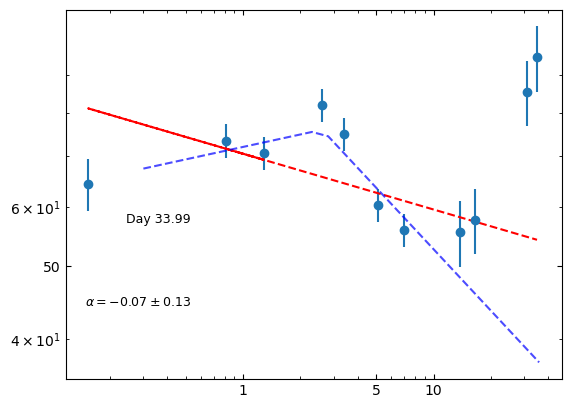

In [98]:
#plotting to check
x_freq = np.arange(0.3,36,0.5)
fig,ax = plt.subplots()
mask = df10['Flux Density (mJy)'] > 3 * df10['Uncertainty (mJy)']  # apply detection threshold
mask2 = df10['Flux Density (mJy)'] < 3 * df10['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df10['Freq (GHz)'][mask], df10['Flux Density (mJy)'][mask], yerr=yerr10, fmt='o')
    ax.scatter(df10['Freq (GHz)'][mask2], (df10['Flux Density (mJy)'][mask2] + 3*df10['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 33.99', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df10['Freq (GHz)'][mask], fit_model_weights10(df10['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.07 \\pm 0.13}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL10(x_freq), 'b--', alpha=0.7)
plt.show();


## Day 36.01 (df11)

In [99]:
#(work for anything with 3+ points)
x11 = df11['Freq (GHz)'].values.tolist()
y11 = df11['Flux Density (mJy)'].values.tolist()
yerr11 = df11['Uncertainty (mJy)'].values.tolist()


In [100]:
yerr11 = error(yerr11, x11, y11)

In [101]:
PL11 =  PowerLaw1D(amplitude = y11[0], x_0= x11[0], alpha= -2.0) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit11 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model11 = fit11(PL11, x11, y11)


#weight is 1/error^2
y_weight11 = 1/ (np.power(yerr11, 2))  

# fit the data using the uncertainties as weights
fit_model_weights11 = fit11(PL11, x11, y11, weights=y_weight11)

fit_model_weights11


<PowerLaw1D(amplitude=35.27171414, x_0=750.27824788, alpha=0.10332279)>

In [102]:
fit11.fit_info

{'nfev': 40,
 'fvec': array([-0.78708617, -0.55203747,  0.30765812,  0.36488555, -0.10970024,
        -0.21888172, -0.50810904, -0.51398622,  0.56582961,  0.18147406,
        -0.3196544 ]),
 'fjac': array([[-8.41862401e+01, -4.26110150e-01, -2.06977052e-03,
          4.27881235e-01,  7.83548834e-02,  6.52859576e-02,
          2.17070550e-02,  1.64650110e-02,  4.30156367e-01,
          2.98662207e-01,  3.59493372e-01],
        [-4.26110150e-01, -6.77381152e-02, -3.29028430e-04,
          5.40780184e-01,  1.98102229e-01,  1.93057298e-01,
          1.04089410e-01,  8.58010090e-02, -2.95072462e-01,
         -4.51100795e-01, -4.43668651e-01],
        [-2.06977052e-03, -3.29028430e-04, -4.76511557e-19,
          2.84411300e-01,  1.13764520e-01,  8.53233901e-02,
          4.26616950e-02,  0.00000000e+00,  8.24792770e-01,
          1.70646780e-01,  3.98175820e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 2.37287596e-06, -2.01574848e-07, -8.54490174e-01]),
 'message': 'Both ac

In [103]:
#taking fvec
fvec11 = np.array([-0.78708616, -0.55203747,  0.30765812,  0.36488556, -0.10970024,
        -0.21888172, -0.50810904, -0.51398622,  0.56582961,  0.18147406,
        -0.3196544 ])
var11 = np.var(fvec11)

#taking cov_x
cov_x11 = np.array([[ 1.96819570e+32, -4.05873039e+34, -9.58112736e+13],
        [-4.05873039e+34,  8.36974308e+36,  1.97577978e+16],
        [-9.58112736e+13,  1.97577978e+16,  5.77109362e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag11 = stand(cov_x11*var11) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag11[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.03206640936212815


In [104]:
Xhi = cs(df11['Flux Density (mJy)'], fit_model_weights11( df11["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(11-4))

The chi squared for lin fit is 15.220629153680301


In [105]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM11 = bpl_func(x_val, y11, yerr11, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM11[50]

#Apply error as weighting in the function 

weight11 = 1/ (np.power(yerr11,2))
fw_BPL11 = fitBPL(BM11[50], x11, y11, weights=weight11)   
print(fw_BPL11)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [-0.79869847, -0.58318651,  0.22769339,  0.25135874, -0.04616562,
        0.05656259,  0.0094999 , -0.03034674,  0.59704477,  0.24659855,
       -0.25888486]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 5.19154736e+01, -2.41498209e+01, -3.95244667e-01,
         3.12829098e+00],
       [-2.41498209e+01,  8.16908621e+01, -1.49540080e-01,
        -6.48831918e+00],
       [-3.95244667e-01, -1.49540080e-01,  6.19143911e-03,
         0.00000000e+00],
       [ 3.12829098e+00, -6.48831918e+00,  0.00000000e+00,
         1.02391702e+00]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df11['Flux Density (mJy)'], fw_BPL11( df11["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(11-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break             alpha_1             alpha_2      
    ----------------- ------------------ ------------------- -------------------
    52.61056679002901 12.629932582214385 0.11574544067856513 -0.6345052291397322

{'nfev': 11, 'fvec': array([-0.79869847, -0.58318651,  0.22769339,  0.25135874, -0.04616562,
        0.05656259,  0.0094999 , -0.03034674,  0.59704477,  0.24659855,
       -0.25888486]), 'fjac': array([[-24.96315416,   0.2780863 ,   0.2648536 ,   0.17949458,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.51379858,   0.45970462,   0.51118882],
       [  0.        ,  -1.44962202,   0.        ,   0.        ,
         -0.09600934,  -0.31628252,  -0.67863432,  -0.65589865,
          0.        ,   0.        ,   0.        ],
       [ -0.24499888,   0.03917954,  -0.14944329,   0.65653323,
          0.21111193,   0.19657112,   0.09250319,   0.

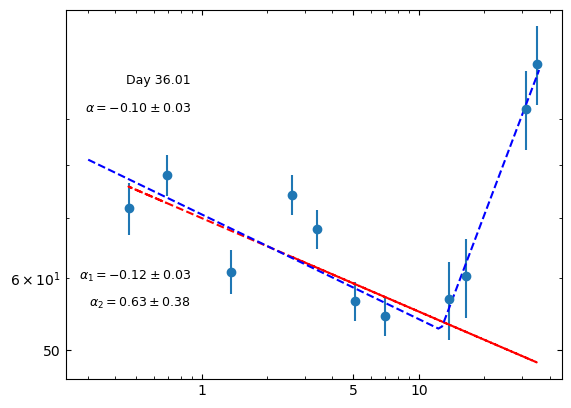

In [106]:
#plotting to check
x_freq = np.arange(.3,36,0.5)
fig,ax = plt.subplots()
mask = df11['Flux Density (mJy)'] > 3 * df11['Uncertainty (mJy)']  # apply detection threshold
mask2 = df11['Flux Density (mJy)'] < 3 * df11['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df11['Freq (GHz)'][mask], df11['Flux Density (mJy)'][mask], yerr=yerr11, fmt='o')
    ax.scatter(df11['Freq (GHz)'][mask2], (df11['Flux Density (mJy)'][mask2] + 3*df11['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 36.01', xy=(90, 220), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df11['Freq (GHz)'][mask], fit_model_weights11(df11['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.10 \\pm 0.03}$', xy=(90, 200), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL11(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.12 \\pm 0.03}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.63 \\pm 0.38}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 53.96 (df12)

In [107]:
#(work for anything with 3+ points)
mask = df12['Flux Density (mJy)'] > 3 * df12['Uncertainty (mJy)']  # apply detection threshold
x12 = df12['Freq (GHz)'][mask].values.tolist()
y12 = df12['Flux Density (mJy)'][mask].values.tolist()
yerr12 = df12['Uncertainty (mJy)'][mask].values.tolist()


In [108]:
yerr12 = error(yerr12, x12, y12)

In [109]:
PL12 =  PowerLaw1D(amplitude = y12[0], x_0= x12[5], alpha= -3.0) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit12 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model12 = fit12(PL12, x12, y12)


#weight is 1/error^2
y_weight12 = 1/ (np.power(yerr12, 2))  

# fit the data using the uncertainties as weights
fit_model_weights12 = fit12(PL12, x12, y12, weights=y_weight12)

fit_model_weights12


<PowerLaw1D(amplitude=20.07780455, x_0=1401.689986, alpha=0.16924929)>

In [110]:
fit12.fit_info

{'nfev': 48,
 'fvec': array([-0.10496422, -0.09010199, -0.66664894, -0.55844151,  0.33168525,
         0.59008538, -0.28044705, -0.42170059, -0.63476925, -0.61635097,
         0.0380162 , -0.09431788,  1.04235046]),
 'fjac': array([[-1.12724108e+02, -8.86594143e-01, -2.14577593e-03,
          3.21022603e-01,  4.15937712e-01,  4.35559156e-01,
          6.84659749e-02,  5.42080262e-02,  1.52494056e-02,
          1.15158999e-02,  2.42571664e-01,  3.17501570e-01,
          1.30507450e-01],
        [-8.86594143e-01,  1.36088783e-01,  3.29368332e-04,
         -1.60036499e-01, -4.13033912e-01, -6.23648645e-01,
         -1.75337184e-01, -1.59045233e-01, -6.83032482e-02,
         -5.54728642e-02,  2.26996346e-01,  3.88489580e-01,
          2.41408258e-01],
        [-2.14577593e-03,  3.29368332e-04, -6.11039024e-19,
          2.77243487e-01,  5.32307494e-01,  5.32307494e-01,
          1.55256352e-01,  7.76281762e-02,  2.21794789e-02,
          3.32692184e-02,  3.10512705e-01,  4.43589578e-01,
  

In [111]:
#taking fvec
fvec12 = np.array([-0.10496418, -0.09010196, -0.66664891, -0.55844147,  0.33168529,
         0.59008543, -0.28044704, -0.42170058, -0.63476925, -0.61635097,
         0.03801622, -0.09431785,  1.04235047])
var12 = np.var(fvec12)

#taking cov_x
cov_x12 = np.array([[ 1.45458766e+31, -6.06055917e+33,  1.11030612e+14],
        [-6.06055917e+33,  2.52514018e+36, -4.62610548e+16],
        [ 1.11030612e+14, -4.62610548e+16,  4.26640215e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag12 = stand(cov_x12*var12) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag12[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.032429619764712


In [112]:
Xhi = cs(df12['Flux Density (mJy)'], fit_model_weights12( df12["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(13-4))

The chi squared for lin fit is 28.996955161606266


In [113]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM12 = bpl_func(x_val, y12, yerr12, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM12[50]

#Apply error as weighting in the function 

weight12 = 1/ (np.power(yerr12,2))
fw_BPL12 = fitBPL(BM12[50], x12, y12, weights=weight12)   
print(fw_BPL12)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [-0.08761636, -0.04835082, -0.68906741, -0.59946739,  0.24070312,
        0.4597684 , -0.04774566,  0.06075069,  0.00222563, -0.02608893,
        0.0715886 , -0.03321794,  1.08295479]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 3.48436489e+01, -2.64873869e+01, -1.83909388e-01,
         3.57472876e+00],
       [-2.64873869e+01,  4.73608863e+01, -6.47519431e-02,
        -5.22868881e+00],
       [-1.83909388e-01, -6.47519431e-02,  3.57824694e-03,
         1.90819582e-17],
       [ 3.57472876e+00, -5.22868881e+00,  1.90819582e-17,
         9.63730151e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df12['Flux Density (mJy)'], fw_BPL12( df12["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(13-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break             alpha_1             alpha_2      
    ------------------ ------------------ ------------------- -------------------
    44.316304020010804 11.627692058854922 0.17938298452075044 -0.7452047341138588

{'nfev': 12, 'fvec': array([-0.08761636, -0.04835082, -0.68906741, -0.59946739,  0.24070312,
        0.4597684 , -0.04774566,  0.06075069,  0.00222563, -0.02608893,
        0.0715886 , -0.03321794,  1.08295479]), 'fjac': array([[-3.05615499e+01,  4.78743880e-01,  2.65279590e-01,
         2.40078155e-01,  2.22620109e-01,  1.51635538e-01,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  3.34829976e-01,  4.79849015e-01,
         2.35388836e-01],
       [ 0.00000000e+00, -1.65441342e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -1.88331389e-01, -3.92956676e-01, -6.47124005e-01,
        

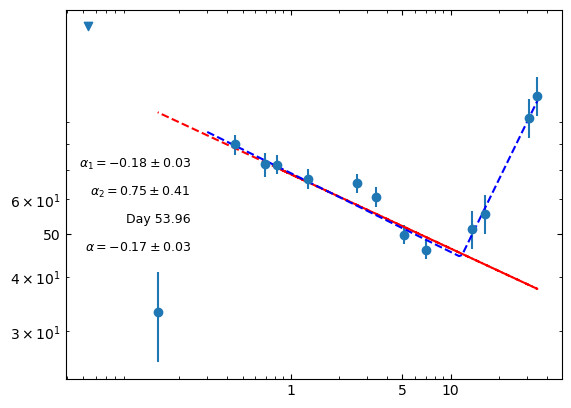

In [114]:
#plotting to check
x_freq = np.arange(.3,36,0.5)
fig,ax = plt.subplots()
mask = df12['Flux Density (mJy)'] > 3 * df12['Uncertainty (mJy)']  # apply detection threshold
mask2 = df12['Flux Density (mJy)'] < 3 * df12['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df12['Freq (GHz)'][mask], df12['Flux Density (mJy)'][mask], yerr= yerr12 , fmt='o')
    ax.scatter(df12['Freq (GHz)'][mask2], (df12['Flux Density (mJy)'][mask2] + 3*df12['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 53.96', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df12['Freq (GHz)'][mask], fit_model_weights12(df12['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.17 \\pm 0.03}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL12(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.18 \\pm 0.03}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.75 \\pm 0.41}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


----

# Day 60-65 (df12_5)

In [115]:
#(work for anything with 3+ points)
mask = df12_5['Flux Density (mJy)'] > 3 * df12_5['Uncertainty (mJy)']  # apply detection threshold
x12_5 = df12_5['Freq (GHz)'][mask].values.tolist()
y12_5 = df12_5['Flux Density (mJy)'][mask].values.tolist()
yerr12_5 = df12_5['Uncertainty (mJy)'][mask].values.tolist()


In [116]:
yerr12_5 = error(yerr12_5, x12_5, y12_5)

In [117]:
PL12_5 =  PowerLaw1D(amplitude = y12_5[0], x_0= x12_5[0], alpha = -4) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit12_5 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model12_5 = fit12(PL12_5, x12_5, y12_5)


#weight is 1/error^2
y_weight12_5 = 1/ (np.power(yerr12_5, 2))  

# fit the data using the uncertainties as weights
fit_model_weights12_5 = fit12_5(PL12_5, x12_5, y12_5, weights=y_weight12_5)

fit_model_weights12_5


<PowerLaw1D(amplitude=53.53744813, x_0=43.49937631, alpha=0.01278136)>

In [118]:
# fit12_5.fit_info

In [119]:
#taking fvec
fvec12_5 = np.array([ 0.12622368, -0.21611396, -0.3191237 ,  0.31566641,  0.25224755] )
var12_5 = np.var(fvec12_5)

#taking cov_x
cov_x12_5 = np.array( [[ 4.88658692e+33, -3.20533687e+32,  9.83637653e+15],
        [-3.20533687e+32,  2.10252771e+31, -6.45213128e+14],
        [ 9.83637653e+15, -6.45213128e+14,  5.00128399e-02]] )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag12_5 = stand(cov_x12_5*var12_5) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag12_5[2]) #Just showing the standard deviation on the slope


The error/standard deviation is 0.056814147388601445


In [120]:
Xhi = cs(df12_5['Flux Density (mJy)'], fit_model_weights12_5( df12_5["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(5-4))

The chi squared for lin fit is 2.1970195079132364


In [121]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(.1,2,0.1)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM12_5 = bpl_func(x_val, y12_5, yerr12_5, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL

#Apply error as weighting in the function 

weight12_5 = 1/ (np.power(yerr12_5,2))
fw_BPL12_5 = fitBPL(BM12_5[30], x12_5, y12_5, weights=weight12_5)   
print(fw_BPL12_5)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 4.07567737e-02, -4.07851406e-02,  2.83010743e-02,  1.07537113e-06,
       -1.95604443e-03] )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 9.23074997e+33,  1.66194671e+33, -2.14137287e+16,
         1.76763207e+33],
       [ 1.66194671e+33,  2.99224534e+32, -3.85542627e+15,
         3.18252612e+32],
       [-2.14137287e+16, -3.85542627e+15,  1.15875583e-01,
        -4.10059786e+15],
       [ 1.76763207e+33,  3.18252612e+32, -4.10059786e+15,
         3.38490712e+32]] )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope

Xhi = cs(df12_5['Flux Density (mJy)'], fw_BPL12_5( df12_5["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(5-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break             alpha_1             alpha_2      
    ----------------- ------------------ -------------------- ------------------
    59.86270821205318 0.8880469113133804 -0.08083959965714381 0.2997050426440833

{'nfev': 14, 'fvec': array([ 4.07567731e-02, -4.07851442e-02,  2.83010697e-02,  1.09395915e-06,
       -1.95604608e-03]), 'fjac': array([[-4.66234568e+00,  0.00000000e+00,  4.41462121e-01,
        -8.10119039e-02,  8.88713333e-01],
       [ 0.00000000e+00, -2.59601042e+00,  2.37617586e+00,
         1.17615369e-01,  0.00000000e+00],
       [ 4.41462121e-01,  2.37617586e+00,  6.66280085e-01,
        -1.22267836e-01, -2.03241536e-01],
       [-8.10119039e-02,  1.17615369e-01, -1.22267836e-01,
         1.38777878e-17, -0.00000000e+00]]), 'ipvt': array([2, 3, 1, 0], dtype=int32), 'qtf': array([-3.26721977e-08,  1.09395915e-06, -4.93435697e-08,  5.81868135e-02]), 'mess

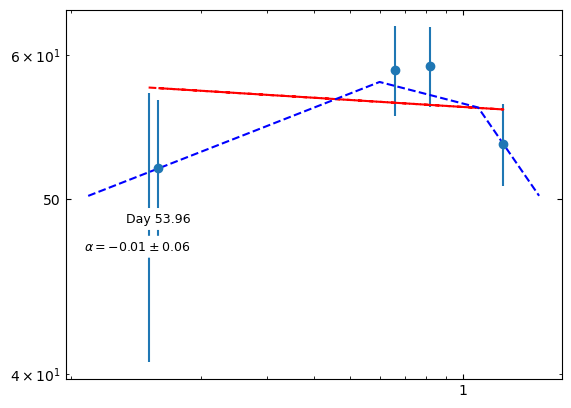

In [122]:
#plotting to check
x_freq = np.arange(0.1,2,0.5)
fig,ax = plt.subplots()
mask = df12_5['Flux Density (mJy)'] > 3 * df12_5['Uncertainty (mJy)']  # apply detection threshold
mask2 = df12_5['Flux Density (mJy)'] < 3 * df12_5['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df12_5['Freq (GHz)'][mask], df12_5['Flux Density (mJy)'][mask], yerr= yerr12_5 , fmt='o')
    ax.scatter(df12_5['Freq (GHz)'][mask2], (df12_5['Flux Density (mJy)'][mask2] + 3*df12_5['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 53.96', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df12_5['Freq (GHz)'][mask], fit_model_weights12_5(df12_5['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.01 \\pm 0.06}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL12_5(x_freq), 'b--')
    #ax.annotate('${\u03B1_1 = -0.08 \\pm 0.01}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    #ax.annotate('${\u03B1_2 = 0.28 \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 76.94 (df13)

In [123]:
#(work for anything with 3+ points)
x13 = df13['Freq (GHz)'].values.tolist()
y13 = df13['Flux Density (mJy)'].values.tolist()
yerr13 = df13['Uncertainty (mJy)'].values.tolist()


In [124]:
yerr13 = error(yerr13, x13, y13)

In [125]:
PL13 =  PowerLaw1D(amplitude = y13[0], x_0= x13[0], alpha= -0.3) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit13 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model13 = fit13(PL13, x13, y13)


#weight is 1/error^2
y_weight13 = 1/ (np.power(yerr13, 2))  

# fit the data using the uncertainties as weights
fit_model_weights13 = fit13(PL13, x13, y13, weights=y_weight13)

fit_model_weights13


<PowerLaw1D(amplitude=30.05040573, x_0=3.24083816, alpha=-0.35932405)>

In [126]:
fit13.fit_info

{'nfev': 11,
 'fvec': array([ 0.18417952, -0.17130295, -0.3267363 ,  0.27771724]),
 'fjac': array([[-1.00543368e+01, -1.08942672e+00,  3.27002430e-01,
         -8.14414364e-01],
        [-1.08942672e+00,  2.49230326e+00, -7.48089990e-01,
          6.05172980e-01],
        [ 3.27002430e-01, -7.48089990e-01, -5.55111512e-17,
          1.00000000e+00]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([-9.88540682e-08, -9.13139536e-08, -4.53857902e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 3.24518554e+32,  9.74075208e+31, -6.98237631e+15],
        [ 9.74075208e+31,  2.92378510e+31, -2.09583076e+15],
        [-6.98237631e+15, -2.09583076e+15,  1.62015881e-01]]),
 'njev': 5,
 'cov_x': array([[ 3.24518554e+32,  9.74075208e+31, -6.98237631e+15],
        [ 9.74075208e+31,  2.92378510e+31, -2.09583076e+15],
        [-6.98237631e+15, -2.09583076e+15,  1.62015881e-01

In [127]:
#taking fvec
fvec13 = np.array([ 0.18418854, -0.17129513, -0.32672975,  0.27772379])
var13 = np.var(fvec13)

#taking cov_x
cov_x13 = np.array([[ 7.63573067e+31,  3.45978229e+31, -6.93752964e+14],
        [ 3.45978229e+31,  1.56764218e+31, -3.14342441e+14],
        [-6.93752964e+14, -3.14342441e+14,  1.80854738e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag13 = stand(cov_x13*var13) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag13[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.033406336954901986


In [128]:
#CAN'T DO XHI SQUARED TEST - 4 POINTS
#@Xhi = cs(df13['Flux Density (mJy)'], fit_model_weights13( df13["Freq (GHz)"] ))
#print("The chi squared for lin fit is", Xhi/(4-4))

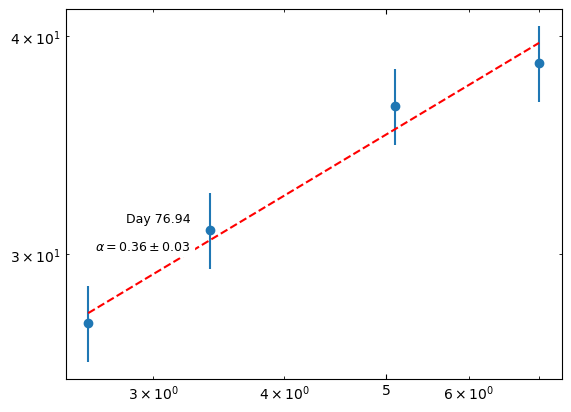

In [129]:
#plotting to check
fig,ax = plt.subplots()
mask = df13['Flux Density (mJy)'] > 3 * df13['Uncertainty (mJy)']  # apply detection threshold
mask2 = df13['Flux Density (mJy)'] < 3 * df13['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df13['Freq (GHz)'][mask], df13['Flux Density (mJy)'][mask], yerr=yerr13, fmt='o')
    ax.scatter(df13['Freq (GHz)'][mask2], (df13['Flux Density (mJy)'][mask2] + 3*df13['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 76.94', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df13['Freq (GHz)'][mask], fit_model_weights13(df13['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.36 \\pm 0.03}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 77.92 (df14)

In [130]:
#(work for anything with 3+ points)
x14 = df14['Freq (GHz)'].values.tolist()
y14 = df14['Flux Density (mJy)'].values.tolist()
yerr14 = df14['Uncertainty (mJy)'].values.tolist()


In [131]:
yerr14 = error(yerr14, x14, y14)

In [132]:
PL14 =  PowerLaw1D(amplitude = y14[0], x_0= x14[0], alpha= -2.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit14 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model14 = fit14(PL14, x14, y14)


#weight is 1/error^2
y_weight14 = 1/ (np.power(yerr14, 2))  

# fit the data using the uncertainties as weights
fit_model_weights14 = fit14(PL14, x14, y14, weights=y_weight14)

fit_model_weights14


<PowerLaw1D(amplitude=58.03608298, x_0=751.16789052, alpha=-0.08757132)>

In [133]:
fit14.fit_info

{'nfev': 49,
 'fvec': array([-0.24495836, -0.08427116,  0.38201415,  0.08799325, -0.23463315,
        -0.34695765, -0.56292819, -0.56346721]),
 'fjac': array([[-1.13765454e+02, -3.77239006e-01,  2.55008834e-03,
          4.33580851e-01,  6.86152652e-02,  5.50465774e-02,
          1.94543049e-02,  1.53022978e-02],
        [-3.77239006e-01,  2.96191650e-02, -2.00221839e-04,
         -7.73059928e-01, -2.85102238e-01, -2.73004405e-01,
         -1.63552383e-01, -1.40582046e-01],
        [ 2.55008834e-03, -2.00221839e-04, -2.35347156e-19,
         -5.75852601e-01, -1.15170520e-01,  0.00000000e+00,
         -5.75852601e-02, -4.31889450e-02]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 9.44457476e-06,  5.35917880e-05, -3.64405784e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[8.25010282e+32, 1.22045207e+35, 9.59725672e+14],
        [1.22045207e+35, 1.80543598e+

In [134]:
#taking fvec
fvec14 = np.array([-0.24495612, -0.08426903,  0.3820162 ,  0.087995  , -0.23463288,
        -0.34695743, -0.56292812, -0.56346715])
var14 = np.var(fvec14)

#taking cov_x
cov_x14 = np.array([[ 2.20742346e+32,  3.26775728e+34, -4.84398139e+14],
        [ 3.26775728e+34,  4.83742148e+36, -7.17078338e+16],
        [-4.84398139e+14, -7.17078338e+16,  1.36735631e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag14 = stand(cov_x14*var14) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag14[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.03516743783027706


In [135]:
Xhi = cs(df14['Flux Density (mJy)'], fit_model_weights14( df14["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 18.787647004615945


In [136]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM14 = bpl_func(x_val, y14, yerr14, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM14[50]

#Apply error as weighting in the function 

weight14 = 1/ (np.power(yerr14,2))
fw_BPL14 = fitBPL(BM14[50], x14, y14, weights=weight14)   
print(fw_BPL14)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [-0.06249289, -0.02587526,  0.24679589, -0.1767169 , -0.03175771,
        0.04133682,  0.00755522, -0.02261267]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 2.89765739e+01,  2.30199109e+01, -6.00290759e-01,
        -9.71474026e-01],
       [ 2.30199109e+01,  8.03094427e+01, -2.43262049e-01,
        -6.11451608e+00],
       [-6.00290759e-01, -2.43262049e-01,  1.53296080e-02,
        -2.08166817e-17],
       [-9.71474026e-01, -6.11451608e+00, -2.08166817e-17,
         7.18094369e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df14['Flux Density (mJy)'], fw_BPL14( df14["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break              alpha_1              alpha_2      
    ------------------ ------------------ --------------------- -------------------
    38.314533539031785 10.837292823835869 -0.044937975768769824 -0.6979758178651518

{'nfev': 7, 'fvec': array([-0.06249289, -0.02587526,  0.24679589, -0.1767169 , -0.03175771,
        0.04133682,  0.00755522, -0.02261267]), 'fjac': array([[-22.28455623,   0.56734771,   0.38149248,   0.20168161,
          0.        ,   0.        ,   0.        ,   0.        ],
       [  0.        ,  -2.1068588 ,   0.        ,   0.        ,
         -0.23938499,  -0.40460482,  -0.63309639,  -0.61496238],
       [ -0.52834324,   0.07354769,  -0.21139172,   0.81299611,
          0.1973061 ,   0.13483073,  -0.02458624,  -0.03883976],
       [  0.08394315,  -0.18149153,   0.06059336,  -0.11158779,
         -0.76647351,  -0.4580649 ,   0.27624897,   0.33139031]

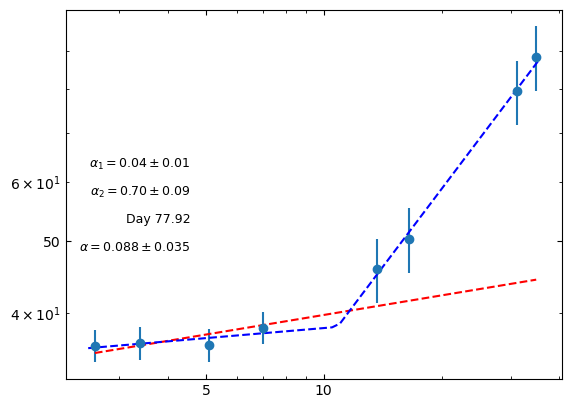

In [137]:
#plotting to check

fig,ax = plt.subplots()

x_freq = np.arange(2.5,36,0.5)
mask = df14['Flux Density (mJy)'] > 3 * df14['Uncertainty (mJy)']  # apply detection threshold
mask2 = df14['Flux Density (mJy)'] < 3 * df14['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df14['Freq (GHz)'][mask], df14['Flux Density (mJy)'][mask], yerr=yerr14, fmt='o')
    ax.scatter(df14['Freq (GHz)'][mask2], (df14['Flux Density (mJy)'][mask2] + 3*df14['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 77.92', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df14['Freq (GHz)'][mask], fit_model_weights14(df14['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.088 \\pm 0.035}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL14(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = 0.04 \\pm 0.01}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.70 \\pm 0.09}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 89.82 (df15)

In [138]:
#(work for anything with 3+ points)
x15 = df15['Freq (GHz)'].values.tolist()
y15 = df15['Flux Density (mJy)'].values.tolist()
yerr15 = df15['Uncertainty (mJy)'].values.tolist()


In [139]:
yerr15 = error(yerr15, x15, y15)

In [140]:
PL15 =  PowerLaw1D(amplitude = y15[0], x_0= x15[0], alpha= -3.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit15 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model15 = fit15(PL15, x15, y15)


#weight is 1/error^2
y_weight15 = 1/ (np.power(yerr15, 2))  

# fit the data using the uncertainties as weights
fit_model_weights15 = fit15(PL15, x15, y15, weights=y_weight15)

fit_model_weights15


<PowerLaw1D(amplitude=35.88512426, x_0=823.80312691, alpha=-0.01903366)>

In [141]:
fit15.fit_info

{'nfev': 63,
 'fvec': array([-0.29418421, -0.07334053,  0.28593966,  0.2686574 , -0.33907932,
        -0.47579482, -0.74097127, -0.73560636]),
 'fjac': array([[-1.31035226e+02, -6.93693548e-01,  5.74449840e-04,
          4.63200549e-01,  7.14186224e-02,  5.77049904e-02,
          1.93289245e-02,  1.53038181e-02],
        [-6.93693548e-01,  5.41379642e-02, -4.48318209e-05,
         -7.89263177e-01, -2.87178769e-01, -2.77182113e-01,
         -1.57279027e-01, -1.36002764e-01],
        [ 5.74449840e-04, -4.48318209e-05, -1.25752304e-19,
          3.23314804e-01,  2.42486103e-01,  3.23314804e-01,
          1.34714502e-01,  1.27978776e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 4.38565044e-06,  3.41733010e-05, -3.21753064e-02]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 4.33647667e+31,  5.23663804e+34, -4.06460813e+13],
        [ 5.23663804e+34,  6.32365

In [142]:
#taking fvec
fvec15 = np.array([-0.29418409, -0.0733404 ,  0.2859398 ,  0.26865753, -0.33907929,
        -0.4757948 , -0.74097126, -0.73560635])
var15 = np.var(fvec15)

#taking cov_x
cov_x15 = np.array([[ 8.50934237e+31,  1.02974502e+35, -9.03982898e+13],
        [ 1.02974502e+35,  1.24613015e+38, -1.09394105e+17],
        [-9.03982898e+13, -1.09394105e+17,  9.71641816e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag15 = stand(cov_x15*var15) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag15[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.036945082256276726


In [143]:
Xhi = cs(df15['Flux Density (mJy)'], fit_model_weights15( df15["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 19.824455412691805


In [144]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM15 = bpl_func(x_val, y15, yerr15, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM15[43]

#Apply error as weighting in the function 

weight15 = 1/ (np.power(yerr15,2))
fw_BPL15 = fitBPL(BM15[43], x15, y15, weights=weight15)   
print(fw_BPL15)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array(  [-0.05172476,  0.01418883,  0.12199207, -0.08880666, -0.04806636,
        0.06230698,  0.00221865, -0.02496281] )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 1.07639329e+01,  1.24507698e+00, -3.22681288e-01,
         3.45341132e-01],
       [ 1.24507698e+00,  4.54364931e+01, -1.57511983e-01,
        -3.86144483e+00],
       [-3.22681288e-01, -1.57511983e-01,  1.16627405e-02,
         3.46944695e-18],
       [ 3.45341132e-01, -3.86144483e+00,  3.46944695e-18,
         4.95254299e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df15['Flux Density (mJy)'], fw_BPL15( df15["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break             alpha_1              alpha_2      
    ------------------ ------------------ -------------------- -------------------
    31.447115433795805 10.665049635980036 0.030330579348881257 -0.6947716705401991

{'nfev': 11, 'fvec': array([-0.05172476,  0.01418883,  0.12199207, -0.08880666, -0.04806636,
        0.06230698,  0.00221865, -0.02496281]), 'fjac': array([[-2.44669813e+01,  5.73558281e-01,  3.81947995e-01,
         2.12852752e-01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -2.59834316e+00,  0.00000000e+00,
         0.00000000e+00, -2.48140653e-01, -4.14993759e-01,
        -6.24346691e-01, -6.13512515e-01],
       [-7.25961455e-01,  1.09252088e-01, -3.05283893e-01,
         8.32029646e-01,  1.91561880e-01,  1.29237645e-01,
        -3.49004564e-02, -4.93817098e-02],
       [-6.49250117e-02, -2.23815

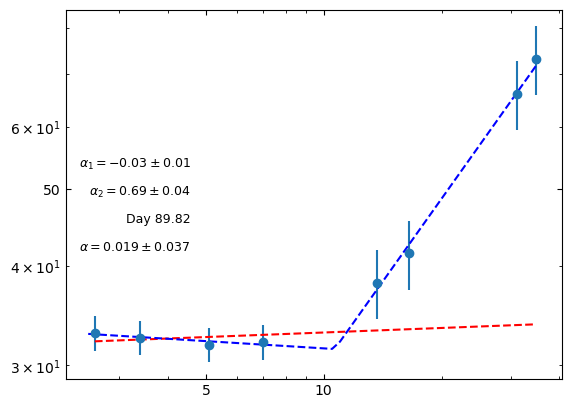

In [145]:
#plotting to check
fig,ax = plt.subplots()
x_freq = np.arange(2.5,36,0.5)
mask = df15['Flux Density (mJy)'] > 3 * df15['Uncertainty (mJy)']  # apply detection threshold
mask2 = df15['Flux Density (mJy)'] < 3 * df15['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df15['Freq (GHz)'][mask], df15['Flux Density (mJy)'][mask], yerr=yerr15, fmt='o')
    ax.scatter(df15['Freq (GHz)'][mask2], (df15['Flux Density (mJy)'][mask2] + 3*df15['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 89.82', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df15['Freq (GHz)'][mask], fit_model_weights15(df15['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.019 \\pm 0.037}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL15(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.03 \\pm 0.01}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.69 \\pm 0.04}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 140.76 (df16)

In [146]:
#(work for anything with 3+ points)
x16 = df16['Freq (GHz)'].values.tolist()
y16 = df16['Flux Density (mJy)'].values.tolist()
yerr16 = df16['Uncertainty (mJy)'].values.tolist()


In [147]:
yerr16 = error(yerr16, x16, y16)

In [158]:
PL16 =  PowerLaw1D(amplitude = y16[0], x_0= x16[0], alpha= 0) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit16 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model16 = fit16(PL16, x16, y16)


#weight is 1/error^2
y_weight16 = 1/ (np.power(yerr16, 2))  

# fit the data using the uncertainties as weights
fit_model_weights16 = fit16(PL16, x16, y16, weights=y_weight16)

fit_model_weights16


<PowerLaw1D(amplitude=21.05890253, x_0=0.89833662, alpha=0.09192995)>

In [159]:
fit16.fit_info

{'nfev': 12,
 'fvec': array([ 0.14621385, -2.45031717,  1.42276623,  1.09218986,  0.61300041,
        -2.18448905, -1.38813609, -1.49116433, -1.50565431, -1.4365385 ]),
 'fjac': array([[-6.87528460e+01,  4.18747963e+00,  1.93724296e+00,
         -4.41366855e-01, -5.91306741e-01, -5.44951581e-01,
         -1.01947950e-01, -9.39416783e-02, -4.36892685e-02,
         -3.58691412e-02],
        [ 4.18747963e+00, -2.26539154e+00, -1.04803228e+00,
          4.67635932e-01,  3.04670426e-01,  1.30500568e-01,
         -1.36044512e-02, -1.93827580e-02, -1.73591553e-02,
         -1.52431464e-02],
        [ 1.93724296e+00, -1.04803228e+00, -4.56034354e-16,
          8.52080671e-01,  1.21725810e-01,  1.21725810e-01,
         -6.46668367e-02, -4.56471788e-02, -7.60786314e-03,
         -3.04314526e-02]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([-1.65217130e-04,  5.39909328e-04, -2.88892984e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at m

In [160]:
#taking fvec
fvec16 = np.array([ 0.14621423, -2.4503169 ,  1.42276738,  1.09219109,  0.61300181,
        -2.18448788, -1.3881359 , -1.49116417, -1.50565424, -1.43653844])
var16 = np.var(fvec16)

#taking cov_x
cov_x16 = np.array([[ 1.51774966e+31, -4.77513541e+33,  2.26382430e+13],
        [-4.77513541e+33,  1.50235041e+36, -7.12243122e+15],
        [ 2.26382430e+13, -7.12243122e+15,  9.68135574e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag16 = stand(cov_x16*var16) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag16[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.04141105925613627


In [161]:
Xhi = cs(df16['Flux Density (mJy)'], fit_model_weights16( df16["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(10-4))

The chi squared for lin fit is 21.73081376611222


In [162]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM16 = bpl_func(x_val, y16, yerr16, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM16[43]

#Apply error as weighting in the function 

weight16 = 1/ (np.power(yerr16,2))
fw_BPL16 = fitBPL(BM16[43], x16, y16, weights=weight16)   
print(fw_BPL16)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array(  [ 0.39385844, -2.16052993,  1.41014205,  0.97866993,  0.34060213,
       -2.49114914, -0.09931589,  0.12368736,  0.01215416, -0.05822129] )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 1.25840411e+00, -4.07690692e+00, -1.21365100e-02,
         4.25843780e-01],
       [-4.07690692e+00,  1.82017482e+01, -8.41568750e-03,
        -1.80926330e+00],
       [-1.21365100e-02, -8.41568750e-03,  9.38525600e-04,
         7.04731412e-18],
       [ 4.25843780e-01, -1.80926330e+00,  7.04731412e-18,
         2.11354346e-01]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df16['Flux Density (mJy)'], fw_BPL16( df16["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(10-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break             alpha_1             alpha_2      
    ------------------ ------------------ ------------------- -------------------
    16.940705436035806 7.8106216374468795 0.10850438871568728 -0.6648994249511931

{'nfev': 8, 'fvec': array([ 0.39385844, -2.16052993,  1.41014205,  0.97866993,  0.34060213,
       -2.49114914, -0.09931589,  0.12368736,  0.01215416, -0.05822129]), 'fjac': array([[-5.23301855e+01,  5.59413965e-01,  4.76968192e-01,
         3.59756725e-01,  1.88153064e-01,  3.75096116e-02,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00],
       [ 0.00000000e+00, -5.74638606e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -3.77323952e-01, -4.98691122e-01, -5.68566209e-01,
        -5.34477563e-01],
       [-2.12532084e+00,  3.42830010e-01, -1.70191942e+00,
         3.99148482e-01,  5.9

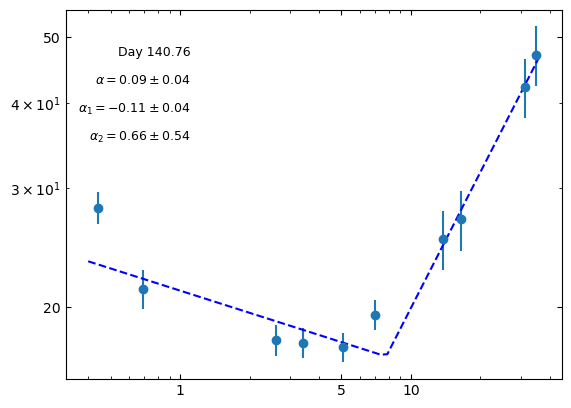

In [163]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(.4,36,0.5)
mask = df16['Flux Density (mJy)'] > 3 * df16['Uncertainty (mJy)']  # apply detection threshold
mask2 = df16['Flux Density (mJy)'] < 3 * df16['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df16['Freq (GHz)'][mask], df16['Flux Density (mJy)'][mask], yerr=yerr16, fmt='o')
    ax.scatter(df16['Freq (GHz)'][mask2], (df16['Flux Density (mJy)'][mask2] + 3*df16['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 140.76', xy=(90, 240), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
#    ax.plot(df16['Freq (GHz)'][mask], fit_model_weights16(df16['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.09 \\pm 0.04}$', xy=(90, 220), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq , fw_BPL16(x_freq ), 'b--')
    ax.annotate('${\u03B1_1 = -0.11 \\pm 0.04}$', xy=(90, 200), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.66 \\pm 0.54}$', xy=(90, 180), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 154.66 (df17)

In [164]:
#(work for anything with 3+ points)
x17 = df17['Freq (GHz)'].values.tolist()
y17 = df17['Flux Density (mJy)'].values.tolist()
yerr17 = df17['Uncertainty (mJy)'].values.tolist()


In [165]:
yerr17 = error(yerr17, x17, y17)

In [166]:
PL17 =  PowerLaw1D(amplitude = y17[0], x_0= x17[0], alpha= -4.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit17 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model17 = fit17(PL17, x17, y17)


#weight is 1/error^2
y_weight17 = 1/ (np.power(yerr17, 2))  

# fit the data using the uncertainties as weights
fit_model_weights17 = fit17(PL17, x17, y17, weights=y_weight17)

fit_model_weights17


<PowerLaw1D(amplitude=19.93400488, x_0=2.63175669, alpha=0.01446219)>

In [167]:
fit17.fit_info

{'nfev': 34,
 'fvec': array([ 3.19140521, -2.27146503, -3.02646522, -2.17246431,  1.37716714,
         1.19062011, -0.45755739, -0.55994179, -1.03234159, -1.0941114 ]),
 'fjac': array([[-4.49030077e+01,  3.19425515e-01,  3.49906771e-02,
         -8.66035086e-02, -3.36607719e-01, -4.92577260e-01,
         -1.53187884e-01, -1.61453910e-01, -1.50560226e-01,
         -1.46199559e-01],
        [ 3.19425515e-01, -2.19069883e+00, -2.39974678e-01,
          3.61638281e-01,  5.77399746e-01,  5.97121578e-01,
          1.20163013e-01,  1.16452737e-01,  8.69497479e-02,
          8.17165969e-02],
        [ 3.49906771e-02, -2.39974678e-01,  3.52110409e-17,
         -3.94131711e-01, -7.88263423e-01, -0.00000000e+00,
          9.85329278e-02,  1.97065856e-01,  9.85329278e-02,
          9.85329278e-02]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-1.02579648e-05,  7.01930924e-05,  3.46107843e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at m

In [168]:
#taking fvec
fvec17 = np.array([ 3.19141582, -2.27145661, -3.0264571 , -2.17245479,  1.37718146,
         1.19063429, -0.45755477, -0.55993931, -1.03233988, -1.09410981])
var17 = np.var(fvec17)

#taking cov_x
cov_x17 = np.array([[ 5.32073424e+30, -3.44247755e+31, -1.13538277e+13],
        [-3.44247755e+31,  2.22725871e+32,  7.34584650e+13],
        [-1.13538277e+13,  7.34584650e+13,  5.30734378e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag17 = stand(cov_x17*var17) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag17[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.04182870086953788


In [169]:
Xhi = cs(df17['Flux Density (mJy)'], fit_model_weights17( df17["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(10-4))

The chi squared for lin fit is 1.6407656319656903


In [170]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM17 = bpl_func(x_val, y17, yerr17, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM17[50]

#Apply error as weighting in the function 

weight17 = 1/ (np.power(yerr17,2))
fw_BPL17 = fitBPL(BM17[50], x17, y17, weights=weight17)   
print(fw_BPL17)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 3.37378064, -2.05920269, -3.07731872, -2.27665304,  1.11921252,
        0.85743816, -0.04706012,  0.05834809,  0.00435525, -0.01864717]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(  [[ 6.11385910e-01, -3.38125782e+00, -1.12008358e-02,
         1.29514747e-01],
       [-3.38125782e+00,  7.77507329e+01, -2.02968069e-02,
        -2.41993406e+00],
       [-1.12008358e-02, -2.02968069e-02,  5.47859835e-04,
        -2.16840434e-19],
       [ 1.29514747e-01, -2.41993406e+00, -2.16840434e-19,
         9.46553716e-02]] )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df17['Flux Density (mJy)'], fw_BPL17( df17["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(10-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1              alpha_2       
    ------------------ ----------------- -------------------- --------------------
    19.232308211388283 9.155687635937346 0.025485132588263522 -0.26271366145076325

{'nfev': 11, 'fvec': array([ 3.37378064, -2.05920269, -3.07731872, -2.27665304,  1.11921252,
        0.85743816, -0.04706012,  0.05834809,  0.00435525, -0.01864717]), 'fjac': array([[-6.62102824e+01,  6.26523904e-01,  2.45623066e-01,
         2.25603470e-01,  1.99624973e-01,  9.03273938e-02,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00],
       [ 0.00000000e+00, -7.43960487e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -2.48108577e-01, -3.61611690e-01, -6.20372283e-01,
        -6.50244070e-01],
       [-1.72298800e+00,  3.88940749e-01, -1.46751252e+00,
         2.93516183e-01, 

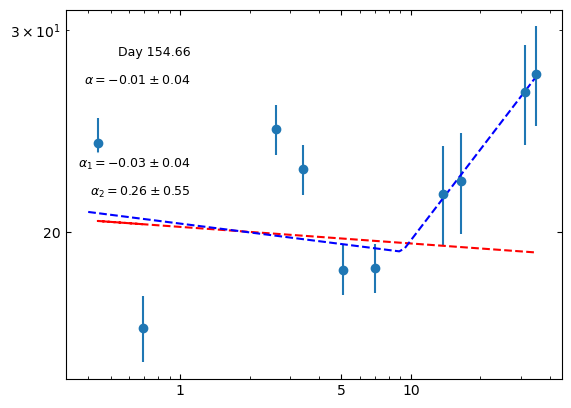

In [171]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(.4,36,0.5)

mask = df17['Flux Density (mJy)'] > 3 * df17['Uncertainty (mJy)']  # apply detection threshold
mask2 = df17['Flux Density (mJy)'] < 3 * df17['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df17['Freq (GHz)'][mask], df17['Flux Density (mJy)'][mask], yerr=yerr17, fmt='o')
    ax.scatter(df17['Freq (GHz)'][mask2], (df17['Flux Density (mJy)'][mask2] + 3*df17['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 154.66', xy=(90, 240), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df17['Freq (GHz)'][mask], fit_model_weights17(df17['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.01 \\pm 0.04}$', xy=(90, 220), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL17(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.03 \\pm 0.04}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.26 \\pm 0.55}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 156.61 (df18)

In [172]:
#(work for anything with 3+ points)
x18 = df18['Freq (GHz)'].values.tolist()
y18 = df18['Flux Density (mJy)'].values.tolist()
yerr18 = df18['Uncertainty (mJy)'].values.tolist()


In [173]:
yerr18 = error(yerr18, x18, y18)

In [179]:
PL18 =  PowerLaw1D(amplitude = y18[0], x_0= x18[0], alpha= -1.1) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit18 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model18 = fit18(PL18, x18, y18)


#weight is 1/error^2
y_weight18 = 1/ (np.power(yerr18, 2))  

# fit the data using the uncertainties as weights
fit_model_weights18 = fit18(PL18, x18, y18, weights=y_weight18)

fit_model_weights18


NonFiniteValueError: Objective function has encountered a non-finite value, this will cause the fit to fail!
Please remove non-finite values from your input data before fitting to avoid this error.

In [173]:
fit18.fit_info

{'nfev': None,
 'fvec': None,
 'fjac': None,
 'ipvt': None,
 'qtf': None,
 'message': None,
 'ierr': None,
 'param_jac': None,
 'param_cov': None}

In [180]:
#taking fvec
fvec18 = np.array([-0.98900635, -0.47803039,  0.9640636 ,  0.69554909, -0.8201535 ,
        -1.04042797, -1.54002027, -1.58621751])
var18 = np.var(fvec18)

#taking cov_x
cov_x18 = np.array([[ 4.29987039e+30, -1.68110134e+31, -6.30537700e+13],
        [-1.68110134e+31,  6.57252767e+31,  2.46518540e+14],
        [-6.30537700e+13,  2.46518540e+14,  5.02309598e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag18 = stand(cov_x18*var18) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag18[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.06334016920541749


In [181]:
Xhi = cs(df18['Flux Density (mJy)'], fit_model_weights18( df18["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

NameError: name 'fit_model_weights18' is not defined

In [182]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM18 = bpl_func(x_val, y18, yerr18, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM18[43]

#Apply error as weighting in the function 

weight18 = 1/ (np.power(yerr18,2))
fw_BPL18 = fitBPL(BM18[43], x18, y18, weights=weight18)   
print(fw_BPL18)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array(  [-0.19132001, -0.06463445,  0.57898397, -0.38442638, -0.02448385,
        0.02980024,  0.01513837, -0.02186263] )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(  [[ 6.89886287e+00, -1.12385866e+01, -3.07344269e-02,
         7.70093966e-01],
       [-1.12385866e+01,  2.06088069e+01, -4.10284361e-02,
        -1.34116342e+00],
       [-3.07344269e-02, -4.10284361e-02,  5.36474194e-03,
         2.64545330e-17],
       [ 7.70093966e-01, -1.34116342e+00,  2.64545330e-17,
         1.04802042e-01]] )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df18['Flux Density (mJy)'], fw_BPL18( df18["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude         x_break            alpha_1             alpha_2       
    ----------------- ---------------- ------------------- --------------------
    18.23633011214951 7.93231720659453 0.24976112829999045 -0.32583880551333655

{'nfev': 7, 'fvec': array([-0.19132001, -0.06463445,  0.57898397, -0.38442638, -0.02448385,
        0.02980024,  0.01513837, -0.02186263]), 'fjac': array([[-2.48398685e+01,  5.95320913e-01,  3.68233871e-01,
         1.02793926e-01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -8.01248809e+00,  0.00000000e+00,
         0.00000000e+00, -3.09462741e-01, -4.00092975e-01,
        -6.03336956e-01, -6.16557330e-01],
       [-1.71296130e+00,  4.02826191e-01, -1.13950799e+00,
         8.46566232e-01,  1.24889055e-01,  8.97848646e-02,
        -1.19604697e-02, -2.57616017e-02],
       [-9.83579736e-01, -3.01757348e-01, -

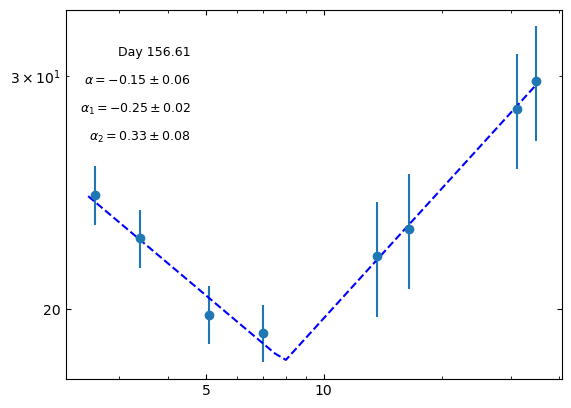

In [183]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(2.5,36,0.5)
mask = df18['Flux Density (mJy)'] > 3 * df18['Uncertainty (mJy)']  # apply detection threshold
mask2 = df18['Flux Density (mJy)'] < 3 * df18['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df18['Freq (GHz)'][mask], df18['Flux Density (mJy)'][mask], yerr=yerr18, fmt='o')
    ax.scatter(df18['Freq (GHz)'][mask2], (df18['Flux Density (mJy)'][mask2] + 3*df18['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 156.61', xy=(90, 240), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
 #   ax.plot(df18['Freq (GHz)'][mask], fit_model_weights18(df18['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.15 \\pm 0.06}$', xy=(90, 220), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL18(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = -0.25 \\pm 0.02}$', xy=(90, 200), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.33 \\pm 0.08}$', xy=(90, 180), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 161.61 (df19)

In [184]:
#(work for anything with 3+ points)
x19 = df19['Freq (GHz)'].values.tolist()
y19 = df19['Flux Density (mJy)'].values.tolist()
yerr19 = df19['Uncertainty (mJy)'].values.tolist()


In [185]:
yerr19 = error(yerr19, x19, y19)

In [186]:
PL19 =  PowerLaw1D(amplitude = y19[0], x_0= x19[0], alpha= 6.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit19 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model19 = fit19(PL19, x19, y19)


#weight is 1/error^2
y_weight19 = 1/ (np.power(yerr19, 2))  

# fit the data using the uncertainties as weights
fit_model_weights19 = fit19(PL19, x19, y19, weights=y_weight19)

fit_model_weights19


<PowerLaw1D(amplitude=22.8512815, x_0=1.5472921, alpha=0.15897159)>

In [187]:
fit19.fit_info

{'nfev': 20,
 'fvec': array([-1.55198586, -0.5299047 ,  1.84500495,  0.13136382, -1.06005036,
        -1.2910116 , -1.75615965, -1.79211717]),
 'fjac': array([[ 4.97332736e+01, -4.02887152e+00, -1.71603306e+00,
          6.80546183e-01,  1.65215059e-01,  1.56212282e-01,
          1.16185269e-01,  1.08339404e-01],
        [-4.02887152e+00, -1.38119845e+00, -5.88299277e-01,
         -7.13786692e-01, -2.97961553e-01, -3.02545138e-01,
         -2.63382663e-01, -2.50538203e-01],
        [-1.71603306e+00, -5.88299277e-01, -4.23670474e-16,
          3.93073069e-01,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00, -6.55121782e-02]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([ 1.57202231e-04, -9.28846711e-05, -2.88439222e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 5.57113397e+30, -2.37293496e+30,  5.67206055e+13],
        [-2.37293496e+30,  1.01071

In [188]:
#taking fvec
fvec19 = np.array([-1.55203821, -0.52991918,  1.84508297,  0.1315041 , -1.06000212,
        -1.29096362, -1.7561196 , -1.79207927])
var19 = np.var(fvec19)

#taking cov_x
cov_x19 = np.array([[ 3.70878347e+30, -2.24694106e+30,  2.47296783e+13],
        [-2.24694106e+30,  1.36129384e+30, -1.49823062e+13],
        [ 2.47296783e+13, -1.49823062e+13,  4.00923329e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag19 = stand(cov_x19*var19) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag19[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.07319435945585713


In [189]:
Xhi = cs(df19['Flux Density (mJy)'], fit_model_weights19( df19["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 7.69875784169835


In [190]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM19 = bpl_func(x_val, y19, yerr19, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM19[50]

#Apply error as weighting in the function 

weight19 = 1/ (np.power(yerr19,2))
fw_BPL19 = fitBPL(BM19[50], x19, y19, weights=weight19)   
print(fw_BPL19)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array(  [-0.63774532, -0.02109751,  1.38389979, -1.06661683, -0.01737899,
        0.02170455,  0.00812743, -0.01314857] )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 6.24004428e+00, -9.65915058e+00, -2.17350391e-02,
         7.07626218e-01],
       [-9.65915058e+00,  1.61952549e+01, -2.85061826e-02,
        -1.14467327e+00],
       [-2.17350391e-02, -2.85061826e-02,  4.87821147e-03,
         4.16333634e-17],
       [ 7.07626218e-01, -1.14467327e+00,  4.16333634e-17,
         9.46793571e-02]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df19['Flux Density (mJy)'], fw_BPL19( df19["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
       amplitude          x_break           alpha_1             alpha_2      
    ---------------- ----------------- ------------------ -------------------
    16.7637311274194 7.394017048572963 0.2726635128538343 -0.3363027979077046

{'nfev': 7, 'fvec': array([-0.63774532, -0.02109751,  1.38389979, -1.06661683, -0.01737899,
        0.02170455,  0.00812743, -0.01314857]), 'fjac': array([[-2.42794704e+01,  6.06845792e-01,  3.69651016e-01,
         4.78705048e-02,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -8.95211250e+00,  0.00000000e+00,
         0.00000000e+00, -3.31387065e-01, -4.12020721e-01,
        -5.92120035e-01, -6.08124495e-01],
       [-1.96287210e+00,  4.65624933e-01, -1.44465896e+00,
         8.19276354e-01,  1.11224253e-01,  8.10741550e-02,
        -3.80193121e-03, -1.55291979e-02],
       [-1.21342901e+00, -3.55023900e-01, -8.6162

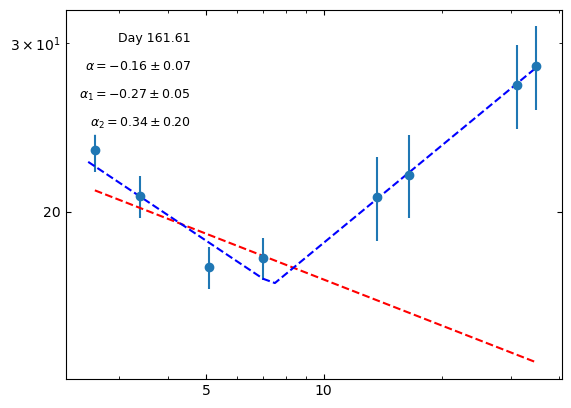

In [191]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(2.5,36,0.5)
mask = df19['Flux Density (mJy)'] > 3 * df19['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19['Flux Density (mJy)'] < 3 * df19['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df19['Freq (GHz)'][mask], df19['Flux Density (mJy)'][mask], yerr=yerr19, fmt='o')
    ax.scatter(df19['Freq (GHz)'][mask2], (df19['Flux Density (mJy)'][mask2] + 3*df19['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 161.61', xy=(90, 250), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df19['Freq (GHz)'][mask], fit_model_weights19(df19['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.16 \\pm 0.07}$', xy=(90, 230), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL19( x_freq ), 'b--')
    ax.annotate('${\u03B1_1 = -0.27 \\pm 0.05}$', xy=(90, 210), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.34 \\pm 0.20}$', xy=(90, 190), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


# "Day 181-183" (df 19_1)

In [192]:
#(work for anything with 3+ points)
x19_1 = df19_1['Freq (GHz)'].values.tolist()
y19_1 = df19_1['Flux Density (mJy)'].values.tolist()
yerr19_1 = df19_1['Uncertainty (mJy)'].values.tolist()
#new (correct error)
yerr19_1 = error(yerr19_1, x19_1, y19_1)

PL19_1 =  PowerLaw1D(amplitude = y19_1[0], x_0= x19_1[0], alpha= 0.321) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit19_1 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model19_1 = fit19_1(PL19_1, x19_1, y19_1)


#weight is 1/error^2
y_weight19_1 = 1/ (np.power(yerr19_1, 2))  

# fit the data using the uncertainties as weights
fit_model_weights19_1 = fit19_1(PL19_1, x19_1, y19_1, weights=y_weight19_1)

print("alpha")
print(fit_model_weights19_1)
print("")

print(fit19_1.fit_info)


alpha
Model: PowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude             x_0              alpha      
    ------------------ ----------------- -----------------
    13.011194423904175 1.395627887963692 0.320857676606207

{'nfev': 8, 'fvec': array([ 0.0456877 , -0.20260309,  0.14923468]), 'fjac': array([[-2.17176834e+01, -5.67464319e+00, -1.89704921e+00],
       [-5.67464319e+00,  6.94010689e+00,  2.32009730e+00],
       [-1.89704921e+00,  2.32009730e+00,  4.44089210e-16]]), 'ipvt': array([2, 1, 0], dtype=int32), 'qtf': array([ 3.99778055e-07, -5.61358253e-07, -2.55746685e-01]), 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000', 'ierr': 1, 'param_jac': None, 'param_cov': None, 'njev': 3, 'cov_x': array([[ 5.07060240e+30, -1.69511667e+30, -1.26103392e+14],
       [-1.69511667e+30,  5.66682282e+29,  4.21567195e+13],
       [-1.26103392e+14,  4.21567195e+13,  6.67379359e-03]])}


In [193]:
#taking fvec
fvec19_1 = np.array([ 0.04568825, -0.20260279,  0.14923492])
var19_1 = np.var(fvec19_1)

#taking cov_x
cov_x19_1 = np.array([[ 2.02824096e+31, -3.54216333e+30,  2.20841059e+14],
       [-3.54216333e+30,  6.18610970e+29, -3.85681542e+13],
       [ 2.20841059e+14, -3.85681542e+13,  5.94224879e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag19_1 = stand(cov_x19_1*var19_1) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag19_1[2]) #Just showing the standard deviation on the slope

#no xhi, three points
#Xhi = cs(df19_1['Flux Density (mJy)'], fit_model_weights19_1( df19_1["Freq (GHz)"] ))
#print("The chi squared for lin fit is", Xhi/(8-4))

The error/standard deviation is 0.011380452445704075


In [194]:
#No broken fit - three points

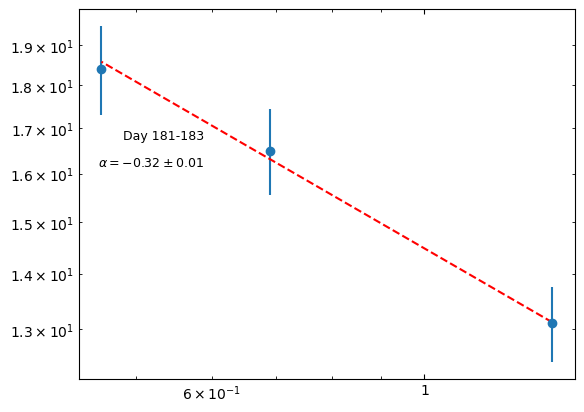

In [195]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(2.5,36,0.5)
mask = df19_1['Flux Density (mJy)'] > 3 * df19_1['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19_1['Flux Density (mJy)'] < 3 * df19_1['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df19_1['Freq (GHz)'][mask], df19_1['Flux Density (mJy)'][mask], yerr=yerr19_1, fmt='o')
    ax.scatter(df19_1['Freq (GHz)'][mask2], (df19_1['Flux Density (mJy)'][mask2] + 3*df19_1['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 181-183', xy=(90, 180), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df19_1['Freq (GHz)'][mask], fit_model_weights19_1(df19_1['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.32 \\pm 0.01}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    #ax.plot(x_freq, fw_BPL19_1( x_freq ), 'b--')
    #ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 210), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    #ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 190), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

# "Day 223" (df19_2)

In [196]:
#(work for anything with 3+ points)
x19_2 = df19_2['Freq (GHz)'].values.tolist()
y19_2 = df19_2['Flux Density (mJy)'].values.tolist()
yerr19_2 = df19_2['Uncertainty (mJy)'].values.tolist()
#new (correct error)
yerr19_2 = error(yerr19_2, x19_2, y19_2)

PL19_2 =  PowerLaw1D(amplitude = y19_2[0], x_0= x19_2[0], alpha= -1.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit19_2 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model19_2 = fit19_2(PL19_2, x19_2, y19_2)


#weight is 1/error^2
y_weight19_2 = 1/ (np.power(yerr19_2, 2))  

# fit the data using the uncertainties as weights
fit_model_weights19_2 = fit19_2(PL19_2, x19_2, y19_2, weights=y_weight19_2)

print("alpha")
print(fit_model_weights19_2)
print("")

print(fit19_2.fit_info)

alpha
Model: PowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
       amplitude            x_0               alpha       
    ---------------- ----------------- -------------------
    8.88214718662495 43.83829566525775 0.07330997027164103

{'nfev': 47, 'fvec': array([ 0.0716322 ,  0.01332648, -0.01382773]), 'fjac': array([[-1.54897048e+02, -4.56706169e+00, -6.78366238e-02],
       [-4.56706169e+00, -2.75671246e-01, -4.09466916e-03],
       [-6.78366238e-02, -4.09466916e-03,  8.67361738e-18]]), 'ipvt': array([2, 0, 1], dtype=int32), 'qtf': array([4.81502771e-07, 2.87175659e-08, 7.41618047e-02]), 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000', 'ierr': 1, 'param_jac': None, 'param_cov': None, 'njev': 31, 'cov_x': array([[ 2.93260908e+30, -1.97436220e+32,  9.61911986e+13],
       [-1.97436220e+32,  1.32922800e+34, -6.47601713e+15],
       [ 9.61911986e+13, -6.47601713e+15,  1.46362370e-02]])}


In [197]:
#taking fvec
fvec19_2 = np.array([ 0.0716322 ,  0.01332647, -0.01382773])
var19_2 = np.var(fvec19_2)

#taking cov_x
cov_x19_2 = np.array([[ 2.09679133e+31, -1.40781659e+33,  6.55109198e+14],
       [-1.40781659e+33,  9.45228797e+34, -4.39849967e+16],
       [ 6.55109198e+14, -4.39849967e+16,  3.19489605e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag19_2 = stand(cov_x19_2*var19_2) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag19_2[2]) #Just showing the standard deviation on the slope

#no xhi fit, three points
#Xhi = cs(df19_2['Flux Density (mJy)'], fit_model_weights19_2( df19_2["Freq (GHz)"] ))
#print("The chi squared for lin fit is", Xhi/(8-4))

The error/standard deviation is 0.006372736722700861


In [198]:
#no broken fit, three points

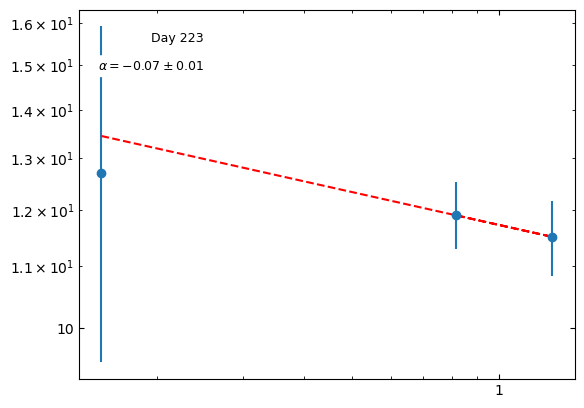

In [199]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(2.5,36,0.5)
mask = df19_2['Flux Density (mJy)'] > 3 * df19_2['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19_2['Flux Density (mJy)'] < 3 * df19_2['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df19_2['Freq (GHz)'][mask], df19_2['Flux Density (mJy)'][mask], yerr=yerr19_2, fmt='o')
    ax.scatter(df19_2['Freq (GHz)'][mask2], (df19_2['Flux Density (mJy)'][mask2] + 3*df19_2['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 223', xy=(90, 250), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df19_2['Freq (GHz)'][mask], fit_model_weights19_2(df19_2['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.07 \\pm 0.01}$', xy=(90, 230), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    #ax.plot(x_freq, fw_BPL19_2( x_freq ), 'b--')
    #ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 210), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    #ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 190), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

# "Day 260-287" (df19_3)

In [200]:
#have to manually break this

In [201]:
#(work for anything with 3+ points)
x19_3 = df19_3['Freq (GHz)'].values.tolist()
y19_3 = df19_3['Flux Density (mJy)'].values.tolist()
yerr19_3 = df19_3['Uncertainty (mJy)'].values.tolist()
#new (correct error)
yerr19_3 = error(yerr19_3, x19_3, y19_3)


#split so that I am fitting the first two points and the last three 
xA = [0.44, 0.147]
xB = [1.36, 0.62, 0.44]

yA = [8.93, 26.8]
yB = [9.9, 10.14, 8.93]

erA = [0.943564120767635, 3.41250641025039]
erB = [0.4950000000000003, 0.518895943325827, 0.943564120767635]


PLA =  PowerLaw1D(amplitude = yA[0], x_0= xA[0], alpha= 1,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

fitA = fitting.LevMarLSQFitter(calc_uncertainties=True)

fit_modelA = fitA(PLA, xA, yA)
y_weightA = 1/ (np.power(erA,2))  

fit_model_weightsA = fitA(PLA, xA, yA, weights=y_weightA)

fit_model_weightsA

<PowerLaw1D(amplitude=8.93, x_0=0.44, alpha=1.00241107)>

In [202]:
alpha_er = two_points(yA,xA,erA)
print(alpha_er)

(-1.0024110653034926, 0.1509228705504639)


In [203]:
PLB =  PowerLaw1D(amplitude = yB[0], x_0= xB[0], alpha= 0.01) 
fitB = fitting.LevMarLSQFitter(calc_uncertainties=True)

fit_modelB = fitB(PLB, xB, yB)
y_weightB = 1/ (np.power(erB, 2))  

fit_model_weightsB = fitB(PLB, xB, yB, weights=y_weightB)


print(fit_model_weightsB)

Model: PowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude     x_0         alpha        
    ----------------- ---- --------------------
    9.936430915280976 1.36 0.007622996402078648


In [204]:
fitB.fit_info

{'nfev': 4,
 'fvec': array([ 0.14868244, -0.53440831,  1.22684419]),
 'fjac': array([[-31.80934529,   0.9167972 ,   0.3993531 ],
        [ -3.87784542,   4.10633001,   0.49815081],
        [ -0.21598571,   0.22871169,  -0.        ]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-5.12161077e-06, -4.83361538e-06,  1.34641947e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': None,
 'njev': 3,
 'cov_x': None}

In [205]:
#taking fvec
fvec19_3 = np.array([ 0.14868235, -0.53440833,  1.2268442 ])
var19_3 = np.var(fvec19_3)

#taking cov_x
cov_x19_3 = np.array([[ 1.48218704e+31, -1.38707923e+32, -5.29100000e+14],
        [-1.38707923e+32,  1.29807421e+33,  4.95149126e+15],
        [-5.29100000e+14,  4.95149126e+15,  2.07570998e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag19_3 = stand(cov_x19_3*var19_3) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag19_3[2]) #Just showing the standard deviation on the slope

#no xhi fit - four points
#Xhi = cs(df19_3['Flux Density (mJy)'], fit_model_weights19_3( df19_3["Freq (GHz)"] ))
#print("The chi squared for lin fit is", Xhi/(8-4))

The error/standard deviation is 0.10445786408619329


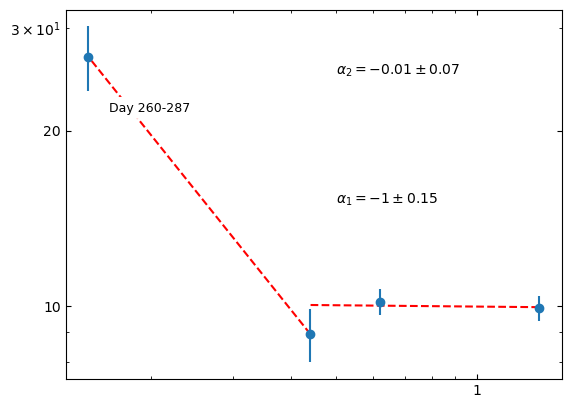

In [206]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(0.15,2,0.5)
mask = df19_3['Flux Density (mJy)'] > 3 * df19_3['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19_3['Flux Density (mJy)'] < 3 * df19_3['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df19_3['Freq (GHz)'][mask], df19_3['Flux Density (mJy)'][mask], yerr=yerr19_3, fmt='o')
    ax.scatter(df19_3['Freq (GHz)'][mask2], (df19_3['Flux Density (mJy)'][mask2] + 3*df19_3['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 260-287', xy=(90, 200), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

    ax.plot(xB, fit_model_weightsB(xB), 'r--')
    ax.plot(xA, fit_model_weightsA(xA), 'r--')
    ax.annotate(r'$\alpha_2 = -0.01 \pm 0.07$', xy=(0.5, 25))
    ax.annotate(r'$\alpha_1 = -1 \pm 0.15$', xy=(0.5, 15))
    
    
plt.show();

## Day 600.47 (df20)

In [207]:
#(work for anything with 3+ points)
x20 = df20['Freq (GHz)'].values.tolist()
y20 = df20['Flux Density (mJy)'].values.tolist()
yerr20 = df20['Uncertainty (mJy)'].values.tolist()


In [208]:
yerr20 = error(yerr20, x20, y20)

In [209]:
PL20 =  PowerLaw1D(amplitude = y20[0], x_0= x20[0], alpha= -4.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit20 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model20 = fit20(PL20, x20, y20)


#weight is 1/error^2
y_weight20 = 1/ (np.power(yerr20, 2))  

# fit the data using the uncertainties as weights
fit_model_weights20 = fit20(PL20, x20, y20, weights=y_weight20)

fit_model_weights20


<PowerLaw1D(amplitude=0.14591861, x_0=1057.41495168, alpha=0.54693872)>

In [210]:
fit20.fit_info

{'nfev': 68,
 'fvec': array([10.82069128,  0.63799781, -3.02879959, -4.77911028, -3.28123375,
        -4.09331544,  7.62778748,  4.13013839]),
 'fjac': array([[-1.64235742e+03, -1.24016184e-01, -1.20779914e+03,
          5.85533062e-01,  2.15350627e-01,  2.28849412e-01,
          2.38417684e-01,  2.01368288e-01],
        [-1.24016184e-01, -3.12250226e-17, -7.94181402e-08,
          4.44444444e-01,  4.44444444e-01,  2.22222222e-01,
          2.22222222e-01,  3.33333333e-01],
        [-1.20779914e+03,  7.96006302e+01, -1.41135854e+02,
         -1.48487231e-01, -2.43421535e-01, -3.81486612e-01,
         -6.55963809e-01, -5.64024803e-01]]),
 'ipvt': array([0, 1, 2], dtype=int32),
 'qtf': array([2.89537260e-06, 1.00620276e+01, 5.67537560e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 7.70837653e+24, -1.02082720e+29, -9.66383984e+09],
        [-1.02082720e+29,  1.35189058

In [211]:
#taking fvec
fvec20 = np.array([10.82069124,  0.63799777, -3.02879966, -4.77911036, -3.28123377,
        -4.09331547,  7.62778745,  4.13013837])
var20 = np.var(fvec20)

#taking cov_x
cov_x20 = np.array([[ 1.12479397e+25, -1.48904898e+29, -9.48811879e+09],
        [-1.48904898e+29,  1.97126489e+33,  1.25607658e+14],
        [-9.48811879e+09,  1.25607658e+14,  4.60907636e-05]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag20 = stand(cov_x20*var20) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag20[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.03750912229049003


In [212]:
Xhi = cs(df20['Flux Density (mJy)'], fit_model_weights20( df20["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 0.03444379016562732


In [213]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM20 = bpl_func(x_val, y20, yerr20, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM20[50]

#Apply error as weighting in the function 

weight20 = 1/ (np.power(yerr20,2))
fw_BPL20 = fitBPL(BM20[50], x20, y20, weights=weight20)   
print(fw_BPL20)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df20['Flux Density (mJy)'], fw_BPL20( df20["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break           alpha_1            alpha_2      
    ------------------ ----------------- ------------------ ------------------
    2.6806746772773202 5.745822305841571 0.3213325428682512 0.6209077321833966

{'nfev': 9, 'fvec': array([ 2.91976461, -3.99365036,  0.9338095 ,  1.5084529 , -3.58200206,
       -5.15794733,  3.95195361,  0.64205849]), 'fjac': array([[-1.43960865e+02,  0.00000000e+00,  0.00000000e+00,
        -2.01092499e-01, -3.09736155e-01, -3.94136976e-01,
        -6.27234423e-01, -5.61122397e-01],
       [ 4.67224907e+01, -7.63918679e+01,  6.23444815e-01,
         6.53675105e-01,  1.54501237e-01,  1.40385909e-01,
         6.65157412e-02,  4.45779256e-02],
       [ 0.00000000e+00, -3.86417952e+01,  5.17785314e+01,
         5.30567623e-01, -1.22418185e-01, -2.17749971e-01,
        -5.19496330e-01, -4.81195956e-01],
       [ 1.35343674e+01, -1.55783916e+01, -3.0

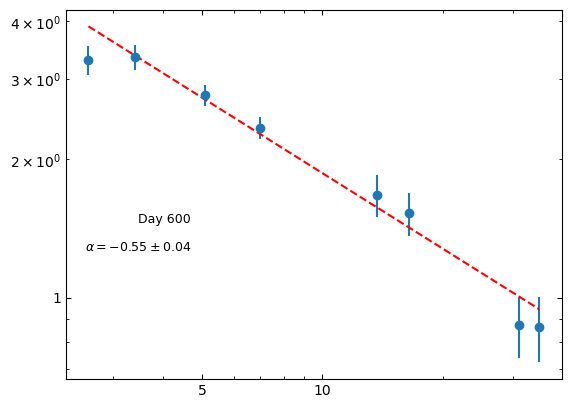

In [214]:
#plotting to check
fig,ax = plt.subplots()
mask = df20['Flux Density (mJy)'] > 3 * df20['Uncertainty (mJy)']  # apply detection threshold
mask2 = df20['Flux Density (mJy)'] < 3 * df20['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df20['Freq (GHz)'][mask], df20['Flux Density (mJy)'][mask], yerr=yerr20, fmt='o')
    ax.scatter(df20['Freq (GHz)'][mask2], (df20['Flux Density (mJy)'][mask2] + 3*df20['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 600', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df20['Freq (GHz)'][mask], fit_model_weights20(df20['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.55 \\pm 0.04}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


 ## Day 615.34 (df21)

In [215]:
#(work for anything with 3+ points)
x21 = df21['Freq (GHz)'].values.tolist()
y21 = df21['Flux Density (mJy)'].values.tolist()
yerr21 = df21['Uncertainty (mJy)'].values.tolist()


In [216]:
yerr21 = error(yerr21, x21, y21)

In [217]:
PL21 =  PowerLaw1D(amplitude = y21[0], x_0= x21[0], alpha= -2) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit21 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model21 = fit21(PL21, x21, y21)


#weight is 1/error^2
y_weight21 = 1/ (np.power(yerr21, 2))  

# fit the data using the uncertainties as weights
fit_model_weights21 = fit21(PL21, x21, y21, weights=y_weight21)

fit_model_weights21


<PowerLaw1D(amplitude=0.32266516, x_0=961.37883231, alpha=0.39305323)>

In [218]:
fit21.fit_info

{'nfev': 29,
 'fvec': array([10.78715731,  5.65393047, -7.4097688 , -8.60361831,  1.50775615,
         2.05760947,  7.00237483,  2.79565302]),
 'fjac': array([[-1.27287854e+03, -7.72565857e+02, -1.01916475e-01,
          5.33415470e-01,  1.89754377e-01,  1.95481488e-01,
          1.41375085e-01,  1.15518806e-01],
        [-7.72565857e+02,  1.01883838e+02,  1.34404615e-02,
         -2.84084282e-01, -3.36828216e-01, -4.28448874e-01,
         -5.58622916e-01, -5.01775887e-01],
        [-1.01916475e-01,  1.34404615e-02,  1.24557089e-17,
         -5.57085428e-01,  5.57085428e-01, -0.00000000e+00,
          3.48178393e-01,  3.48178393e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 4.29982149e-04, -4.72788436e-04, -6.12095092e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.12171073e+26, -8.50299627e+29, -1.41607364e+10],
        [-8.50299627e+29,  6.44559

In [219]:
#taking fvec
fvec21 = np.array([10.7871569 ,  5.65392979, -7.40976953, -8.60361914,  1.5077558 ,
         2.0576091 ,  7.0023745 ,  2.79565275])
var21 = np.var(fvec21)

#taking cov_x
cov_x21 = np.array([[ 1.77565108e+26, -1.34114008e+30,  3.98027684e+10],
        [-1.34114008e+30,  1.01295617e+34, -3.00628253e+14],
        [ 3.98027684e+10, -3.00628253e+14,  4.50277452e-05]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag21 = stand(cov_x21*var21) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag21[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.0422293097752915


In [220]:
Xhi = cs(df21['Flux Density (mJy)'], fit_model_weights21( df21["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 0.034295338038600624


In [221]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM21 = bpl_func(x_val, y21, yerr21, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM21[50]

#Apply error as weighting in the function 

weight21 = 1/ (np.power(yerr21,2))
fw_BPL21 = fitBPL(BM21[50], x21, y21, weights=weight21)   
print(fw_BPL21)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df21['Flux Density (mJy)'], fw_BPL21( df21["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break             alpha_1             alpha_2      
    ------------------ ----------------- --------------------- ------------------
    2.8687622769455006 4.586342515875671 -0.057278193843349354 0.4858323971539056

{'nfev': 9, 'fvec': array([ 9.21742330e-15,  3.42067560e-14,  1.94810899e+00, -2.28230922e+00,
        5.22616434e-01, -3.25949977e-02,  2.31839376e+00, -1.59435535e+00]), 'fjac': array([[-1.68251769e+02,  0.00000000e+00, -8.25725267e-02,
        -3.62522069e-01, -3.63141937e-01, -4.49869502e-01,
        -5.43375953e-01, -4.81920600e-01],
       [ 5.40938188e+01, -6.92472758e+01,  6.18243971e-01,
         5.48156112e-01,  1.02748148e-01,  7.67123192e-02,
        -2.63774132e-02, -3.55070834e-02],
       [ 0.00000000e+00, -2.72641294e+01,  3.71966940e+01,
         2.50648327e-01, -2.12634231e-01, -3.15959126e-01,
        -5.05297819e-01, -4.60733279e-01],
     

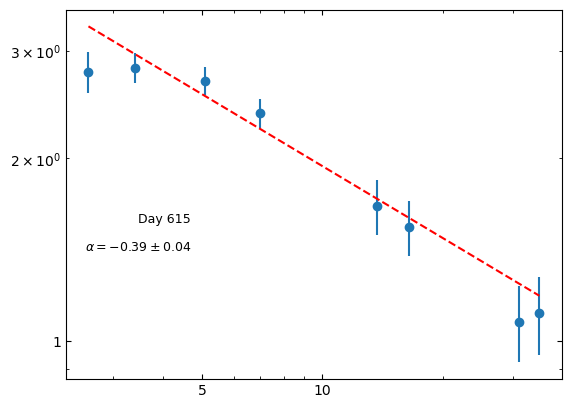

In [222]:
#plotting to check
fig,ax = plt.subplots()
mask = df21['Flux Density (mJy)'] > 3 * df21['Uncertainty (mJy)']  # apply detection threshold
mask2 = df21['Flux Density (mJy)'] < 3 * df21['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df21['Freq (GHz)'][mask], df21['Flux Density (mJy)'][mask], yerr=yerr21, fmt='o')
    ax.scatter(df21['Freq (GHz)'][mask2], (df21['Flux Density (mJy)'][mask2] + 3*df21['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 615', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df21['Freq (GHz)'][mask], fit_model_weights21(df21['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.39 \\pm 0.04}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Day 697.12 (df22)

In [223]:
#(work for anything with 3+ points)
x22 = df22['Freq (GHz)'].values.tolist()
y22 = df22['Flux Density (mJy)'].values.tolist()
yerr22 = df22['Uncertainty (mJy)'].values.tolist()


In [224]:
yerr22 = error(yerr22, x22, y22)

In [225]:
PL22 =  PowerLaw1D(amplitude = y22[0], x_0= x22[0], alpha= -2.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit22 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model22 = fit22(PL22, x22, y22)


#weight is 1/error^2
y_weight22 = 1/ (np.power(yerr22, 2))  

# fit the data using the uncertainties as weights
fit_model_weights22 = fit22(PL22, x22, y22, weights=y_weight22)

fit_model_weights22


<PowerLaw1D(amplitude=1.42980546, x_0=984.88540869, alpha=0.05682634)>

In [226]:
fit22.fit_info

{'nfev': 25,
 'fvec': array([ 23.11066749,  -2.52977056, -19.63734851, -31.65514695,
         -2.91300731,  -3.18105417,  18.19462796,  18.14152463]),
 'fjac': array([[-2.13476285e+03, -2.72328087e+02, -2.26457442e-02,
          3.13753123e-01,  9.65033901e-02,  9.20630766e-02,
          1.26562228e-01,  1.15833236e-01],
        [-2.72328087e+02,  3.56209083e+01,  2.96209615e-03,
         -3.35000299e-01, -2.31844700e-01, -2.62356620e-01,
         -5.99502957e-01, -5.97372324e-01],
        [-2.26457442e-02,  2.96209615e-03, -1.80447204e-18,
          4.80673415e-01,  1.80252530e-01, -1.20168354e-01,
          0.00000000e+00, -6.00841768e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-2.51649991e-04, -4.53960741e-03,  4.20780524e+01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.12367478e+27, -2.55384095e+31, -1.67822885e+11],
        [-2.55384095e+31, 

In [227]:
#taking fvec
fvec22 = np.array([ 23.11062027,  -2.52977031, -19.63729938, -31.65507353,
         -2.91295693,  -3.18099722,  18.19475779,  18.14165396])
var22 = np.var(fvec22)

#taking cov_x
cov_x22 = np.array([[ 1.05325794e+28, -1.27636755e+32,  3.42133670e+11],
        [-1.27636755e+32,  1.54673803e+36, -4.14607188e+15],
        [ 3.42133670e+11, -4.14607188e+15,  2.41587733e-05]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag22 = stand(cov_x22*var22) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag22[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.0887269846274669


In [228]:
Xhi = cs(df22['Flux Density (mJy)'], fit_model_weights22( df22["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(8-4))

The chi squared for lin fit is 0.09071225941517452


In [229]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM22 = bpl_func(x_val, y22, yerr22, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM22[50]

#Apply error as weighting in the function 

weight22 = 1/ (np.power(yerr22,2))
fw_BPL22 = fitBPL(BM22[50], x22, y22, weights=weight22)   
print(fw_BPL22)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array(  [ 2.51871335, -4.07551763,  0.45712606,  0.92591928,  1.6708196 ,
       -2.47821003,  1.14780727, -0.67940489] )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 5.55041357e-04,  5.62472365e-03, -6.18029729e-05,
         4.58374043e-04],
       [ 5.62472365e-03,  9.28725129e-02,  4.61514934e-04,
         6.32819231e-03],
       [-6.18029729e-05,  4.61514934e-04,  4.89858349e-05,
         5.42101086e-20],
       [ 4.58374043e-04,  6.32819231e-03,  5.42101086e-20,
         5.30173972e-04]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df22['Flux Density (mJy)'], fw_BPL22( df22["Freq (GHz)"] ))
print("")
print("The chi squared for broken fit is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0. \\pm 0.}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0. \\pm 0.}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1             alpha_2      
    ------------------ ----------------- -------------------- ------------------
    2.4764701884600218 8.630966158843641 -0.25244486644472436 0.4667130333387423

{'nfev': 7, 'fvec': array([ 2.51871335, -4.07551763,  0.45712606,  0.92591928,  1.6708196 ,
       -2.47821003,  1.14780727, -0.67940489]), 'fjac': array([[-3.31201130e+02,  5.40534933e-01,  2.88194477e-01,
         1.06358260e-01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -1.17312187e+02,  0.00000000e+00,
         0.00000000e+00, -2.08175574e-01, -2.69846844e-01,
        -6.69974287e-01, -6.59530186e-01],
       [-1.38659539e+02,  4.11023766e+01, -6.82970204e+01,
         7.97057031e-01,  2.14979616e-01,  1.62415016e-01,
         4.86456932e-02,  1.84418994e-02],
       [ 1.00436160e+01,  5.50415357e+00

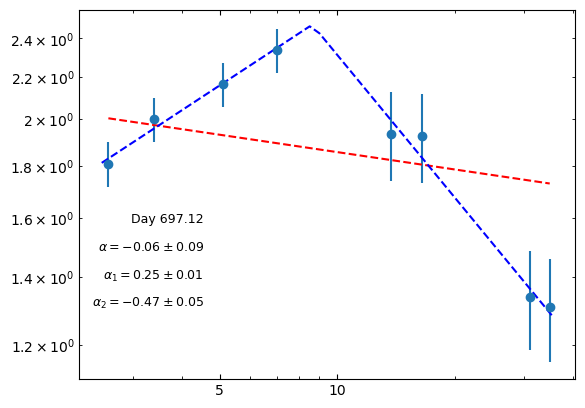

In [230]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(2.5,36,0.5)
mask = df22['Flux Density (mJy)'] > 3 * df22['Uncertainty (mJy)']  # apply detection threshold
mask2 = df22['Flux Density (mJy)'] < 3 * df22['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df22['Freq (GHz)'][mask], df22['Flux Density (mJy)'][mask], yerr=yerr22, fmt='o')
    ax.scatter(df22['Freq (GHz)'][mask2], (df22['Flux Density (mJy)'][mask2] + 3*df22['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 697.12', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df22['Freq (GHz)'][mask], fit_model_weights22(df22['Freq (GHz)'][mask]), 'r--')
    ax.annotate('${\u03B1 = -0.06 \\pm 0.09}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(x_freq, fw_BPL22(x_freq), 'b--')
    ax.annotate('${\u03B1_1 = 0.25 \\pm 0.01}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = -0.47 \\pm 0.05}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Now to put it all together

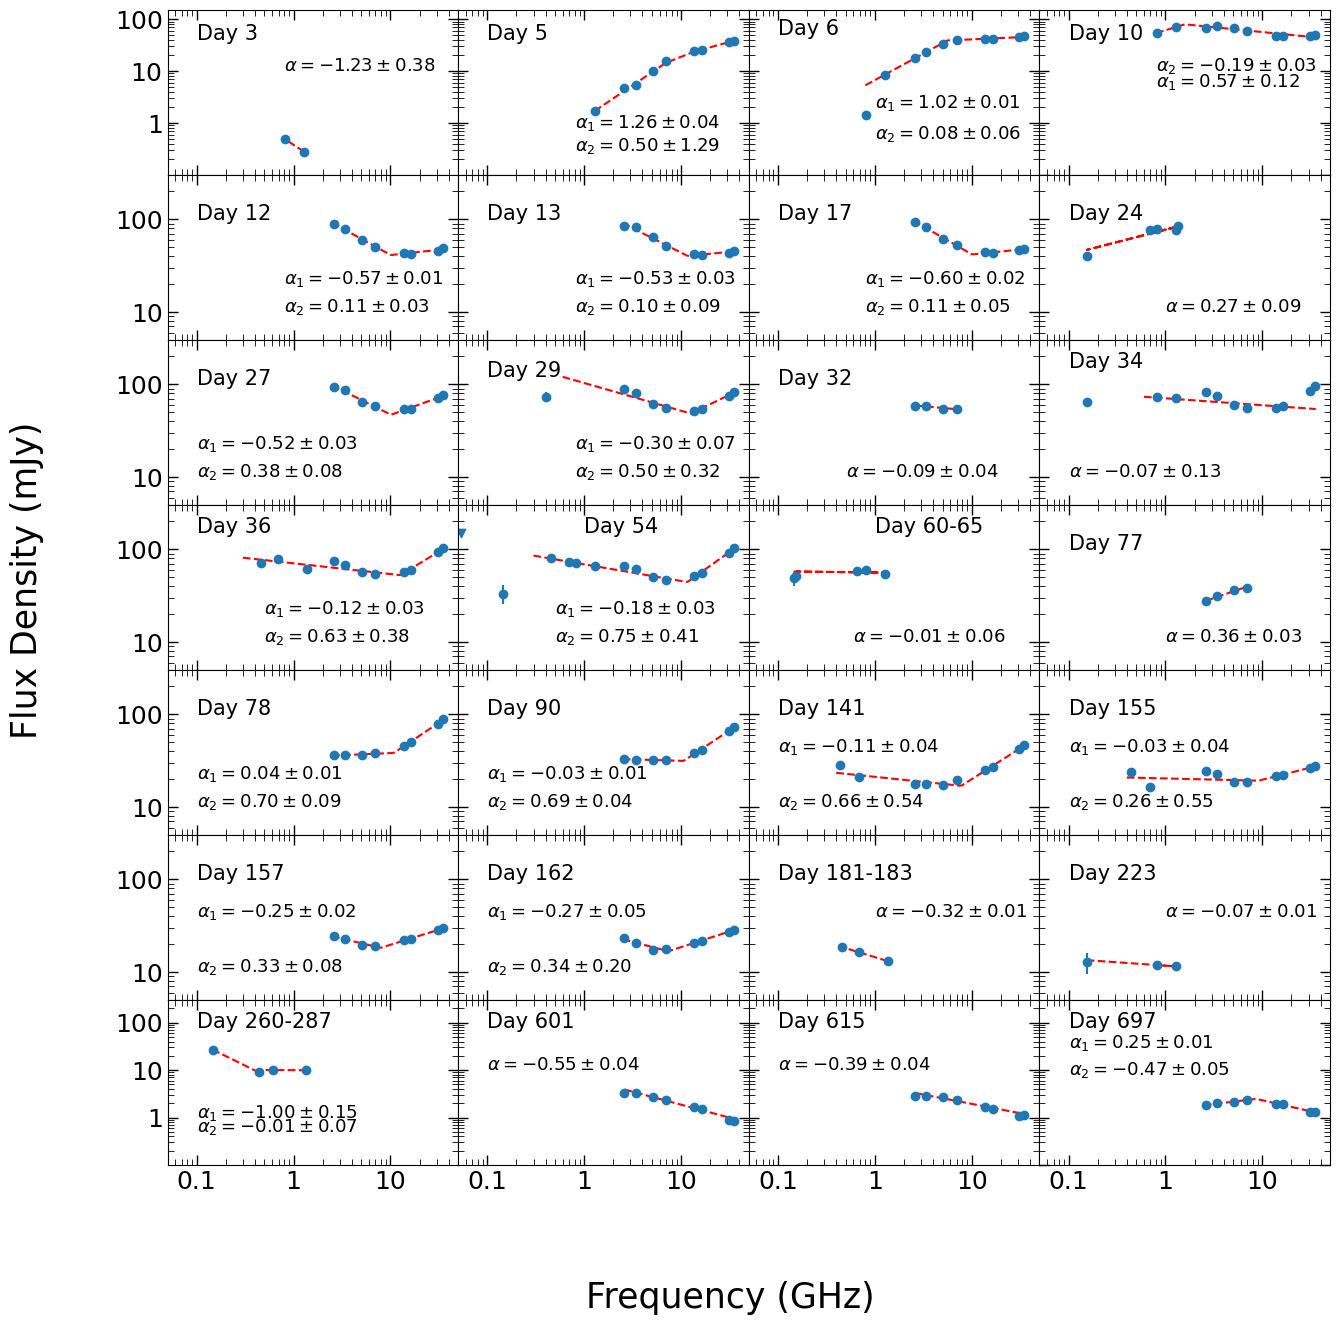

In [232]:
fig, ax = plt.subplots(7, 4)
fig.set_size_inches(15, 15)
fig.subplots_adjust(hspace=0, wspace=0)

#first row

mask2 = df0['Flux Density (mJy)'] < 3 * df0['Uncertainty (mJy)']  # apply non-detection threshold
mask = df0['Flux Density (mJy)'] > 3 * df0['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[0,0].errorbar(df0['Freq (GHz)'][mask], df0['Flux Density (mJy)'][mask], yerr= yerr0, fmt='o')
    ax[0,0].scatter(df0['Freq (GHz)'][mask2], (df0['Flux Density (mJy)'][mask2] + 3*df0['Uncertainty (mJy)'][mask2]), marker='v')
    ax[0,0].set_xscale('log')
    ax[0,0].set_yscale('log')

    ax[0,0].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[0,0].set_yticks([1, 10, 100], labels=[r'$1$',r'$10$',r'$100$'], fontsize=18)
    ax[0,0].set_ylim([0.1, 150])
    ax[0,0].set_xlim([0.05, 50])

    ax[0,0].annotate('Day 3', xy=(0.1, 40), fontsize=15)
    ax[0,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[0,0].tick_params(which='major', length=7, direction = 'in', width =1, left=True, labelleft=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
   
    ax[0,0].plot(df0['Freq (GHz)'][mask], fit_model_weights0(df0['Freq (GHz)'][mask]), 'r--')
    ax[0,0].annotate('${\u03B1 = -1.23 \\pm 0.38}$', xy=(0.8, 10), fontsize=13)


mask2 = df1['Flux Density (mJy)'] < 3 * df1['Uncertainty (mJy)']  # apply non-detection threshold
mask = df1['Flux Density (mJy)'] > 3 * df1['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[0,1].errorbar(df1['Freq (GHz)'][mask], df1['Flux Density (mJy)'][mask], yerr= yerr1, fmt='o')
    ax[0,1].scatter(df1['Freq (GHz)'][mask2], (df1['Flux Density (mJy)'][mask2] + 3*df1['Uncertainty (mJy)'][mask2]), marker='v')
    ax[0,1].set_xscale('log')
    ax[0,1].set_yscale('log')

    ax[0,1].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[0,1].set_yticks([1, 10, 100], labels=[r'$1$',r'$10$',r'$100$'], fontsize=18)
    ax[0,1].set_ylim([0.1, 150])
    ax[0,1].set_xlim([0.05, 50])
    
    ax[0,1].annotate('Day 5', xy=(0.1, 40), fontsize=15)
    ax[0,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[0,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, left=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[0,1].plot(df1['Freq (GHz)'][mask], fw_BPL1(df1['Freq (GHz)'][mask]), 'r--')
    ax[0,1].annotate('${\u03B1_1 = 1.26 \\pm 0.04}$', xy=(0.8, 0.8), fontsize=13)
    ax[0,1].annotate('${\u03B1_2 = 0.50 \\pm 1.29}$', xy=(0.8, 0.3), fontsize=13)


x_freq = np.arange(.8,36,0.1)
mask2 = df2['Flux Density (mJy)'] < 3 * df2['Uncertainty (mJy)']  # apply non-detection threshold
mask = df2['Flux Density (mJy)'] > 3 * df2['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[0,2].errorbar(df2['Freq (GHz)'][mask], df2['Flux Density (mJy)'][mask], yerr=yerr2, fmt='o')
    ax[0,2].scatter(df2['Freq (GHz)'][mask2], (df2['Flux Density (mJy)'][mask2] + 3*df2['Uncertainty (mJy)'][mask2]), marker='v')
    ax[0,2].set_xscale('log')
    ax[0,2].set_yscale('log')

    ax[0,2].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[0,2].set_yticks([1, 10, 100], labels=[r'$1$',r'$10$',r'$100$'], fontsize=18)
    ax[0,2].set_ylim([0.1, 150])
    ax[0,2].set_xlim([0.05, 50])
    
    ax[0,2].annotate('Day 6', xy=(0.1, 50), fontsize=15)
    ax[0,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[0,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True,left=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[0,2].plot(x_freq, fw_BPL2(x_freq), 'r--')
    ax[0,2].annotate('${\u03B1_1 = 1.02 \\pm 0.01}$', xy=(1, 2), fontsize=13)
    ax[0,2].annotate('${\u03B1_2 = 0.08 \\pm 0.06}$', xy=(1, 0.5), fontsize=13)
    
x_freq = np.arange(.8,36,0.1)
mask2 = df3['Flux Density (mJy)'] < 3 * df3['Uncertainty (mJy)']  # apply non-detection threshold
mask = df3['Flux Density (mJy)'] > 3 * df3['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[0,3].errorbar(df3['Freq (GHz)'][mask], df3['Flux Density (mJy)'][mask], yerr=yerr3, fmt='o')
    ax[0,3].scatter(df3['Freq (GHz)'][mask2], (df3['Flux Density (mJy)'][mask2] + 3*df3['Uncertainty (mJy)'][mask2]), marker='v')
    ax[0,3].set_xscale('log')
    ax[0,3].set_yscale('log')
    ax[0,3].set_ylim([0.1, 150])
    ax[0,3].set_xlim([0.05, 50])
    
    ax[0,3].annotate('Day 10', xy=(0.1, 40), fontsize=15)
    ax[0,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[0,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[0,3].plot(x_freq, fw_BPL3(x_freq), 'r--')
    ax[0,3].annotate('${\u03B1_1 = 0.57 \\pm 0.12}$', xy=(0.8, 5), fontsize=13)
    ax[0,3].annotate('${\u03B1_2 = -0.19 \\pm 0.03}$', xy=(0.8, 10), fontsize=13)



#second row

x_freq = np.arange(2.5,36,0.5)
mask2 = df4['Flux Density (mJy)'] < 3 * df4['Uncertainty (mJy)']  # apply non-detection threshold
mask = df4['Flux Density (mJy)'] > 3 * df4['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,0].errorbar(df4['Freq (GHz)'][mask], df4['Flux Density (mJy)'][mask], yerr=yerr4, fmt='o')
    ax[1,0].scatter(df4['Freq (GHz)'][mask2], (df4['Flux Density (mJy)'][mask2] + 3*df4['Uncertainty (mJy)'][mask2]), marker='v')
    ax[1,0].set_xscale('log')
    ax[1,0].set_yscale('log')

    ax[1,0].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'])
    ax[1,0].set_yticks([10, 100], labels=[ '10',  '100'], fontsize=18)
    ax[1,0].set_ylim([5, 300])
    ax[1,0].set_xlim([0.05, 50])

    ax[1,0].annotate('Day 12', xy=(0.1, 100), fontsize=15)
    ax[1,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[1,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[1,0].plot(x_freq, fw_BPL4(x_freq), 'r--')
    ax[1,0].annotate('${\u03B1_1 = -0.57 \\pm 0.01}$', xy=(0.8, 20), fontsize=13)
    ax[1,0].annotate('${\u03B1_2 = 0.11 \\pm 0.03}$', xy=(0.8, 10), fontsize=13)
    ax[1,0].tick_params(axis='both', which='both', direction='in', top=True, right=True)

x_freq = np.arange(2.5,36,0.5)
mask = df5['Flux Density (mJy)'] > 3 * df5['Uncertainty (mJy)']  # apply detection threshold
mask2 = df5['Flux Density (mJy)'] < 3 * df5['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,1].errorbar(df5['Freq (GHz)'][mask], df5['Flux Density (mJy)'][mask], yerr=yerr5, fmt='o')
    ax[1,1].scatter(df5['Freq (GHz)'][mask2], (df5['Flux Density (mJy)'][mask2] + 3*df5['Uncertainty (mJy)'][mask2]), marker='v')
    ax[1,1].set_xscale('log')
    ax[1,1].set_yscale('log')

    ax[1,1].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[1,1].set_yticks([10, 100], labels=['10',  '100'], fontsize=18)
    ax[1,1].set_ylim([5, 300])
    ax[1,1].set_xlim([0.05, 50])

    
    ax[1,1].annotate('Day 13', xy=(0.1, 100), fontsize=15)
    ax[1,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[1,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True,labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[1,1].plot(x_freq, fw_BPL5(x_freq), 'r--')
    ax[1,1].annotate('${\u03B1_1 = -0.53 \\pm 0.03}$', xy=(0.8, 20), fontsize=13)
    ax[1,1].annotate('${\u03B1_2 = 0.10 \\pm 0.09}$', xy=(0.8, 10), fontsize=13)

x_freq = np.arange(2.5,36,0.5) 
mask2 = df6['Flux Density (mJy)'] < 3 * df6['Uncertainty (mJy)']  # apply non-detection threshold
mask = df6['Flux Density (mJy)'] > 3 * df6['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,2].errorbar(df6['Freq (GHz)'][mask], df6['Flux Density (mJy)'][mask], yerr=yerr6, fmt='o')
    ax[1,2].scatter(df6['Freq (GHz)'][mask2], (df6['Flux Density (mJy)'][mask2] + 3*df6['Uncertainty (mJy)'][mask2]), marker='v')
    ax[1,2].set_xscale('log')
    ax[1,2].set_yscale('log')

    ax[1,2].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[1,2].set_yticks([10, 100], labels=[ '10',  '100'], fontsize=18)

    ax[1,2].set_ylim([5, 300])
    ax[1,2].set_xlim([0.05, 50])

    ax[1,2].annotate('Day 17', xy=(0.1, 100), fontsize=15)
    ax[1,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[1,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[1,2].plot(x_freq, fw_BPL6( x_freq ), 'r--')
    ax[1,2].annotate('${\u03B1_1 = -0.60 \\pm 0.02}$', xy=(0.8, 20),fontsize=13)
    ax[1,2].annotate('${\u03B1_2 = 0.11 \\pm 0.05}$', xy=(0.8, 10), fontsize=13)


x_freq = np.arange(2.5,36,0.5) 
mask2 = df6_5['Flux Density (mJy)'] < 3 * df6_5['Uncertainty (mJy)']  # apply non-detection threshold
mask = df6_5['Flux Density (mJy)'] > 3 * df6_5['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,3].errorbar(df6_5['Freq (GHz)'][mask], df6_5['Flux Density (mJy)'][mask], yerr=yerr6_5, fmt='o')
    ax[1,3].scatter(df6_5['Freq (GHz)'][mask2], (df6_5['Flux Density (mJy)'][mask2] + 3*df6_5['Uncertainty (mJy)'][mask2]), marker='v')
    ax[1,3].set_xscale('log')
    ax[1,3].set_yscale('log')
    
    ax[1,3].set_ylim([5, 300])
    ax[1,3].set_xlim([0.05, 50])

    
    ax[1,3].annotate('Day 24', xy=(0.1, 100), fontsize=15)
    ax[1,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[1,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[1,3].plot(df6_5['Freq (GHz)'][mask], fit_model_weights6_5(df6_5['Freq (GHz)'][mask]), 'r--')
    ax[1,3].annotate('${\u03B1 = 0.27 \\pm 0.09}$', xy=(1, 10),fontsize=13)


#third row
    
x_freq = np.arange(2.5,36,0.5) 
mask2 = df7['Flux Density (mJy)'] < 3 * df7['Uncertainty (mJy)']  # apply non-detection threshold
mask = df7['Flux Density (mJy)'] > 3 * df7['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,0].errorbar(df7['Freq (GHz)'][mask], df7['Flux Density (mJy)'][mask], yerr=yerr7, fmt='o')
    ax[2,0].scatter(df7['Freq (GHz)'][mask2], (df7['Flux Density (mJy)'][mask2] + 3*df7['Uncertainty (mJy)'][mask2]), marker='v')
    ax[2,0].set_xscale('log')
    ax[2,0].set_yscale('log')

    ax[2,0].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[2,0].set_yticks([10, 100], labels=[ '10', '100'], fontsize=18)
    ax[2,0].set_ylim([5, 300])
    ax[2,0].set_xlim([0.05, 50])

 
    
    ax[2,0].annotate('Day 27', xy=(0.1, 100), fontsize=15)
    ax[2,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[2,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[2,0].plot(x_freq, fw_BPL7(x_freq), 'r--')
    ax[2,0].annotate('${\u03B1_1 = -0.52 \\pm 0.03}$', xy=(0.1, 20), fontsize=13)
    ax[2,0].annotate('${\u03B1_2 = 0.38 \\pm 0.08}$', xy=(0.1, 10), fontsize=13)


x_freq = np.arange(.6,36,0.5)
mask2 = df8['Flux Density (mJy)'] < 3 * df8['Uncertainty (mJy)']  # apply non-detection threshold
mask = df8['Flux Density (mJy)'] > 3 * df8['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,1].errorbar(df8['Freq (GHz)'][mask], df8['Flux Density (mJy)'][mask], yerr=yerr8, fmt='o')
    ax[2,1].scatter(df8['Freq (GHz)'][mask2], (df8['Flux Density (mJy)'][mask2] + 3*df8['Uncertainty (mJy)'][mask2]), marker='v')
    ax[2,1].set_xscale('log')
    ax[2,1].set_yscale('log')

    ax[2,1].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'])
    ax[2,1].set_yticks([ 10, 100], labels=[ '10',  '100'], fontsize=18)
    ax[2,1].set_ylim([5, 300])
    ax[2,1].set_xlim([0.05, 50])

 
    
    ax[2,1].annotate('Day 29', xy=(0.1, 120), fontsize=15)
    ax[2,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[2,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[2,1].plot(x_freq, fw_BPL8(x_freq), 'r--')
    ax[2,1].annotate('${\u03B1_1 = -0.30 \\pm 0.07}$', xy=(0.8, 20), fontsize=13)
    ax[2,1].annotate('${\u03B1_2 = 0.50 \\pm 0.32}$', xy=(0.8, 10), fontsize=13)


mask = df9['Flux Density (mJy)'] > 3 * df9['Uncertainty (mJy)']  # apply detection threshold
mask2 = df9['Flux Density (mJy)'] < 3 * df9['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,2].errorbar(df9['Freq (GHz)'][mask], df9['Flux Density (mJy)'][mask], yerr=yerr9, fmt='o')
    ax[2,2].scatter(df9['Freq (GHz)'][mask2], (df9['Flux Density (mJy)'][mask2] + 3*df9['Uncertainty (mJy)'][mask2]), marker='v')
    ax[2,2].set_xscale('log')
    ax[2,2].set_yscale('log')

    ax[2,2].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[2,2].set_yticks([10, 100], labels=['10',  '100'], fontsize=18)
    ax[2,2].set_ylim([5, 300])
    ax[2,2].set_xlim([0.05, 50])

     
    ax[2,2].annotate('Day 32', xy=(0.1,100),fontsize=15)
    ax[2,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[2,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True,labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[2,2].plot(df9['Freq (GHz)'][mask], fit_model_weights9(df9['Freq (GHz)'][mask]), 'r--')
    ax[2,2].annotate('${\u03B1 = -0.09 \\pm 0.04}$', xy=(0.5, 10), fontsize=13)

mask = df10['Flux Density (mJy)'] > 3 * df10['Uncertainty (mJy)']  # apply detection threshold
mask2 = df10['Flux Density (mJy)'] < 3 * df10['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,3].errorbar(df10['Freq (GHz)'][mask], df10['Flux Density (mJy)'][mask], yerr=yerr10, fmt='o')
    ax[2,3].scatter(df10['Freq (GHz)'][mask2], (df10['Flux Density (mJy)'][mask2] + 3*df10['Uncertainty (mJy)'][mask2]), marker='v')
    ax[2,3].set_xscale('log')
    ax[2,3].set_yscale('log')
    ax[2,3].set_ylim([5, 300])
    ax[2,3].set_xlim([0.05, 50])

    ax[2,3].plot(x_freq, fit_model_weights10(x_freq), 'r--')

    ax[2,3].annotate('Day 34', xy=(0.1, 150), fontsize=15)
    ax[2,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[2,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False,labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[2,3].annotate('${\u03B1 = -0.07 \\pm 0.13}$', xy=(0.1, 10),fontsize=13)




#row four
x_freq = np.arange(.3,36,0.5)
mask2 = df11['Flux Density (mJy)'] < 3 * df11['Uncertainty (mJy)']  # apply non-detection threshold
mask = df11['Flux Density (mJy)'] > 3 * df11['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[3,0].errorbar(df11['Freq (GHz)'][mask], df11['Flux Density (mJy)'][mask], yerr=yerr11, fmt='o')
    ax[3,0].scatter(df11['Freq (GHz)'][mask2], (df11['Flux Density (mJy)'][mask2] + 3*df11['Uncertainty (mJy)'][mask2]), marker='v')
    ax[3,0].set_xscale('log')
    ax[3,0].set_yscale('log')

    ax[3,0].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'])
    ax[3,0].set_yticks([10, 100], labels=['10',  '100'], fontsize=18)
    ax[3,0].set_ylim([5, 300])
    ax[3,0].set_xlim([0.05, 50])

 
    ax[3,0].annotate('Day 36', xy=(0.1, 150), fontsize=15)
    ax[3,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[3,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[3,0].plot(x_freq, fw_BPL11(x_freq), 'r--')
    ax[3,0].annotate('${\u03B1_1 = -0.12 \\pm 0.03}$', xy=(0.5, 20), fontsize=13)
    ax[3,0].annotate('${\u03B1_2 = 0.63 \\pm 0.38}$', xy=(0.5, 10), fontsize=13)


x_freq = np.arange(.3,36,0.5)  
mask2 = df12['Flux Density (mJy)'] < 3 * df12['Uncertainty (mJy)']  # apply non-detection threshold
mask = df12['Flux Density (mJy)'] > 3 * df12['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[3,1].errorbar(df12['Freq (GHz)'][mask], df12['Flux Density (mJy)'][mask], yerr= yerr12 , fmt='o')
    ax[3,1].scatter(df12['Freq (GHz)'][mask2], (df12['Flux Density (mJy)'][mask2] + 3*df12['Uncertainty (mJy)'][mask2]), marker='v')
    ax[3,1].set_xscale('log')
    ax[3,1].set_yscale('log')

    ax[3,1].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'])
    ax[3,1].set_yticks([10, 100], labels=['10',  '100'], fontsize=18)
    ax[3,1].set_ylim([5, 300])
    ax[3,1].set_xlim([0.05, 50])

    ax[3,1].annotate('Day 54', xy=(1, 150), fontsize=15)
    ax[3,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[3,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[3,1].plot(x_freq, fw_BPL12(x_freq), 'r--')
    ax[3,1].annotate('${\u03B1_1 = -0.18 \\pm 0.03}$', xy=(0.5, 20), fontsize=13)
    ax[3,1].annotate('${\u03B1_2 = 0.75 \\pm 0.41}$', xy=(0.5, 10), fontsize=13)


x_freq = np.arange(0.1,2,0.5)
mask = df12_5['Flux Density (mJy)'] > 3 * df12_5['Uncertainty (mJy)']  # apply detection threshold
mask2 = df12_5['Flux Density (mJy)'] < 3 * df12_5['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[3,2].errorbar(df12_5['Freq (GHz)'][mask], df12_5['Flux Density (mJy)'][mask], yerr= yerr12_5 , fmt='o')
    ax[3,2].scatter(df12_5['Freq (GHz)'][mask2], (df12_5['Flux Density (mJy)'][mask2] + 3*df12_5['Uncertainty (mJy)'][mask2]), marker='v')
    ax[3,2].set_xscale('log')
    ax[3,2].set_yscale('log')

    ax[3,2].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'])
    ax[3,2].set_yticks([10, 100], labels=[ '10',  '100'], fontsize=18)
    ax[3,2].set_ylim([5, 300])
    ax[3,2].set_xlim([0.05, 50])
    
    ax[3,2].annotate('Day 60-65', xy=(1, 150), fontsize=15)
    ax[3,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[3,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False ,labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[3,2].plot(df12_5['Freq (GHz)'][mask], fit_model_weights12_5(df12_5['Freq (GHz)'][mask]), 'r--')
    ax[3,2].annotate('${\u03B1 = -0.01 \\pm 0.06}$', xy=(0.6, 10), fontsize=13)

mask = df13['Flux Density (mJy)'] > 3 * df13['Uncertainty (mJy)']  # apply detection threshold
mask2 = df13['Flux Density (mJy)'] < 3 * df13['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[3,3].errorbar(df13['Freq (GHz)'][mask], df13['Flux Density (mJy)'][mask], yerr=yerr13, fmt='o')
    ax[3,3].scatter(df13['Freq (GHz)'][mask2], (df13['Flux Density (mJy)'][mask2] + 3*df13['Uncertainty (mJy)'][mask2]), marker='v')
    ax[3,3].set_xscale('log')   
    ax[3,3].set_yscale('log')

    ax[3,3].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[3,3].set_yticks([10,  100], labels=[ '10',  '100'], fontsize=18)

    ax[3,3].set_ylim([5, 300])
    ax[3,3].set_xlim([0.05, 50])

    ax[3,3].annotate('Day 77', xy=(0.1, 100), fontsize=15)
    ax[3,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[3,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True,labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[3,3].plot(df13['Freq (GHz)'][mask], fit_model_weights13(df13['Freq (GHz)'][mask]), 'r--')
    ax[3,3].annotate('${\u03B1 = 0.36 \\pm 0.03}$', xy=(1, 10), fontsize=13)



#fifth row
x_freq = np.arange(2.5,36,0.5)
mask2 = df14['Flux Density (mJy)'] < 3 * df14['Uncertainty (mJy)']  # apply non-detection threshold
mask = df14['Flux Density (mJy)'] > 3 * df14['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[4,0].errorbar(df14['Freq (GHz)'][mask], df14['Flux Density (mJy)'][mask], yerr=yerr14, fmt='o')
    ax[4,0].scatter(df14['Freq (GHz)'][mask2], (df14['Flux Density (mJy)'][mask2] + 3*df14['Uncertainty (mJy)'][mask2]), marker='v')
    ax[4,0].set_xscale('log')
    ax[4,0].set_yscale('log')

    ax[4,0].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'])
    ax[4,0].set_yticks([10, 100], labels=['10', '100'], fontsize=18)
    ax[4,0].set_ylim([5, 300])
    ax[4,0].set_xlim([0.05, 50])
    
    ax[4,0].annotate('Day 78', xy=(0.1, 100), fontsize=15)
    ax[4,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[4,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[4,0].plot(x_freq, fw_BPL14(x_freq), 'r--')
    ax[4,0].annotate('${\u03B1_1 = 0.04 \\pm 0.01}$', xy=(0.1, 20), fontsize=13)
    ax[4,0].annotate('${\u03B1_2 = 0.70 \\pm 0.09}$', xy=(0.1, 10), fontsize=13)


x_freq = np.arange(2.5,36,0.5)
mask2 = df15['Flux Density (mJy)'] < 3 * df15['Uncertainty (mJy)']  # apply non-detection threshold
mask = df15['Flux Density (mJy)'] > 3 * df15['Uncertainty (mJy)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[4,1].errorbar(df15['Freq (GHz)'][mask], df15['Flux Density (mJy)'][mask], yerr=yerr15, fmt='o')
    ax[4,1].scatter(df15['Freq (GHz)'][mask2], (df15['Flux Density (mJy)'][mask2] + 3*df15['Uncertainty (mJy)'][mask2]), marker='v')
    ax[4,1].set_xscale('log')
    ax[4,1].set_yscale('log')

    ax[4,1].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'])
    ax[4,1].set_yticks([10, 100], labels=[ '10',  '100'], fontsize=18)
    ax[4,1].set_ylim([5, 300])
    ax[4,1].set_xlim([0.05, 50])
    
    ax[4,1].annotate('Day 90', xy=(0.1,100), fontsize=15)
    ax[4,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[4,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[4,1].plot(x_freq, fw_BPL15(x_freq), 'r--')
    ax[4,1].annotate('${\u03B1_1 = -0.03 \\pm 0.01}$', xy=(0.1, 20), fontsize=13)
    ax[4,1].annotate('${\u03B1_2 = 0.69 \\pm 0.04}$', xy=(0.1, 10), fontsize=13)
   
     
x_freq = np.arange(.4,36,0.5)
mask = df16['Flux Density (mJy)'] > 3 * df16['Uncertainty (mJy)']  # apply detection threshold
mask2 = df16['Flux Density (mJy)'] < 3 * df16['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[4,2].errorbar(df16['Freq (GHz)'][mask], df16['Flux Density (mJy)'][mask], yerr=yerr16, fmt='o')
    ax[4,2].scatter(df16['Freq (GHz)'][mask2], (df16['Flux Density (mJy)'][mask2] + 3*df16['Uncertainty (mJy)'][mask2]), marker='v')
    ax[4,2].set_xscale('log')
    ax[4,2].set_yscale('log')

    ax[4,2].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'])
    ax[4,2].set_yticks([10,  100], labels=['10',  '100'], fontsize=18)
    ax[4,2].set_ylim([5, 300])
    ax[4,2].set_xlim([0.05, 50])
    
    ax[4,2].annotate('Day 141', xy=(0.1, 100), fontsize=15)
    ax[4,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False,labelleft=False,  bottom=True, labelbottom=False, right = True,labelright = False)
    ax[4,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[4,2].plot(x_freq , fw_BPL16(x_freq ), 'r--')
    ax[4,2].annotate('${\u03B1_1 = -0.11 \\pm 0.04}$', xy=(0.1, 40), fontsize=13)
    ax[4,2].annotate('${\u03B1_2 = 0.66 \\pm 0.54}$', xy=(0.1, 10), fontsize=13)

mask = df17['Flux Density (mJy)'] > 3 * df17['Uncertainty (mJy)']  # apply detection threshold
mask2 = df17['Flux Density (mJy)'] < 3 * df17['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[4,3].errorbar(df17['Freq (GHz)'][mask], df17['Flux Density (mJy)'][mask], yerr=yerr17, fmt='o')
    ax[4,3].scatter(df17['Freq (GHz)'][mask2], (df17['Flux Density (mJy)'][mask2] + 3*df17['Uncertainty (mJy)'][mask2]), marker='v')
    ax[4,3].set_xscale('log')
    ax[4,3].set_yscale('log')
    ax[4,3].set_ylim([5, 300])
    ax[4,3].set_xlim([0.05, 50])
    
    ax[4,3].annotate('Day 155', xy=(0.1, 100), fontsize=15)
    ax[4,3].tick_params(which='minor', length =4, direction = 'in', top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[4,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[4,3].plot(x_freq, fw_BPL17(x_freq), 'r--')
    ax[4,3].annotate('${\u03B1_1 = -0.03 \\pm 0.04}$', xy=(0.1, 40), fontsize=13)
    ax[4,3].annotate('${\u03B1_2 = 0.26 \\pm 0.55}$', xy=(0.1, 10), fontsize=13)

#row 6
x_freq = np.arange(2.5,36,0.5)
mask = df18['Flux Density (mJy)'] > 3 * df18['Uncertainty (mJy)']  # apply detection threshold
mask2 = df18['Flux Density (mJy)'] < 3 * df18['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[5,0].errorbar(df18['Freq (GHz)'][mask], df18['Flux Density (mJy)'][mask], yerr=yerr18, fmt='o')
    ax[5,0].scatter(df18['Freq (GHz)'][mask2], (df18['Flux Density (mJy)'][mask2] + 3*df18['Uncertainty (mJy)'][mask2]), marker='v')
    ax[5,0].set_xscale('log')
    ax[5,0].set_yscale('log')

    ax[5,0].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[5,0].set_yticks([10, 100], labels=['10', '100'], fontsize=18)
    ax[5,0].set_ylim([5, 300])
    ax[5,0].set_xlim([0.05, 50])
    
    ax[5,0].annotate('Day 157', xy=(0.1, 100), fontsize=15)
    ax[5,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[5,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[5,0].plot(x_freq, fw_BPL18(x_freq), 'r--')
    ax[5,0].annotate('${\u03B1_1 = -0.25 \\pm 0.02}$', xy=(0.1, 40), fontsize=13)
    ax[5,0].annotate('${\u03B1_2 = 0.33 \\pm 0.08}$', xy=(0.1, 10), fontsize=13)

#row 6     
x_freq = np.arange(2.5,36,0.5)
mask = df19['Flux Density (mJy)'] > 3 * df19['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19['Flux Density (mJy)'] < 3 * df19['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[5,1].errorbar(df19['Freq (GHz)'][mask], df19['Flux Density (mJy)'][mask], yerr=yerr19, fmt='o')
    ax[5,1].scatter(df19['Freq (GHz)'][mask2], (df19['Flux Density (mJy)'][mask2] + 3*df19['Uncertainty (mJy)'][mask2]), marker='v')
    ax[5,1].set_xscale('log')
    ax[5,1].set_yscale('log')

    ax[5,1].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[5,1].set_yticks([10, 100], labels=['10',  '100'], fontsize=18)
    ax[5,1].set_ylim([5, 300])
    ax[5,1].set_xlim([0.05, 50])
    
    ax[5,1].annotate('Day 162', xy=(0.1, 100), fontsize=15)
    ax[5,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[5,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[5,1].plot(x_freq, fw_BPL19( x_freq ), 'r--')
    ax[5,1].annotate('${\u03B1_1 = -0.27 \\pm 0.05}$', xy=(0.1, 40), fontsize=13)
    ax[5,1].annotate('${\u03B1_2 = 0.34 \\pm 0.20}$', xy=(0.1, 10), fontsize=13)

x_freq = np.arange(2.5,36,0.5)
mask = df19['Flux Density (mJy)'] > 3 * df19['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19['Flux Density (mJy)'] < 3 * df19['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[5,2].errorbar(df19_1['Freq (GHz)'][mask], df19_1['Flux Density (mJy)'][mask], yerr=yerr19_1, fmt='o')
    ax[5,2].scatter(df19_1['Freq (GHz)'][mask2], (df19_1['Flux Density (mJy)'][mask2] + 3*df19_1['Uncertainty (mJy)'][mask2]), marker='v')
    ax[5,2].set_xscale('log')
    ax[5,2].set_yscale('log')

    ax[5,2].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[5,2].set_yticks([10, 100], labels=['10',  '100'], fontsize=18)
    ax[5,2].set_ylim([5, 300])
    ax[5,2].set_xlim([0.05, 50])
    
    ax[5,2].annotate('Day 181-183', xy=(0.1, 100), fontsize=15)
    ax[5,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[5,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[5,2].plot(df19_1['Freq (GHz)'][mask], fit_model_weights19_1(df19_1['Freq (GHz)'][mask]), 'r--')
    ax[5,2].annotate('${\u03B1 = -0.32 \\pm 0.01}$', xy=(1, 40), fontsize=13)

x_freq = np.arange(2.5,36,0.5)
mask = df19['Flux Density (mJy)'] > 3 * df19['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19['Flux Density (mJy)'] < 3 * df19['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[5,3].errorbar(df19_2['Freq (GHz)'][mask], df19_2['Flux Density (mJy)'][mask], yerr=yerr19_2, fmt='o')
    ax[5,3].scatter(df19_2['Freq (GHz)'][mask2], (df19_2['Flux Density (mJy)'][mask2] + 3*df19_2['Uncertainty (mJy)'][mask2]), marker='v')
    ax[5,3].set_xscale('log')
    ax[5,3].set_yscale('log')
    ax[5,3].set_ylim([5, 300])
    ax[5,3].set_xlim([0.05, 50])
    
    ax[5,3].annotate('Day 223', xy=(0.1, 100), fontsize=15)
    ax[5,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[5,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True,labelleft=False,  labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)
    ax[5,3].plot(df19_2['Freq (GHz)'][mask], fit_model_weights19_2(df19_2['Freq (GHz)'][mask]), 'r--')
    ax[5,3].annotate('${\u03B1 = -0.07 \\pm 0.01}$', xy=(1, 40), fontsize=13)



    
#row 7

x_freq = np.arange(0.15,2,0.5)
mask = df19['Flux Density (mJy)'] > 3 * df19['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19['Flux Density (mJy)'] < 3 * df19['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[6,0].errorbar(df19_3['Freq (GHz)'][mask], df19_3['Flux Density (mJy)'][mask], yerr=yerr19_3, fmt='o')
    ax[6,0].scatter(df19_3['Freq (GHz)'][mask2], (df19_3['Flux Density (mJy)'][mask2] + 3*df19_3['Uncertainty (mJy)'][mask2]), marker='v')
    ax[6,0].set_xscale('log')
    ax[6,0].set_yscale('log')

    ax[6,0].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[6,0].set_yticks([1, 10, 100], labels=['1', '10',  '100'], fontsize=18)
    ax[6,0].set_ylim([0.1, 300])
    ax[6,0].set_xlim([0.05, 50])
    
    ax[6,0].annotate('Day 260-287', xy=(0.1, 80), fontsize=15)
    ax[6,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[6,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
    ax[6,0].plot(xB, fit_model_weightsB(xB), 'r--')
    ax[6,0].plot(xA, fit_model_weightsA(xA), 'r--')
    ax[6,0].annotate('${\u03B1_1 = -1.00 \\pm 0.15}$', xy=(0.1, 1), fontsize=13)
    ax[6,0].annotate('${\u03B1_2 = -0.01 \\pm 0.07}$', xy=(0.1, 0.5), fontsize=13)
    


     
mask = df20['Flux Density (mJy)'] > 3 * df20['Uncertainty (mJy)']  # apply detection threshold
mask2 = df20['Flux Density (mJy)'] < 3 * df20['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[6,1].errorbar(df20['Freq (GHz)'][mask], df20['Flux Density (mJy)'][mask], yerr=yerr20, fmt='o')
    ax[6,1].scatter(df20['Freq (GHz)'][mask2], (df20['Flux Density (mJy)'][mask2] + 3*df20['Uncertainty (mJy)'][mask2]), marker='v')
    ax[6,1].set_xscale('log')
    ax[6,1].set_yscale('log')

    ax[6,1].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[6,1].set_yticks([1, 10, 100], labels=['1', '10',  '100'], fontsize=18)
    ax[6,1].set_ylim([0.1, 300])
    ax[6,1].set_xlim([0.05, 50])
    
    ax[6,1].annotate('Day 601', xy=(0.1, 80), fontsize=15)
    ax[6,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[6,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
    ax[6,1].plot(df20['Freq (GHz)'][mask], fit_model_weights20(df20['Freq (GHz)'][mask]), 'r--')
    ax[6,1].annotate('${\u03B1 = -0.55 \\pm 0.04}$', xy=(0.1, 10), fontsize=13)

     

mask = df21['Flux Density (mJy)'] > 3 * df21['Uncertainty (mJy)']  # apply detection threshold
mask2 = df21['Flux Density (mJy)'] < 3 * df21['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[6,2].errorbar(df21['Freq (GHz)'][mask], df21['Flux Density (mJy)'][mask], yerr=yerr21, fmt='o')
    ax[6,2].scatter(df21['Freq (GHz)'][mask2], (df21['Flux Density (mJy)'][mask2] + 3*df21['Uncertainty (mJy)'][mask2]), marker='v')
    ax[6,2].set_xscale('log')
    ax[6,2].set_yscale('log')

    ax[6,2].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[6,2].set_yticks([1, 10, 100], labels=['1', '10', '100'], fontsize=18)
    ax[6,2].set_ylim([0.1, 300])
    ax[6,2].set_xlim([0.05, 50])
    
    ax[6,2].annotate('Day 615', xy=(0.1, 80), fontsize=15)
    ax[6,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[6,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
    ax[6,2].plot(df21['Freq (GHz)'][mask], fit_model_weights21(df21['Freq (GHz)'][mask]), 'r--')
    ax[6,2].annotate('${\u03B1 = -0.39 \\pm 0.04}$', xy=(0.1, 10), fontsize=13)

   
x_freq = np.arange(2.5,36,0.5)
mask = df22['Flux Density (mJy)'] > 3 * df22['Uncertainty (mJy)']  # apply detection threshold
mask2 = df22['Flux Density (mJy)'] < 3 * df22['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax[6,3].errorbar(df22['Freq (GHz)'][mask], df22['Flux Density (mJy)'][mask], yerr=yerr22, fmt='o')
    ax[6,3].scatter(df22['Freq (GHz)'][mask2], (df22['Flux Density (mJy)'][mask2] + 3*df22['Uncertainty (mJy)'][mask2]), marker='v')
    ax[6,3].set_xscale('log')
    ax[6,3].set_yscale('log')

    ax[6,3].set_xticks([0.1, 1, 10], labels=['0.1', '1', '10'], fontsize=18)
    ax[6,3].set_ylim([0.1, 300])
    ax[6,3].set_xlim([0.05, 50])

    ax[6,3].annotate('Day 697', xy=(0.1, 80), fontsize=15)
    ax[6,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
    ax[6,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labelleft=False, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)#
    ax[6,3].plot(x_freq, fw_BPL22(x_freq), 'r--')
    ax[6,3].annotate('${\u03B1_1 = 0.25 \\pm 0.01}$', xy=(0.1, 30), fontsize=13)
    ax[6,3].annotate('${\u03B1_2 = -0.47 \\pm 0.05}$', xy=(0.1, 8), fontsize=13)



fig.supxlabel("Frequency (GHz)", fontsize =25)
fig.supylabel("Flux Density (mJy)", fontsize=25)

plt.savefig("RS_SI.png")

plt.show();

